In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.stats import weightstats
from statsmodels.graphics.tsaplots import plot_acf
from statsmodels.tsa.stattools import adfuller
import statsmodels.api as sm
from scipy.stats import ttest_ind, f_oneway
from statsmodels.formula.api import ols
from scipy.stats import zscore
import warnings
warnings.filterwarnings("ignore")

## RQ1: What are the high-risk (high propagation costs) packages created in the source and build stages when considering OSS supply-chain risk through models of network propagation?


**bold text**## Source Phase Analysis

In [ ]:
ind_df = pd.read_csv('/content/indegree-source.csv',header=0)
# publish_df = pd.read_csv('/Users/sahithikasim/Downloads/thesis/publish_sections.csv',header=0)
pop_df = pd.read_csv('/content/popularity.csv',header=0)
# path_df = pd.read_csv('/Users/sahithikasim/Downloads/thesis/longest_paths_with_packages.csv', header=0)
path_df = pd.read_csv('/content/path_length-source.csv', header=0)
attack_df = pd.read_csv('/content/attack_radius-source.csv', header=0)
bet_df = pd.read_csv('/content/betweenness_centrality-source.csv', header=0)
core_df = pd.read_csv('/content/k_core_index-source.csv', header=0)
vuln_df = pd.read_csv('/content/past_vulnerable_packages.csv', header=0)

In [ ]:
print(ind_df.shape)
print(path_df.shape)
print(bet_df.shape)
print(core_df.shape)
print(attack_df.shape)
print(pop_df.shape)
print(vuln_df.shape)

(44286, 2)
(44286, 2)
(44286, 2)
(44286, 2)
(44286, 2)
(196176, 8)
(3539, 1)


In [ ]:
print(ind_df.head())
print(path_df.head())
print(bet_df.head())
print(core_df.head())
print(attack_df.head())


                 Node  In-Degree
0    debhelper-compat      15697
1           debhelper      11037
2           dh-python       3916
3  python3-setuptools       3027
4         python3-all       2663
               Node  Path Length
0   ruby-asset-sync           65
1  ruby-carrierwave           64
2          ruby-fog           64
3    ruby-airbrussh           62
4            itamae           62
           Node  Betweenness Centrality
0       courier                0.000000
1       debconf                0.000008
2   ghostscript                0.000173
3  courier-base                0.000000
4   courier-mta                0.000000
           Node  K-Core Index
0       courier            11
1       debconf            15
2   ghostscript            13
3  courier-base             1
4   courier-mta             2
                              Node  Attack Radius
0           dpkg-source-gitarchive             15
1                     sparkleshare             14
2                            aasvg

In [ ]:
print(pop_df.head())
print(vuln_df.head())

   rank     name    inst    vote   old  recent  no-files  \
0     1  adduser  234785  211590  4924   18233        38   
1     2  libacl1  234785  214251  2906   17588        40   
2     3      tar  234785  213292  3464   17986        43   
3     4   passwd  234784  213145  3410   18191        38   
4     5  debconf  234782  214125  2631   17996        30   

                   maintainer  
0   Debian Adduser Developers  
1               Guillem Jover  
2                Janos Lenart  
3  Shadow Package Maintainers  
4          Debconf Developers  
      Packages
0  389-ds-base
1         7zip
2        9base
3         a2ps
4      abcm2ps


### Data Cleaning

In [ ]:
# Initialize combined_df with the index of attack_df and fill with 0s
combined_df = attack_df.copy()

# Merge each dataframe into combined_df
combined_df = combined_df.merge(ind_df, on='Node', how='left').fillna(0)
combined_df = combined_df.merge(path_df, on='Node', how='left').fillna(0)
combined_df = combined_df.merge(bet_df, on='Node', how='left').fillna(0)
combined_df = combined_df.merge(core_df, on='Node', how='left').fillna(0)

print(combined_df.shape)
print(combined_df.head())

(44286, 6)
                              Node  Attack Radius  In-Degree  Path Length  \
0           dpkg-source-gitarchive             15          0         53.0   
1                     sparkleshare             14          0         52.0   
2                            aasvg             14          0         51.0   
3  ruby-rails-deprecated-sanitizer             14          1         52.0   
4         ruby-kramdown-parser-gfm             14          2         51.0   

   Betweenness Centrality  K-Core Index  
0            0.000000e+00           4.0  
1            0.000000e+00           6.0  
2            0.000000e+00           6.0  
3            8.413573e-09           6.0  
4            1.019827e-09           6.0  


In [ ]:
# Clean the DataFrame
combined_df['Node'] = combined_df['Node'].str.replace('"', '').str.strip()

### Descriptive Analysis of Build Data

In [ ]:
combined_df.describe()

,Attack Radius,In-Degree,Path Length,Betweenness Centrality,K-Core Index
count,44286.000000,44286.000000,44286.000000,4.428600e+04,44286.000000
mean,3.498713,4.092580,5.658944,7.973280e-08,4.217247
std,3.440054,99.385364,8.898911,3.685275e-06,3.601910
min,0.000000,0.000000,0.000000,0.000000e+00,0.000000
25%,0.000000,0.000000,0.000000,0.000000e+00,1.000000
50%,1.000000,1.000000,2.000000,0.000000e+00,3.000000
75%,7.000000,1.000000,7.000000,0.000000e+00,6.000000
max,15.000000,15697.000000,65.000000,5.220093e-04,21.000000


In [ ]:
# Select columns with numerical data
numerical_columns = combined_df.select_dtypes(include=['int', 'float']).columns

# Calculate median for numerical columns
numerical_medians = combined_df[numerical_columns].median()

# Display the median values for numerical columns
print("Median values for numerical columns:")
print(numerical_medians)


Median values for numerical columns:
Attack Radius             1.0
In-Degree                 1.0
Path Length               2.0
Betweenness Centrality    0.0
K-Core Index              3.0
dtype: float64


### Data Visualizations

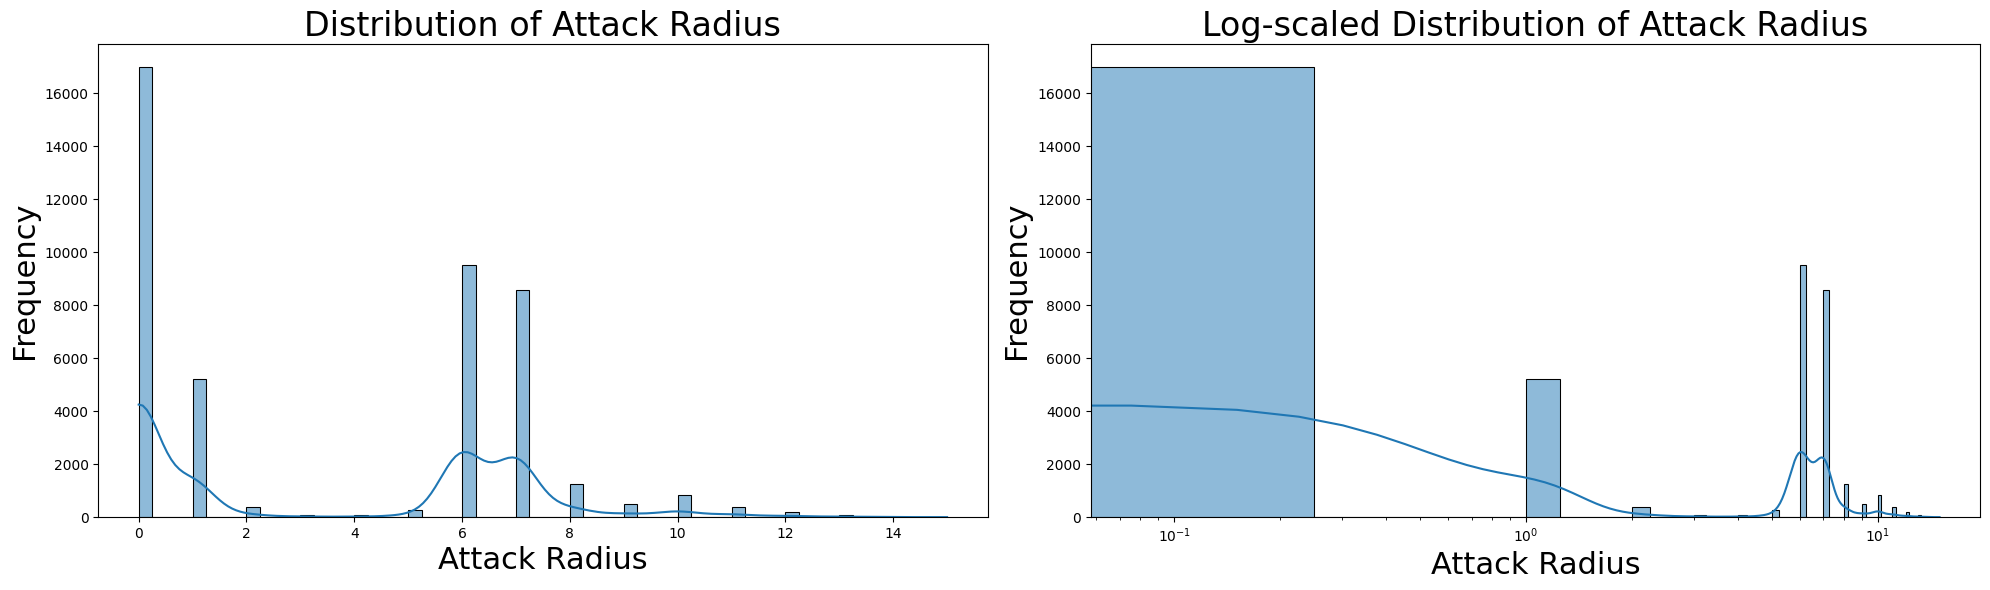

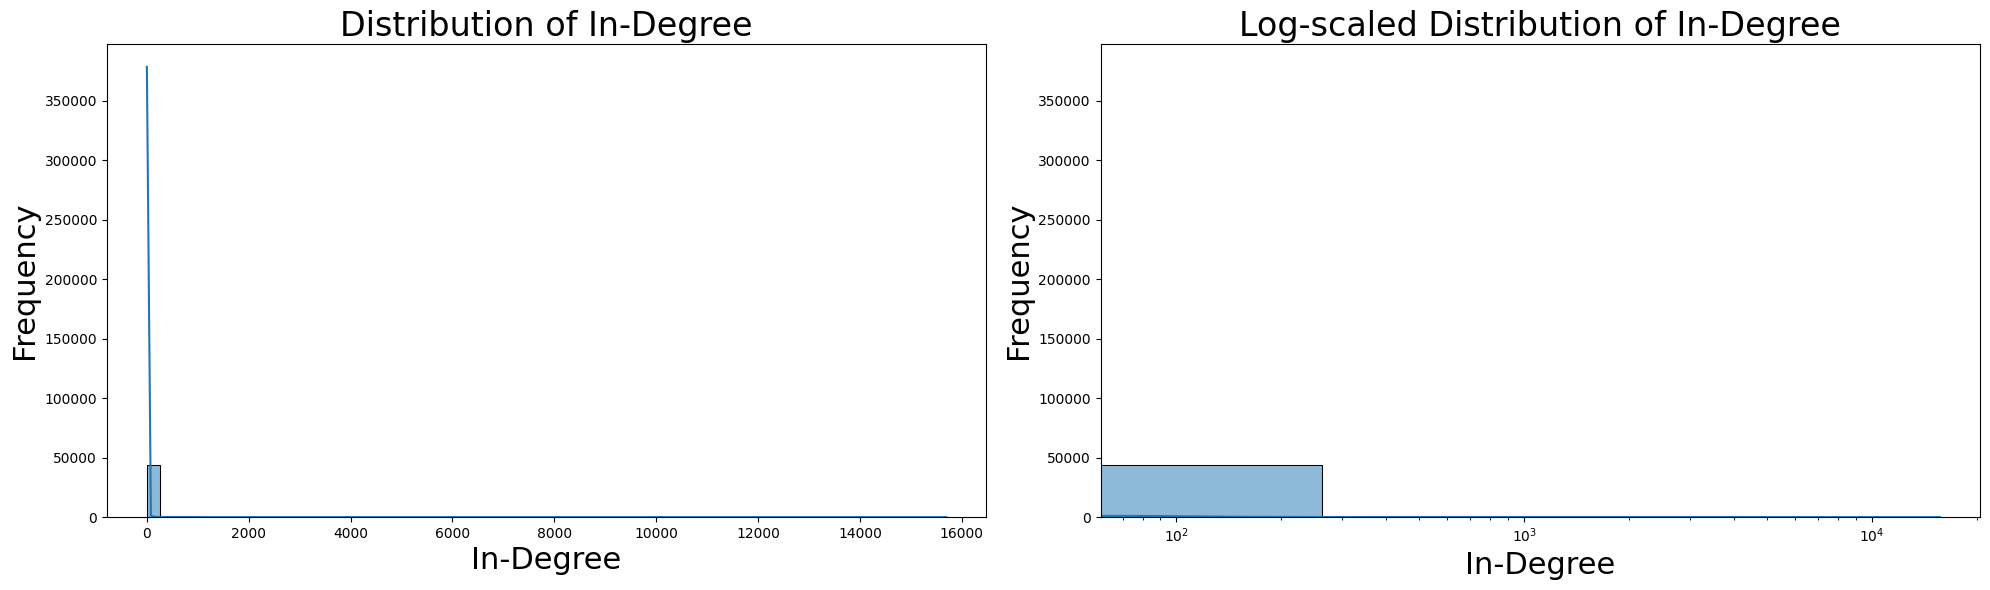

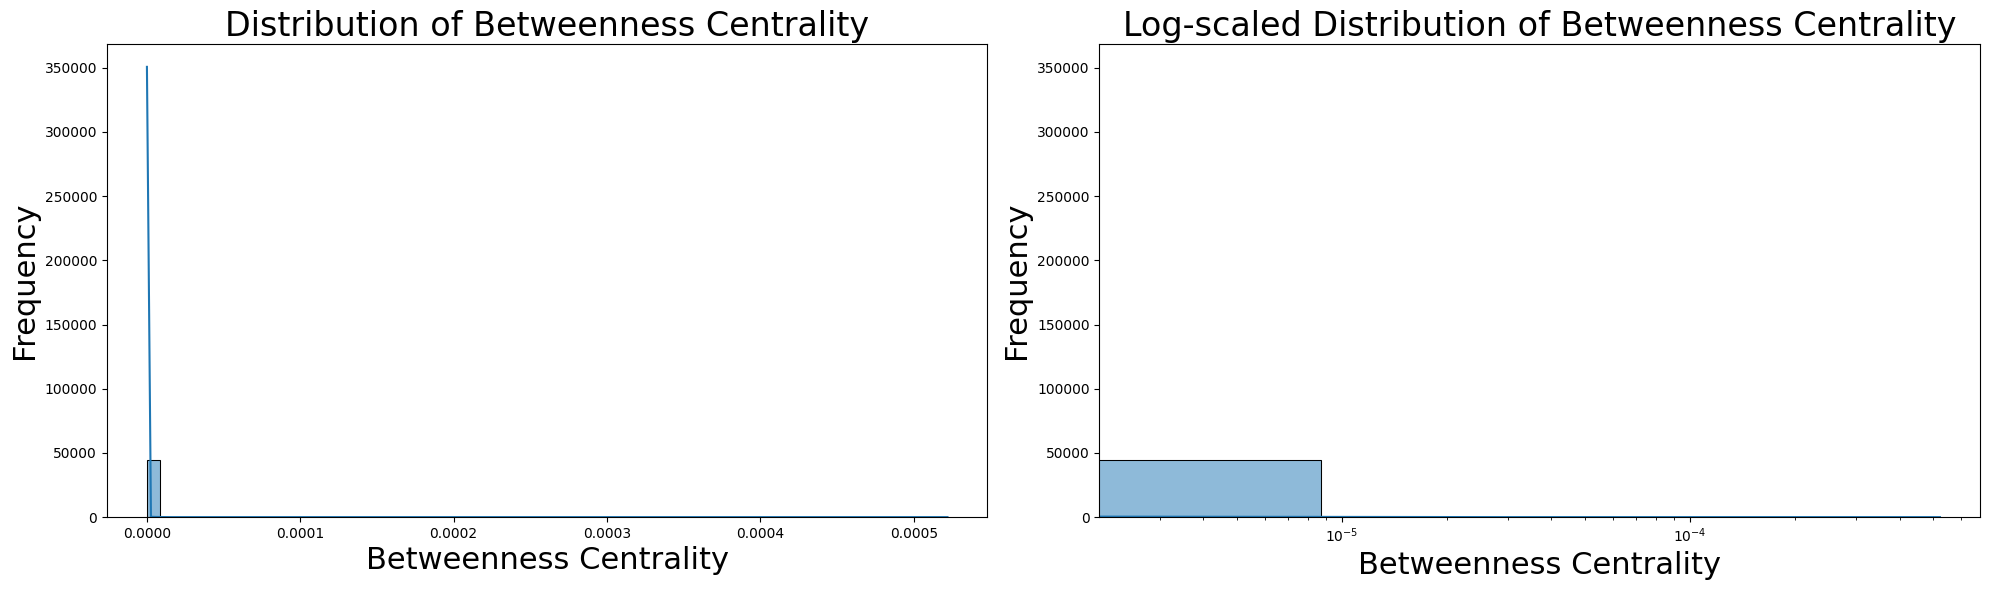

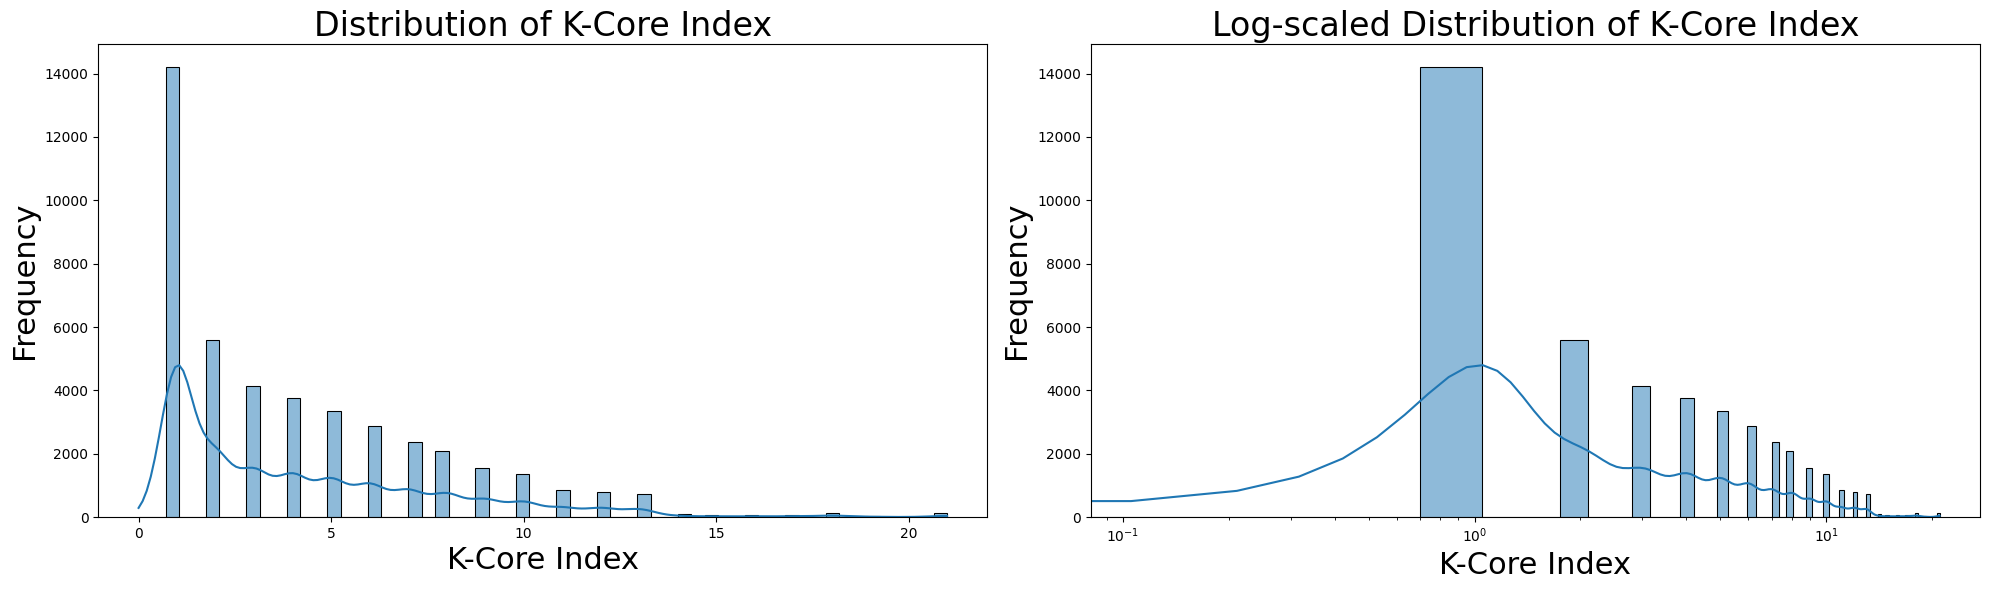

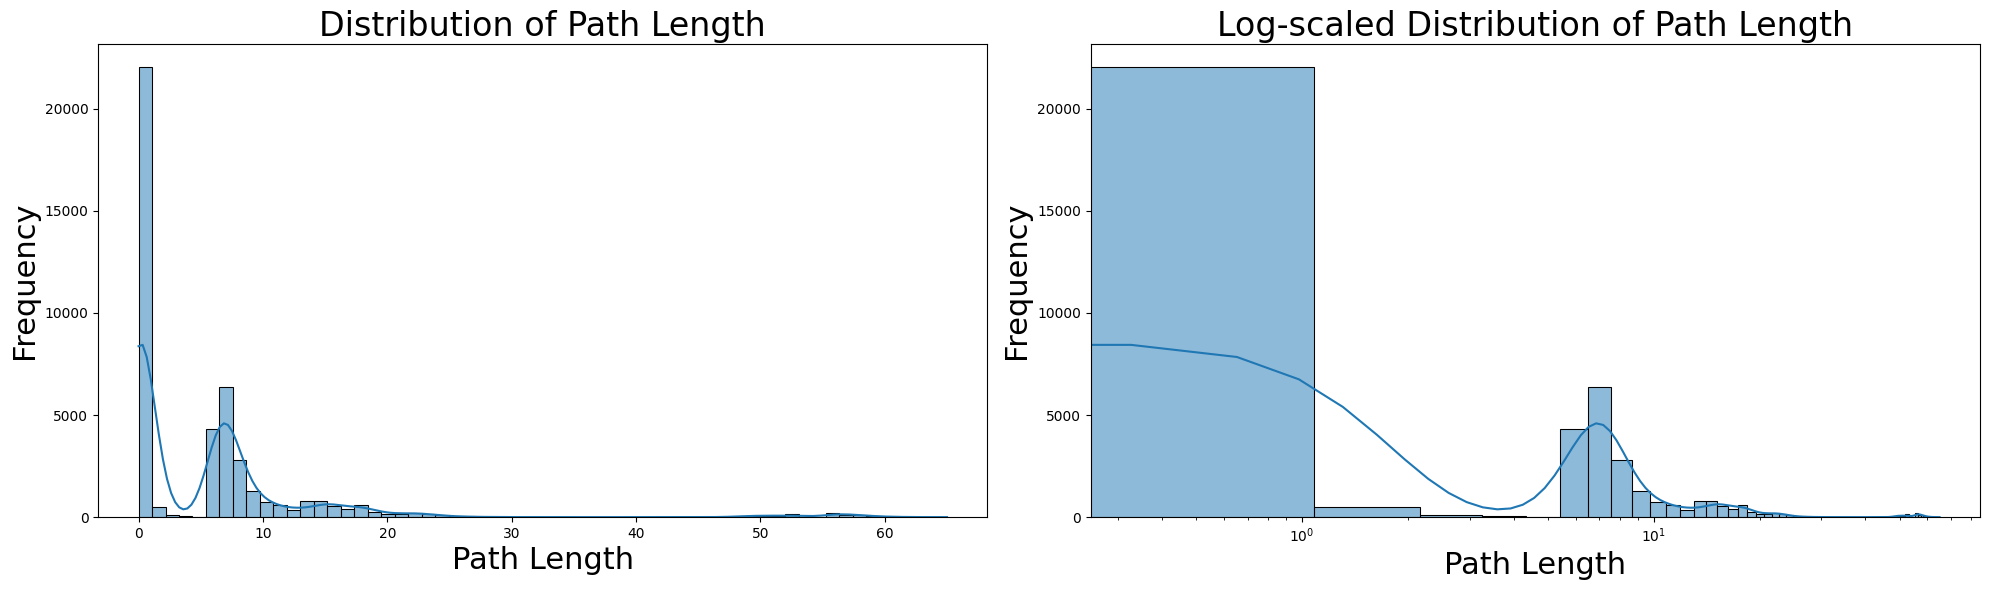

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# metrics = ['Attack Radius', 'In-Degree', 'Betweenness Centrality', 'K-Core Index', 'Path Length']
metrics = ['Attack Radius', 'In-Degree', 'Betweenness Centrality', 'K-Core Index', 'Path Length']

for metric in metrics:
    fig, axes = plt.subplots(1, 2, figsize=(20, 6))

    # Histogram
    sns.histplot(combined_df[metric], kde=True, bins=60, ax=axes[0])
    axes[0].set_title(f'Distribution of {metric}', fontsize=24)
    axes[0].set_xlabel(metric, fontsize=22)
    axes[0].set_ylabel('Frequency', fontsize=22)

    # Log-scaled distribution plot
    sns.histplot(combined_df[metric], kde=True, bins=60, ax=axes[1])
    axes[1].set_title(f'Log-scaled Distribution of {metric}', fontsize=24)
    axes[1].set_xlabel(metric, fontsize=22)
    axes[1].set_ylabel('Frequency', fontsize=22)
    axes[1].set_xscale('log')

    plt.tight_layout()
    plt.show()


Top 10 Unique Values: [12. 13. 14. 15. 16. 17. 18. 19. 20. 21.]
Middle 10 Unique Values: [ 6.  7.  8.  9. 10. 11. 12. 13. 14. 15.]


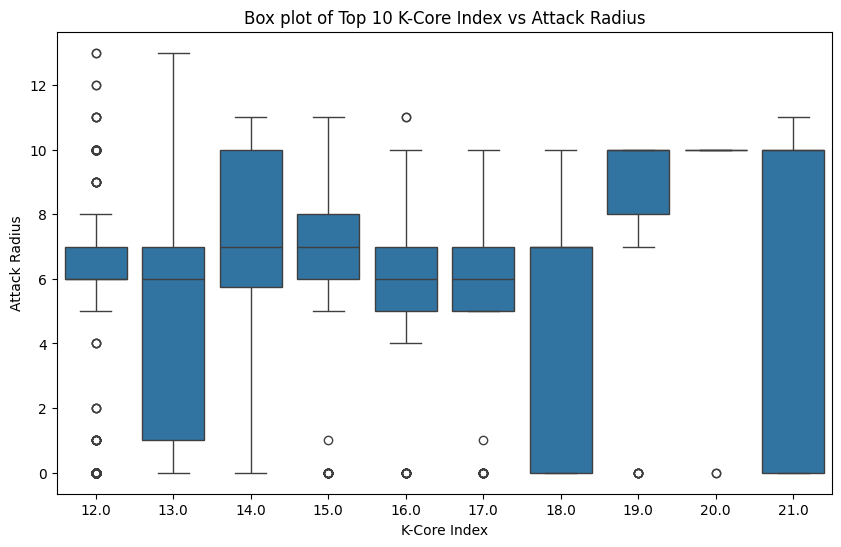

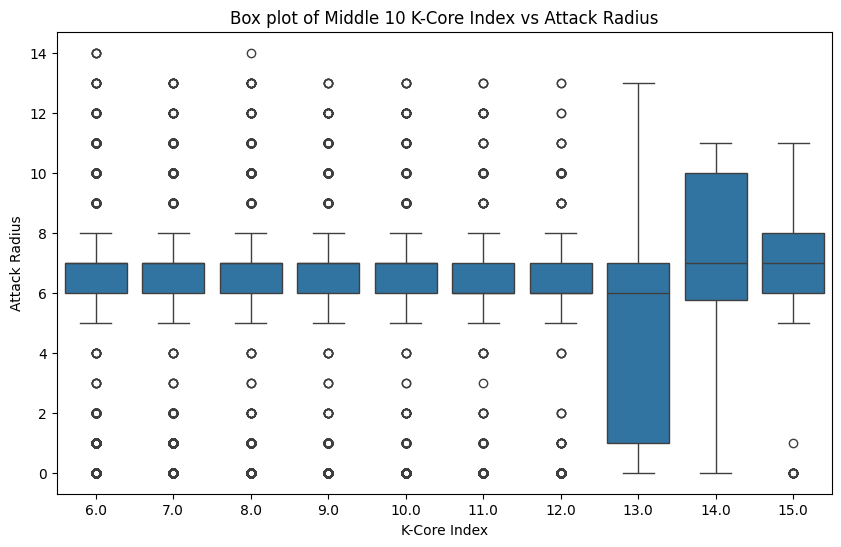

In [ ]:
# Sort the data based on 'Core Value'
sorted_df = combined_df.sort_values('K-Core Index')

# Get unique values from the 'Core Value' column
unique_core_values = sorted_df['K-Core Index'].unique()

# Extract the top 10 unique values
top_values = unique_core_values[-10:]

# Extract the middle 10 unique values
middle_index = len(unique_core_values) // 2
middle_values = unique_core_values[middle_index - 5 : middle_index + 5]

print("Top 10 Unique Values:", top_values)
print("Middle 10 Unique Values:", middle_values)

# Filter the DataFrame for the top and middle values
top_df = sorted_df[sorted_df['K-Core Index'].isin(top_values)]
middle_df = sorted_df[sorted_df['K-Core Index'].isin(middle_values)]

# Create box plots for top values
plt.figure(figsize=(10, 6))
sns.boxplot(x='K-Core Index', y='Attack Radius', data=top_df)
plt.title('Box plot of Top 10 K-Core Index vs Attack Radius')
plt.show()

# Create box plots for middle values
plt.figure(figsize=(10, 6))
sns.boxplot(x='K-Core Index', y='Attack Radius', data=middle_df)
plt.title('Box plot of Middle 10 K-Core Index vs Attack Radius')
plt.show()


### Proposition: Packages with a high propagation costs are more likely to be vulnerable.

### Outlier Analysis

#### Top 5%

In [ ]:
# Helper function to detect outliers
def detect_outliers(df, column):
    Q1 = df[column].quantile(0)
    Q3 = df[column].quantile(0.95)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    outliers = df[(df[column] < lower_bound) | (df[column] > upper_bound)]
    return outliers

# Store outliers in a DataFrame
outliers_dict = {metric: [] for metric in metrics}

# Visualizations and Outlier Analysis
for metric in metrics:
    outliers = detect_outliers(combined_df, metric)
    outliers_dict[metric].extend(outliers['Node'].values)

# Convert outliers_dict to DataFrame
outliers_df = pd.DataFrame([(node, metric) for metric, nodes in outliers_dict.items() for node in nodes], columns=['Node', 'Metric'])

# Combine metrics for each node
outliers_combined = outliers_df.groupby('Node')['Metric'].apply(lambda x: ', '.join(x)).reset_index()

# Identify outliers that match vulnerability nodes
vulnerability_nodes = set(vuln_df['Packages'])
common_outliers_count = {metric: len(set(nodes) & vulnerability_nodes) for metric, nodes in outliers_dict.items()}

# Print count of outliers that match vulnerability nodes for each metric
for metric, count in common_outliers_count.items():
    print(f"Number of outliers in {metric} that match vulnerability nodes: {count}")


Number of outliers in Attack Radius that match vulnerability nodes: 0
Number of outliers in In-Degree that match vulnerability nodes: 101
Number of outliers in Betweenness Centrality that match vulnerability nodes: 327
Number of outliers in K-Core Index that match vulnerability nodes: 0
Number of outliers in Path Length that match vulnerability nodes: 98


#### Top 10%

In [ ]:
# Helper function to detect outliers
def detect_outliers(df, column):
    Q1 = df[column].quantile(0)
    Q3 = df[column].quantile(0.90)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    outliers = df[(df[column] < lower_bound) | (df[column] > upper_bound)]
    return outliers

# Store outliers in a DataFrame
outliers_dict = {metric: [] for metric in metrics}

# Visualizations and Outlier Analysis
for metric in metrics:
    outliers = detect_outliers(combined_df, metric)
    outliers_dict[metric].extend(outliers['Node'].values)

# Convert outliers_dict to DataFrame
outliers_df = pd.DataFrame([(node, metric) for metric, nodes in outliers_dict.items() for node in nodes], columns=['Node', 'Metric'])

# Combine metrics for each node
outliers_combined = outliers_df.groupby('Node')['Metric'].apply(lambda x: ', '.join(x)).reset_index()

# Identify outliers that match vulnerability nodes
vulnerability_nodes = set(vuln_df['Packages'])
common_outliers_count = {metric: len(set(nodes) & vulnerability_nodes) for metric, nodes in outliers_dict.items()}

# Print count of outliers that match vulnerability nodes for each metric
for metric, count in common_outliers_count.items():
    print(f"Number of outliers in {metric} that match vulnerability nodes: {count}")


Number of outliers in Attack Radius that match vulnerability nodes: 0
Number of outliers in In-Degree that match vulnerability nodes: 173
Number of outliers in Betweenness Centrality that match vulnerability nodes: 588
Number of outliers in K-Core Index that match vulnerability nodes: 0
Number of outliers in Path Length that match vulnerability nodes: 98


#### Top and bottom 5%

In [ ]:
# Helper function to detect outliers
def detect_outliers(df, column):
    Q1 = df[column].quantile(0.05)
    Q3 = df[column].quantile(0.95)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    outliers = df[(df[column] < lower_bound) | (df[column] > upper_bound)]
    return outliers

# Store outliers in a DataFrame
outliers_dict = {metric: [] for metric in metrics}

# Visualizations and Outlier Analysis
for metric in metrics:
    outliers = detect_outliers(combined_df, metric)
    outliers_dict[metric].extend(outliers['Node'].values)

# Convert outliers_dict to DataFrame
outliers_df = pd.DataFrame([(node, metric) for metric, nodes in outliers_dict.items() for node in nodes], columns=['Node', 'Metric'])

# Combine metrics for each node
outliers_combined = outliers_df.groupby('Node')['Metric'].apply(lambda x: ', '.join(x)).reset_index()

# Identify outliers that match vulnerability nodes
vulnerability_nodes = set(vuln_df['Packages'])
common_outliers_count = {metric: len(set(nodes) & vulnerability_nodes) for metric, nodes in outliers_dict.items()}

# Print count of outliers that match vulnerability nodes for each metric
for metric, count in common_outliers_count.items():
    print(f"Number of outliers in {metric} that match vulnerability nodes: {count}")


Number of outliers in Attack Radius that match vulnerability nodes: 0
Number of outliers in In-Degree that match vulnerability nodes: 101
Number of outliers in Betweenness Centrality that match vulnerability nodes: 327
Number of outliers in K-Core Index that match vulnerability nodes: 0
Number of outliers in Path Length that match vulnerability nodes: 98


#### Top and bottom 10%

In [ ]:
# Helper function to detect outliers
def detect_outliers(df, column):
    Q1 = df[column].quantile(0.1)
    Q3 = df[column].quantile(0.9)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    outliers = df[(df[column] < lower_bound) | (df[column] > upper_bound)]
    return outliers

# Store outliers in a DataFrame
outliers_dict = {metric: [] for metric in metrics}

# Visualizations and Outlier Analysis
for metric in metrics:
    outliers = detect_outliers(combined_df, metric)
    outliers_dict[metric].extend(outliers['Node'].values)

# Convert outliers_dict to DataFrame
outliers_df = pd.DataFrame([(node, metric) for metric, nodes in outliers_dict.items() for node in nodes], columns=['Node', 'Metric'])

# Combine metrics for each node
outliers_combined = outliers_df.groupby('Node')['Metric'].apply(lambda x: ', '.join(x)).reset_index()

# Identify outliers that match vulnerability nodes
vulnerability_nodes = set(vuln_df['Packages'])
common_outliers_count = {metric: len(set(nodes) & vulnerability_nodes) for metric, nodes in outliers_dict.items()}

# Print count of outliers that match vulnerability nodes for each metric
for metric, count in common_outliers_count.items():
    print(f"Number of outliers in {metric} that match vulnerability nodes: {count}")


Number of outliers in Attack Radius that match vulnerability nodes: 0
Number of outliers in In-Degree that match vulnerability nodes: 173
Number of outliers in Betweenness Centrality that match vulnerability nodes: 588
Number of outliers in K-Core Index that match vulnerability nodes: 0
Number of outliers in Path Length that match vulnerability nodes: 98


### Top and Bottom 20%

In [ ]:
# Helper function to detect outliers
def detect_outliers(df, column):
    Q1 = df[column].quantile(0.2)
    Q3 = df[column].quantile(0.8)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    outliers = df[(df[column] < lower_bound) | (df[column] > upper_bound)]
    return outliers

# Store outliers in a DataFrame
outliers_dict = {metric: [] for metric in metrics}

# Visualizations and Outlier Analysis
for metric in metrics:
    outliers = detect_outliers(combined_df, metric)
    outliers_dict[metric].extend(outliers['Node'].values)

# Convert outliers_dict to DataFrame
outliers_df = pd.DataFrame([(node, metric) for metric, nodes in outliers_dict.items() for node in nodes], columns=['Node', 'Metric'])

# Combine metrics for each node
outliers_combined = outliers_df.groupby('Node')['Metric'].apply(lambda x: ', '.join(x)).reset_index()

# Identify outliers that match vulnerability nodes
vulnerability_nodes = set(vuln_df['Packages'])
common_outliers_count = {metric: len(set(nodes) & vulnerability_nodes) for metric, nodes in outliers_dict.items()}

# Print count of outliers that match vulnerability nodes for each metric
for metric, count in common_outliers_count.items():
    print(f"Number of outliers in {metric} that match vulnerability nodes: {count}")


Number of outliers in Attack Radius that match vulnerability nodes: 0
Number of outliers in In-Degree that match vulnerability nodes: 295
Number of outliers in Betweenness Centrality that match vulnerability nodes: 756
Number of outliers in K-Core Index that match vulnerability nodes: 41
Number of outliers in Path Length that match vulnerability nodes: 149


#### Top and bottom 15%

In [ ]:
# Helper function to detect outliers
def detect_outliers(df, column):
    Q1 = df[column].quantile(0.15)
    Q3 = df[column].quantile(0.85)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    outliers = df[(df[column] < lower_bound) | (df[column] > upper_bound)]
    return outliers

# Store outliers in a DataFrame
outliers_dict = {metric: [] for metric in metrics}

# Visualizations and Outlier Analysis
for metric in metrics:
    outliers = detect_outliers(combined_df, metric)
    outliers_dict[metric].extend(outliers['Node'].values)

# Convert outliers_dict to DataFrame
outliers_df = pd.DataFrame([(node, metric) for metric, nodes in outliers_dict.items() for node in nodes], columns=['Node', 'Metric'])

# Combine metrics for each node
outliers_combined = outliers_df.groupby('Node')['Metric'].apply(lambda x: ', '.join(x)).reset_index()

# Identify outliers that match vulnerability nodes
vulnerability_nodes = set(vuln_df['Packages'])
common_outliers_count = {metric: len(set(nodes) & vulnerability_nodes) for metric, nodes in outliers_dict.items()}

# Print count of outliers that match vulnerability nodes for each metric
for metric, count in common_outliers_count.items():
    print(f"Number of outliers in {metric} that match vulnerability nodes: {count}")


Number of outliers in Attack Radius that match vulnerability nodes: 0
Number of outliers in In-Degree that match vulnerability nodes: 295
Number of outliers in Betweenness Centrality that match vulnerability nodes: 756
Number of outliers in K-Core Index that match vulnerability nodes: 17
Number of outliers in Path Length that match vulnerability nodes: 105


#### Top 15%

In [ ]:
# Helper function to detect outliers
def detect_outliers(df, column):
    Q1 = df[column].quantile(0)
    Q3 = df[column].quantile(0.85)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    outliers = df[(df[column] < lower_bound) | (df[column] > upper_bound)]
    return outliers

# Store outliers in a DataFrame
outliers_dict = {metric: [] for metric in metrics}

# Visualizations and Outlier Analysis
for metric in metrics:
    outliers = detect_outliers(combined_df, metric)
    outliers_dict[metric].extend(outliers['Node'].values)

# Convert outliers_dict to DataFrame
outliers_df = pd.DataFrame([(node, metric) for metric, nodes in outliers_dict.items() for node in nodes], columns=['Node', 'Metric'])

# Combine metrics for each node
outliers_combined = outliers_df.groupby('Node')['Metric'].apply(lambda x: ', '.join(x)).reset_index()

# Identify outliers that match vulnerability nodes
vulnerability_nodes = set(vuln_df['Packages'])
common_outliers_count = {metric: len(set(nodes) & vulnerability_nodes) for metric, nodes in outliers_dict.items()}

# Print count of outliers that match vulnerability nodes for each metric
for metric, count in common_outliers_count.items():
    print(f"Number of outliers in {metric} that match vulnerability nodes: {count}")


Number of outliers in Attack Radius that match vulnerability nodes: 0
Number of outliers in In-Degree that match vulnerability nodes: 295
Number of outliers in Betweenness Centrality that match vulnerability nodes: 756
Number of outliers in K-Core Index that match vulnerability nodes: 13
Number of outliers in Path Length that match vulnerability nodes: 105


In [ ]:
vuln_df.shape

(3539, 1)

In [ ]:
common_nodes_df = pd.merge(combined_df, vuln_df, left_on='Node', right_on='Packages', how='inner')
print(common_nodes_df.shape)

(2724, 7)


In [ ]:
common_nodes_df = pd.merge(outliers_combined, vuln_df, left_on='Node', right_on='Packages', how='inner')
print(common_nodes_df.shape)

(847, 3)


In [ ]:
# Merge vulnerability data with source and build phase data
combined_df = combined_df.merge(vuln_df, left_on='Node', right_on='Packages', how='left', indicator=True)

combined_df['is_vulnerable'] = combined_df['_merge'] == 'both'

# Drop the '_merge' column
combined_df.drop(columns=['_merge'], inplace=True)

### Combined Outlier Analysis

In [ ]:
# Calculate combined outlier status for each node
combined = combined_df.copy()
combined['Combined_Outlier'] = 0  # Initialize as non-outlier
for metric in metrics:
    Q1 = combined[metric].quantile(0.05)
    Q3 = combined[metric].quantile(0.95)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    combined['Combined_Outlier'] |= (combined[metric] < lower_bound) | (combined[metric] > upper_bound)

# Filter nodes with outliers
outliers_combined = combined[combined['Combined_Outlier'] == 1]

# Find matches with vulnerability data
matches_with_vulnerability = combined[(combined['Combined_Outlier'] == 1) & (combined_df['is_vulnerable'] == 1)]

# Count the number of matches
num_matches = matches_with_vulnerability.shape[0]
print("Number of matches with vulnerability data:", num_matches)


Number of matches with vulnerability data: 391


In [ ]:
combined['Combined_Outlier'] = 0  # Initialize as non-outlier
for metric in metrics:
    Q1 = combined[metric].quantile(0.1)
    Q3 = combined[metric].quantile(0.9)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    combined['Combined_Outlier'] |= (combined[metric] < lower_bound) | (combined[metric] > upper_bound)

# Filter nodes with outliers
outliers_combined = combined[combined['Combined_Outlier'] == 1]

# Find matches with vulnerability data
matches_with_vulnerability = combined[(combined['Combined_Outlier'] == 1) & (combined['is_vulnerable'] == 1)]

# Count the number of matches
num_matches = matches_with_vulnerability.shape[0]
print("Number of matches with vulnerability data:", num_matches)


Number of matches with vulnerability data: 661


In [ ]:
# Calculate combined outlier status for each node
combined = combined_df.copy()
combined['Combined_Outlier'] = 0  # Initialize as non-outlier
for metric in metrics:
    Q1 = combined[metric].quantile(0.15)
    Q3 = combined[metric].quantile(0.85)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    combined['Combined_Outlier'] |= (combined[metric] < lower_bound) | (combined[metric] > upper_bound)

# Filter nodes with outliers
outliers_combined = combined[combined['Combined_Outlier'] == 1]

# Find matches with vulnerability data
matches_with_vulnerability = combined[(combined['Combined_Outlier'] == 1) & (combined['is_vulnerable'] == 1)]

# Count the number of matches
num_matches = matches_with_vulnerability.shape[0]
print("Number of matches with vulnerability data:", num_matches)


Number of matches with vulnerability data: 851


In [ ]:
# Calculate combined outlier status for each node
combined = combined_df.copy()
combined['Combined_Outlier'] = 0  # Initialize as non-outlier
for metric in metrics:
    Q1 = combined[metric].quantile(0)
    Q3 = combined[metric].quantile(0.85)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    combined['Combined_Outlier'] |= (combined[metric] < lower_bound) | (combined[metric] > upper_bound)

# Filter nodes with outliers
outliers_combined = combined[combined['Combined_Outlier'] == 1]

# Find matches with vulnerability data
matches_with_vulnerability = combined[(combined['Combined_Outlier'] == 1) & (combined['is_vulnerable'] == 1)]

# Count the number of matches
num_matches = matches_with_vulnerability.shape[0]
print("Number of matches with vulnerability data:", num_matches)


Number of matches with vulnerability data: 847


### Clustering

In [ ]:
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

# Combine metrics into a single dataframe
combined_metrics = combined[metrics]

# Standardize data
scaler = StandardScaler()
scaled_data = scaler.fit_transform(combined_metrics)

# Cluster analysis
kmeans = KMeans(n_clusters=1000, random_state=42)
combined['Cluster'] = kmeans.fit_predict(scaled_data)

# Check correlation of outlier clusters with vulnerability
outlier_clusters = combined[combined['Combined_Outlier'] == 1]['Cluster']
vulnerability_corr = combined.loc[outlier_clusters.index.tolist(), 'is_vulnerable']

# Check correlation of all clusters with vulnerability
all_clusters_corr = combined['Cluster'].apply(lambda x: combined.loc[combined['Cluster'] == x, 'is_vulnerable'].mean())

print("Number of outlier clusters:", outlier_clusters.nunique())
print("Correlation of outlier clusters with vulnerability:", outlier_clusters.corr(vulnerability_corr))
# print("Correlation of all clusters with vulnerability:", all_clusters_corr)


Number of outlier clusters: 927
Correlation of outlier clusters with vulnerability: 0.014005175211163373


In [ ]:
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

# Combine metrics into a single dataframe
combined_metrics = combined[metrics]

# Standardize data
scaler = StandardScaler()
scaled_data = scaler.fit_transform(combined_metrics)

# Cluster analysis
kmeans = KMeans(n_clusters=500, random_state=42)
combined['Cluster'] = kmeans.fit_predict(scaled_data)

# Check correlation of outlier clusters with vulnerability
outlier_clusters = combined[combined['Combined_Outlier'] == 1]['Cluster']
vulnerability_corr = combined.loc[outlier_clusters.index.tolist(), 'is_vulnerable']

# Check correlation of all clusters with vulnerability
all_clusters_corr = combined['Cluster'].apply(lambda x: combined.loc[combined['Cluster'] == x, 'is_vulnerable'].mean())

print("Number of outlier clusters:", outlier_clusters.nunique())
print("Correlation of outlier clusters with vulnerability:", outlier_clusters.corr(vulnerability_corr))
# print("Correlation of all clusters with vulnerability:", all_clusters_corr)


Number of outlier clusters: 489
Correlation of outlier clusters with vulnerability: 0.05459352187636056


In [ ]:
combined_df.head()

,Node,Attack Radius,In-Degree,Path Length,Betweenness Centrality,K-Core Index,Packages_x,is_vulnerable,Packages_y
0,dpkg-source-gitarchive,15,0,53.0,0.000000e+00,4.0,NaN,False,NaN
1,sparkleshare,14,0,52.0,0.000000e+00,6.0,NaN,False,NaN
2,aasvg,14,0,51.0,0.000000e+00,6.0,NaN,False,NaN
3,ruby-rails-deprecated-sanitizer,14,1,52.0,8.413573e-09,6.0,NaN,False,NaN
4,ruby-kramdown-parser-gfm,14,2,51.0,1.019827e-09,6.0,NaN,False,NaN


### Anomalies - 15%

In [ ]:
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import IsolationForest, RandomForestClassifier
from sklearn.svm import OneClassSVM
from sklearn.covariance import EllipticEnvelope
from sklearn.metrics import classification_report

training_data = combined_df.copy()
X_train = training_data[metrics]
y_train = training_data['is_vulnerable']

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)

# Train anomaly detection models
isolation_forest = IsolationForest(random_state=42, contamination=0.15)
isolation_forest.fit(X_train_scaled)

one_class_svm = OneClassSVM(nu=0.15)
one_class_svm.fit(X_train_scaled)

robust_cov = EllipticEnvelope(contamination=0.15, support_fraction=0.85)
robust_cov.fit(X_train_scaled)

# Predict anomalies in the training data
training_data['IsolationForest_Anomaly'] = isolation_forest.predict(X_train_scaled)
training_data['OneClassSVM_Anomaly'] = one_class_svm.predict(X_train_scaled)
training_data['RobustCov_Anomaly'] = robust_cov.predict(X_train_scaled)

# Convert anomaly labels to binary
training_data['IsolationForest_Anomaly'] = training_data['IsolationForest_Anomaly'].apply(lambda x: 1 if x == -1 else 0)
training_data['OneClassSVM_Anomaly'] = training_data['OneClassSVM_Anomaly'].apply(lambda x: 1 if x == -1 else 0)
training_data['RobustCov_Anomaly'] = training_data['RobustCov_Anomaly'].apply(lambda x: 1 if x == -1 else 0)

# Combine anomaly features and other relevant features
X_train_combined = training_data[['IsolationForest_Anomaly', 'OneClassSVM_Anomaly', 'RobustCov_Anomaly'] + metrics]

# Train a classifier
classifier = RandomForestClassifier(random_state=42)
classifier.fit(X_train_combined, y_train)

# Load and preprocess the new dataset
new_data = pd.read_csv('/content/misclassified_samples_source.csv')
new_metrics = new_data[metrics]
X_new_scaled = scaler.transform(new_metrics)

# Predict anomalies in the new data
new_data['IsolationForest_Anomaly'] = isolation_forest.predict(X_new_scaled)
new_data['OneClassSVM_Anomaly'] = one_class_svm.predict(X_new_scaled)
new_data['RobustCov_Anomaly'] = robust_cov.predict(X_new_scaled)

# Convert anomaly labels to binary
new_data['IsolationForest_Anomaly'] = new_data['IsolationForest_Anomaly'].apply(lambda x: 1 if x == -1 else 0)
new_data['OneClassSVM_Anomaly'] = new_data['OneClassSVM_Anomaly'].apply(lambda x: 1 if x == -1 else 0)
new_data['RobustCov_Anomaly'] = new_data['RobustCov_Anomaly'].apply(lambda x: 1 if x == -1 else 0)

# Combine anomaly features and other relevant features
X_new_combined = new_data[['IsolationForest_Anomaly', 'OneClassSVM_Anomaly', 'RobustCov_Anomaly'] + metrics]

# Predict vulnerabilities in the new data
new_data['Predicted_Vulnerability'] = classifier.predict(X_new_combined)



In [ ]:
from sklearn.metrics import accuracy_score, classification_report
# Assume new_data has a column 'is_vulnerable' for actual vulnerabilities
y_true = new_data['Target']
y_pred = new_data['Predicted_Vulnerability']

print("Accuracy:", accuracy_score(y_true, y_pred))
# Generate classification report
report = classification_report(y_true, y_pred)
print(report)

Accuracy: 0.6879750535957903
              precision    recall  f1-score   support

       False       0.68      1.00      0.81      3461
        True       0.87      0.05      0.09      1670

    accuracy                           0.69      5131
   macro avg       0.78      0.52      0.45      5131
weighted avg       0.75      0.69      0.58      5131



## Anomalies 20%

In [ ]:
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import IsolationForest, RandomForestClassifier
from sklearn.svm import OneClassSVM
from sklearn.covariance import EllipticEnvelope
from sklearn.metrics import classification_report

training_data = combined_df.copy()
X_train = training_data[metrics]
y_train = training_data['is_vulnerable']

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)

# Train anomaly detection models
isolation_forest = IsolationForest(random_state=42, contamination=0.2)
isolation_forest.fit(X_train_scaled)

one_class_svm = OneClassSVM(nu=0.20)
one_class_svm.fit(X_train_scaled)

robust_cov = EllipticEnvelope(contamination=0.2, support_fraction=0.85)
robust_cov.fit(X_train_scaled)

# Predict anomalies in the training data
training_data['IsolationForest_Anomaly'] = isolation_forest.predict(X_train_scaled)
training_data['OneClassSVM_Anomaly'] = one_class_svm.predict(X_train_scaled)
training_data['RobustCov_Anomaly'] = robust_cov.predict(X_train_scaled)

# Convert anomaly labels to binary
training_data['IsolationForest_Anomaly'] = training_data['IsolationForest_Anomaly'].apply(lambda x: 1 if x == -1 else 0)
training_data['OneClassSVM_Anomaly'] = training_data['OneClassSVM_Anomaly'].apply(lambda x: 1 if x == -1 else 0)
training_data['RobustCov_Anomaly'] = training_data['RobustCov_Anomaly'].apply(lambda x: 1 if x == -1 else 0)

# Combine anomaly features and other relevant features
X_train_combined = training_data[['IsolationForest_Anomaly', 'OneClassSVM_Anomaly', 'RobustCov_Anomaly'] + metrics]

# Train a classifier
classifier = RandomForestClassifier(random_state=42)
classifier.fit(X_train_combined, y_train)

# Load and preprocess the new dataset
new_data = pd.read_csv('/content/misclassified_samples_source.csv')
new_metrics = new_data[metrics]
X_new_scaled = scaler.transform(new_metrics)

# Predict anomalies in the new data
new_data['IsolationForest_Anomaly'] = isolation_forest.predict(X_new_scaled)
new_data['OneClassSVM_Anomaly'] = one_class_svm.predict(X_new_scaled)
new_data['RobustCov_Anomaly'] = robust_cov.predict(X_new_scaled)

# Convert anomaly labels to binary
new_data['IsolationForest_Anomaly'] = new_data['IsolationForest_Anomaly'].apply(lambda x: 1 if x == -1 else 0)
new_data['OneClassSVM_Anomaly'] = new_data['OneClassSVM_Anomaly'].apply(lambda x: 1 if x == -1 else 0)
new_data['RobustCov_Anomaly'] = new_data['RobustCov_Anomaly'].apply(lambda x: 1 if x == -1 else 0)

# Combine anomaly features and other relevant features
X_new_combined = new_data[['IsolationForest_Anomaly', 'OneClassSVM_Anomaly', 'RobustCov_Anomaly'] + metrics]

# Predict vulnerabilities in the new data
new_data['Predicted_Vulnerability'] = classifier.predict(X_new_combined)



In [ ]:
from sklearn.metrics import accuracy_score, classification_report
# Assume new_data has a column 'is_vulnerable' for actual vulnerabilities
y_true = new_data['Target']
y_pred = new_data['Predicted_Vulnerability']

print("Accuracy:", accuracy_score(y_true, y_pred))
# Generate classification report
report = classification_report(y_true, y_pred)
print(report)

Accuracy: 0.6858312219840187
              precision    recall  f1-score   support

       False       0.68      1.00      0.81      3461
        True       0.86      0.04      0.08      1670

    accuracy                           0.69      5131
   macro avg       0.77      0.52      0.44      5131
weighted avg       0.74      0.69      0.57      5131



## Anomalies 25%

In [ ]:
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import IsolationForest, RandomForestClassifier
from sklearn.svm import OneClassSVM
from sklearn.covariance import EllipticEnvelope
from sklearn.metrics import classification_report

training_data = combined_df.copy()
X_train = training_data[metrics]
y_train = training_data['is_vulnerable']

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)

# Train anomaly detection models
isolation_forest = IsolationForest(random_state=42, contamination=0.25)
isolation_forest.fit(X_train_scaled)

one_class_svm = OneClassSVM(nu=0.25)
one_class_svm.fit(X_train_scaled)

robust_cov = EllipticEnvelope(contamination=0.25, support_fraction=0.9)
robust_cov.fit(X_train_scaled)

# Predict anomalies in the training data
training_data['IsolationForest_Anomaly'] = isolation_forest.predict(X_train_scaled)
training_data['OneClassSVM_Anomaly'] = one_class_svm.predict(X_train_scaled)
training_data['RobustCov_Anomaly'] = robust_cov.predict(X_train_scaled)

# Convert anomaly labels to binary
training_data['IsolationForest_Anomaly'] = training_data['IsolationForest_Anomaly'].apply(lambda x: 1 if x == -1 else 0)
training_data['OneClassSVM_Anomaly'] = training_data['OneClassSVM_Anomaly'].apply(lambda x: 1 if x == -1 else 0)
training_data['RobustCov_Anomaly'] = training_data['RobustCov_Anomaly'].apply(lambda x: 1 if x == -1 else 0)

# Combine anomaly features and other relevant features
X_train_combined = training_data[['IsolationForest_Anomaly', 'OneClassSVM_Anomaly', 'RobustCov_Anomaly'] + metrics]

# Train a classifier
classifier = RandomForestClassifier(random_state=42)
classifier.fit(X_train_combined, y_train)

# Load and preprocess the new dataset
new_data = pd.read_csv('/content/misclassified_samples_source.csv')
new_metrics = new_data[metrics]
X_new_scaled = scaler.transform(new_metrics)

# Predict anomalies in the new data
new_data['IsolationForest_Anomaly'] = isolation_forest.predict(X_new_scaled)
new_data['OneClassSVM_Anomaly'] = one_class_svm.predict(X_new_scaled)
new_data['RobustCov_Anomaly'] = robust_cov.predict(X_new_scaled)

# Convert anomaly labels to binary
new_data['IsolationForest_Anomaly'] = new_data['IsolationForest_Anomaly'].apply(lambda x: 1 if x == -1 else 0)
new_data['OneClassSVM_Anomaly'] = new_data['OneClassSVM_Anomaly'].apply(lambda x: 1 if x == -1 else 0)
new_data['RobustCov_Anomaly'] = new_data['RobustCov_Anomaly'].apply(lambda x: 1 if x == -1 else 0)

# Combine anomaly features and other relevant features
X_new_combined = new_data[['IsolationForest_Anomaly', 'OneClassSVM_Anomaly', 'RobustCov_Anomaly'] + metrics]

# Predict vulnerabilities in the new data
new_data['Predicted_Vulnerability'] = classifier.predict(X_new_combined)



In [ ]:
from sklearn.metrics import accuracy_score, classification_report
# Assume new_data has a column 'is_vulnerable' for actual vulnerabilities
y_true = new_data['Target']
y_pred = new_data['Predicted_Vulnerability']

print("Accuracy:", accuracy_score(y_true, y_pred))
# Generate classification report
report = classification_report(y_true, y_pred)
print(report)

Accuracy: 0.6860261157669071
              precision    recall  f1-score   support

       False       0.68      1.00      0.81      3461
        True       0.87      0.04      0.08      1670

    accuracy                           0.69      5131
   macro avg       0.78      0.52      0.44      5131
weighted avg       0.75      0.69      0.57      5131



## Anomalies 40%

In [ ]:
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import IsolationForest, RandomForestClassifier
from sklearn.svm import OneClassSVM
from sklearn.covariance import EllipticEnvelope
from sklearn.metrics import classification_report

training_data = combined_df.copy()
X_train = training_data[metrics]
y_train = training_data['is_vulnerable']

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)

# Train anomaly detection models
isolation_forest = IsolationForest(random_state=42, contamination=0.4)
isolation_forest.fit(X_train_scaled)

one_class_svm = OneClassSVM(nu=0.4)
one_class_svm.fit(X_train_scaled)

robust_cov = EllipticEnvelope(contamination=0.4, support_fraction=0.9)
robust_cov.fit(X_train_scaled)

# Predict anomalies in the training data
training_data['IsolationForest_Anomaly'] = isolation_forest.predict(X_train_scaled)
training_data['OneClassSVM_Anomaly'] = one_class_svm.predict(X_train_scaled)
training_data['RobustCov_Anomaly'] = robust_cov.predict(X_train_scaled)

# Convert anomaly labels to binary
training_data['IsolationForest_Anomaly'] = training_data['IsolationForest_Anomaly'].apply(lambda x: 1 if x == -1 else 0)
training_data['OneClassSVM_Anomaly'] = training_data['OneClassSVM_Anomaly'].apply(lambda x: 1 if x == -1 else 0)
training_data['RobustCov_Anomaly'] = training_data['RobustCov_Anomaly'].apply(lambda x: 1 if x == -1 else 0)

# Combine anomaly features and other relevant features
X_train_combined = training_data[['IsolationForest_Anomaly', 'OneClassSVM_Anomaly', 'RobustCov_Anomaly'] + metrics]

# Train a classifier
classifier = RandomForestClassifier(random_state=42)
classifier.fit(X_train_combined, y_train)

# Load and preprocess the new dataset
new_data = pd.read_csv('/content/misclassified_samples_source.csv')
new_metrics = new_data[metrics]
X_new_scaled = scaler.transform(new_metrics)

# Predict anomalies in the new data
new_data['IsolationForest_Anomaly'] = isolation_forest.predict(X_new_scaled)
new_data['OneClassSVM_Anomaly'] = one_class_svm.predict(X_new_scaled)
new_data['RobustCov_Anomaly'] = robust_cov.predict(X_new_scaled)

# Convert anomaly labels to binary
new_data['IsolationForest_Anomaly'] = new_data['IsolationForest_Anomaly'].apply(lambda x: 1 if x == -1 else 0)
new_data['OneClassSVM_Anomaly'] = new_data['OneClassSVM_Anomaly'].apply(lambda x: 1 if x == -1 else 0)
new_data['RobustCov_Anomaly'] = new_data['RobustCov_Anomaly'].apply(lambda x: 1 if x == -1 else 0)

# Combine anomaly features and other relevant features
X_new_combined = new_data[['IsolationForest_Anomaly', 'OneClassSVM_Anomaly', 'RobustCov_Anomaly'] + metrics]

# Predict vulnerabilities in the new data
new_data['Predicted_Vulnerability'] = classifier.predict(X_new_combined)



In [ ]:
from sklearn.metrics import accuracy_score, classification_report
# Assume new_data has a column 'is_vulnerable' for actual vulnerabilities
y_true = new_data['Target']
y_pred = new_data['Predicted_Vulnerability']

print("Accuracy:", accuracy_score(y_true, y_pred))
# Generate classification report
report = classification_report(y_true, y_pred)
print(report)

Accuracy: 0.6862210095497954
              precision    recall  f1-score   support

       False       0.68      1.00      0.81      3461
        True       0.93      0.04      0.07      1670

    accuracy                           0.69      5131
   macro avg       0.81      0.52      0.44      5131
weighted avg       0.76      0.69      0.57      5131



In [ ]:
pip install optuna

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 380.1/380.1 kB 5.0 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 233.4/233.4 kB 14.1 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 78.6/78.6 kB 7.4 MB/s eta 0:00:00


In [ ]:
import optuna
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_val_score

def objective(trial):
    # Hyperparameter space
    n_estimators = trial.suggest_int('n_estimators', 50, 300)
    max_depth = trial.suggest_int('max_depth', 10, 50)
    min_samples_split = trial.suggest_int('min_samples_split', 2, 10)
    min_samples_leaf = trial.suggest_int('min_samples_leaf', 1, 10)

    # Create and evaluate the model
    clf = RandomForestClassifier(
        n_estimators=n_estimators, max_depth=max_depth,
        min_samples_split=min_samples_split, min_samples_leaf=min_samples_leaf,
        random_state=42
    )

    scores = cross_val_score(clf, X_train_combined, y_train, cv=5, scoring='f1')
    return scores.mean()

# Create a study and optimize
study = optuna.create_study(direction='maximize')
study.optimize(objective, n_trials=30)

# Get the best hyperparameters
best_params = study.best_params
print("Best hyperparameters: ", best_params)

# Train the final model with the best hyperparameters
best_clf = RandomForestClassifier(**best_params, random_state=42)
best_clf.fit(X_train_combined, y_train)

# Predict and evaluate
y_pred = best_clf.predict(X_new_combined)
print(classification_report(y_true, y_pred))


[I 2024-06-24 01:58:21,963] A new study created in memory with name: no-name-b5de858c-ad34-41e3-a5e3-97bd8bd90bc1
[I 2024-06-24 01:58:36,677] Trial 0 finished with value: 0.05237648353022761 and parameters: {'n_estimators': 94, 'max_depth': 32, 'min_samples_split': 4, 'min_samples_leaf': 3}. Best is trial 0 with value: 0.05237648353022761.
[I 2024-06-24 01:59:16,974] Trial 1 finished with value: 0.02744251430866553 and parameters: {'n_estimators': 232, 'max_depth': 13, 'min_samples_split': 3, 'min_samples_leaf': 10}. Best is trial 0 with value: 0.05237648353022761.
[I 2024-06-24 01:59:37,562] Trial 2 finished with value: 0.02528759462592921 and parameters: {'n_estimators': 270, 'max_depth': 35, 'min_samples_split': 9, 'min_samples_leaf': 10}. Best is trial 0 with value: 0.05237648353022761.
[I 2024-06-24 01:59:53,563] Trial 3 finished with value: 0.05349770826582632 and parameters: {'n_estimators': 217, 'max_depth': 36, 'min_samples_split': 4, 'min_samples_leaf': 4}. Best is trial 3 wi

Best hyperparameters:  {'n_estimators': 157, 'max_depth': 41, 'min_samples_split': 7, 'min_samples_leaf': 1}
              precision    recall  f1-score   support

       False       0.68      1.00      0.81      3461
        True       0.77      0.01      0.02      1670

    accuracy                           0.68      5131
   macro avg       0.72      0.51      0.42      5131
weighted avg       0.71      0.68      0.55      5131



In [ ]:
from sklearn.pipeline import make_pipeline
from sklearn.ensemble import StackingClassifier
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression


def stacking_objective(trial):
    # Hyperparameter space for base models
    rf_n_estimators = trial.suggest_int('rf_n_estimators', 50, 300)
    rf_max_depth = trial.suggest_int('rf_max_depth', 10, 50)
    svr_c = trial.suggest_loguniform('svr_c', 1e-3, 1e2)

    # Create base models with trial parameters
    rf = RandomForestClassifier(n_estimators=rf_n_estimators, max_depth=rf_max_depth, random_state=42)
    svr = make_pipeline(StandardScaler(), SVC(C=svr_c, probability=True, random_state=42))

    # Create stacking classifier
    stacking_clf = StackingClassifier(
        estimators=[('rf', rf), ('svr', svr)],
        final_estimator=LogisticRegression(random_state=42)
    )

    # Evaluate the stacking classifier
    scores = cross_val_score(stacking_clf, X_train_combined, y_train, cv=5, scoring='f1')
    return scores.mean()

# Create a study and optimize
stacking_study = optuna.create_study(direction='maximize')
stacking_study.optimize(stacking_objective, n_trials=30)

# Get the best hyperparameters
best_stacking_params = stacking_study.best_params
print("Best hyperparameters: ", best_stacking_params)

# Train the final stacking model with the best hyperparameters
rf_best = RandomForestClassifier(n_estimators=best_stacking_params['rf_n_estimators'],
                                 max_depth=best_stacking_params['rf_max_depth'],
                                 random_state=42)
svr_best = make_pipeline(StandardScaler(), SVC(C=best_stacking_params['svr_c'], probability=True, random_state=42))

stacking_clf_best = StackingClassifier(
    estimators=[('rf', rf_best), ('svr', svr_best)],
    final_estimator=LogisticRegression(random_state=42)
)
stacking_clf_best.fit(X_train_combined, y_train)

# Predict and evaluate
y_pred = stacking_clf_best.predict(X_new_combined)
print(classification_report(y_true, y_pred))


[I 2024-06-23 18:49:04,896] A new study created in memory with name: no-name-986cb74a-9be6-46d5-9d07-7263fb9e0911


In [ ]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import IsolationForest, GradientBoostingClassifier
from sklearn.svm import OneClassSVM, SVC
from sklearn.covariance import EllipticEnvelope
from sklearn.metrics import classification_report, accuracy_score
from sklearn.model_selection import cross_val_predict
from sklearn.utils.class_weight import compute_class_weight

# Compute class weights
class_weights = compute_class_weight('balanced', classes=np.unique(y_train), y=y_train)
class_weights_dict = {0: class_weights[0], 1: class_weights[1]}

# Initialize the Gradient Boosting and SVM classifiers
gbm_classifier = GradientBoostingClassifier(random_state=42)
svm_classifier = SVC(random_state=42, class_weight=class_weights_dict)

# Train the classifiers on the full training data
gbm_classifier.fit(X_train_combined, y_train)
svm_classifier.fit(X_train_combined, y_train)


# Predict vulnerabilities in the new data using GBM
new_data['Predicted_Vulnerability_GBM'] = gbm_classifier.predict(X_new_combined)

# Predict vulnerabilities in the new data using SVM
new_data['Predicted_Vulnerability_SVM'] = svm_classifier.predict(X_new_combined)

# Evaluate the performance on new data for GBM
y_true = new_data['Target']
y_pred_gbm = new_data['Predicted_Vulnerability_GBM']

print("New Data (GBM) - Accuracy:", accuracy_score(y_true, y_pred_gbm))
print("New Data (GBM) - Classification Report:")
print(classification_report(y_true, y_pred_gbm))

# Evaluate the performance on new data for SVM
y_pred_svm = new_data['Predicted_Vulnerability_SVM']

print("New Data (SVM) - Accuracy:", accuracy_score(y_true, y_pred_svm))
print("New Data (SVM) - Classification Report:")
print(classification_report(y_true, y_pred_svm))


New Data (GBM) - Accuracy: 0.6743324887936075
New Data (GBM) - Classification Report:
              precision    recall  f1-score   support

       False       0.67      1.00      0.81      3461
        True       0.40      0.00      0.00      1670

    accuracy                           0.67      5131
   macro avg       0.54      0.50      0.40      5131
weighted avg       0.59      0.67      0.54      5131

New Data (SVM) - Accuracy: 0.40226076788150456
New Data (SVM) - Classification Report:
              precision    recall  f1-score   support

       False       0.65      0.24      0.36      3461
        True       0.32      0.73      0.44      1670

    accuracy                           0.40      5131
   macro avg       0.48      0.49      0.40      5131
weighted avg       0.54      0.40      0.38      5131



In [ ]:
# Initialize the Gradient Boosting and SVM classifiers
gbm_classifier = GradientBoostingClassifier(random_state=42)
svm_classifier = SVC(random_state=42)

# Train the classifiers on the full training data
gbm_classifier.fit(X_train_combined, y_train)
svm_classifier.fit(X_train_combined, y_train)


# Predict vulnerabilities in the new data using GBM
new_data['Predicted_Vulnerability_GBM'] = gbm_classifier.predict(X_new_combined)

# Predict vulnerabilities in the new data using SVM
new_data['Predicted_Vulnerability_SVM'] = svm_classifier.predict(X_new_combined)

# Evaluate the performance on new data for GBM
y_true = new_data['Target']
y_pred_gbm = new_data['Predicted_Vulnerability_GBM']

print("New Data (GBM) - Accuracy:", accuracy_score(y_true, y_pred_gbm))
print("New Data (GBM) - Classification Report:")
print(classification_report(y_true, y_pred_gbm))

# Evaluate the performance on new data for SVM
y_pred_svm = new_data['Predicted_Vulnerability_SVM']

print("New Data (SVM) - Accuracy:", accuracy_score(y_true, y_pred_svm))
print("New Data (SVM) - Classification Report:")
print(classification_report(y_true, y_pred_svm))


New Data (GBM) - Accuracy: 0.6743324887936075
New Data (GBM) - Classification Report:
              precision    recall  f1-score   support

       False       0.67      1.00      0.81      3461
        True       0.40      0.00      0.00      1670

    accuracy                           0.67      5131
   macro avg       0.54      0.50      0.40      5131
weighted avg       0.59      0.67      0.54      5131

New Data (SVM) - Accuracy: 0.6745273825764958
New Data (SVM) - Classification Report:
              precision    recall  f1-score   support

       False       0.67      1.00      0.81      3461
        True       0.00      0.00      0.00      1670

    accuracy                           0.67      5131
   macro avg       0.34      0.50      0.40      5131
weighted avg       0.45      0.67      0.54      5131



In [ ]:
from xgboost import XGBClassifier

# Train a classifier
classifier = XGBClassifier(random_state=42)
classifier.fit(X_train_combined, y_train)

# Load and preprocess the new dataset
# Predict vulnerabilities in the new data
new_data['Predicted_Vulnerability'] = classifier.predict(X_new_combined)

# Output the results
# print(new_data[['Node', 'Predicted_Vulnerability']])

# Assume new_data has a column 'is_vulnerable' for actual vulnerabilities
y_true = new_data['Target']
y_pred = new_data['Predicted_Vulnerability']

print("Accuracy:", accuracy_score(y_true, y_pred))
# Generate classification report
report = classification_report(y_true, y_pred)
print(report)

Accuracy: 0.6795946209315923
              precision    recall  f1-score   support

       False       0.68      1.00      0.81      3461
        True       0.81      0.02      0.04      1670

    accuracy                           0.68      5131
   macro avg       0.74      0.51      0.42      5131
weighted avg       0.72      0.68      0.56      5131



In [ ]:
from sklearn.model_selection import GridSearchCV
from sklearn.utils.class_weight import compute_class_weight

# Compute class weights
class_weights = compute_class_weight('balanced', classes=np.unique(y_train), y=y_train)
class_weights_dict = {0: class_weights[0], 1: class_weights[1]}

# Define the parameter grid for hyperparameter tuning
param_grid = {
    'n_estimators': [50, 100, 200],
    'max_depth': [3, 5, 7],
    'learning_rate': [0.01, 0.1, 0.2],
    'scale_pos_weight': [class_weights[1] / class_weights[0]]
}

# Initialize the XGBClassifier
xgb_classifier = XGBClassifier(random_state=42, objective='binary:logistic', use_label_encoder=False, eval_metric='logloss')

# Perform GridSearchCV for hyperparameter tuning
grid_search = GridSearchCV(estimator=xgb_classifier, param_grid=param_grid, scoring='f1', cv=5, n_jobs=-1)
grid_search.fit(X_train_combined, y_train)

# Get the best estimator
best_classifier = grid_search.best_estimator_

# Predict vulnerabilities in the new data
new_data['Predicted_Vulnerability'] = best_classifier.predict(X_new_combined)

# Evaluate the performance
y_true = new_data['Target']
y_pred = new_data['Predicted_Vulnerability']

print("Accuracy:", accuracy_score(y_true, y_pred))
report = classification_report(y_true, y_pred)
print(report)


Accuracy: 0.24848957318261547
              precision    recall  f1-score   support

       False       0.30      0.08      0.13      3461
        True       0.24      0.59      0.34      1670

    accuracy                           0.25      5131
   macro avg       0.27      0.34      0.23      5131
weighted avg       0.28      0.25      0.20      5131



In [ ]:
param_grid = {
    'n_estimators': [50, 100, 200],
    'max_depth': [3, 5, 7],
    'class_weight': [class_weights_dict]
}
# Initialize the RandomForestClassifier
rf_classifier = RandomForestClassifier(random_state=42)

# Perform GridSearchCV for hyperparameter tuning
grid_search = GridSearchCV(estimator=rf_classifier, param_grid=param_grid, scoring='f1', cv=5, n_jobs=-1)
grid_search.fit(X_train_combined, y_train)

# Get the best estimator
best_classifier = grid_search.best_estimator_

# Predict vulnerabilities in the new data
new_data['Predicted_Vulnerability'] = best_classifier.predict(X_new_combined)

# Evaluate the performance
y_true = new_data['Target']
y_pred = new_data['Predicted_Vulnerability']

print("Accuracy:", accuracy_score(y_true, y_pred))
report = classification_report(y_true, y_pred)
print(report)

Accuracy: 0.3026700448255701
              precision    recall  f1-score   support

       False       0.19      0.01      0.02      3461
        True       0.31      0.91      0.46      1670

    accuracy                           0.30      5131
   macro avg       0.25      0.46      0.24      5131
weighted avg       0.23      0.30      0.16      5131



In [ ]:
from sklearn.model_selection import cross_val_predict

# Compute class weights
class_weights = compute_class_weight('balanced', classes=np.unique(y_train), y=y_train)
class_weights_dict = {0: class_weights[0], 1: class_weights[1]}

# Initialize the RandomForestClassifier
classifier = RandomForestClassifier(random_state=42, class_weight=class_weights_dict)

# Perform cross-validation and get predictions
y_train_pred = cross_val_predict(classifier, X_train_combined, y_train, cv=5)

# Evaluate the performance on training data
print("Training Data - Accuracy:", accuracy_score(y_train, y_train_pred))
print("Training Data - Classification Report:")
print(classification_report(y_train, y_train_pred))

# Train the classifier on the full training data
classifier.fit(X_train_combined, y_train)

# Predict vulnerabilities in the new data
new_data['Predicted_Vulnerability'] = classifier.predict(X_new_combined)

# Evaluate the performance on new data
y_true = new_data['Target']
y_pred = new_data['Predicted_Vulnerability']

print("New Data - Accuracy:", accuracy_score(y_true, y_pred))
print("New Data - Classification Report:")
print(classification_report(y_true, y_pred))


Training Data - Accuracy: 0.5664995709705098
Training Data - Classification Report:
              precision    recall  f1-score   support

       False       0.93      0.58      0.72     41562
        True       0.05      0.35      0.09      2724

    accuracy                           0.57     44286
   macro avg       0.49      0.47      0.40     44286
weighted avg       0.88      0.57      0.68     44286

New Data - Accuracy: 0.2862989670629507
New Data - Classification Report:
              precision    recall  f1-score   support

       False       0.42      0.14      0.21      3461
        True       0.25      0.59      0.35      1670

    accuracy                           0.29      5131
   macro avg       0.33      0.36      0.28      5131
weighted avg       0.36      0.29      0.26      5131



In [ ]:
from sklearn.model_selection import cross_val_predict

# Initialize the RandomForestClassifier
classifier = RandomForestClassifier(random_state=42)

# Perform cross-validation and get predictions
y_train_pred = cross_val_predict(classifier, X_train_combined, y_train, cv=5)

# Evaluate the performance on training data
print("Training Data - Accuracy:", accuracy_score(y_train, y_train_pred))
print("Training Data - Classification Report:")
print(classification_report(y_train, y_train_pred))

# Train the classifier on the full training data
classifier.fit(X_train_combined, y_train)

# Predict vulnerabilities in the new data
new_data['Predicted_Vulnerability'] = classifier.predict(X_new_combined)

# Evaluate the performance on new data
y_true = new_data['Target']
y_pred = new_data['Predicted_Vulnerability']

print("New Data - Accuracy:", accuracy_score(y_true, y_pred))
print("New Data - Classification Report:")
print(classification_report(y_true, y_pred))


Training Data - Accuracy: 0.7701305152869982
Training Data - Classification Report:
              precision    recall  f1-score   support

       False       0.93      0.81      0.87     41562
        True       0.03      0.09      0.04      2724

    accuracy                           0.77     44286
   macro avg       0.48      0.45      0.46     44286
weighted avg       0.88      0.77      0.82     44286

New Data - Accuracy: 0.6862210095497954
New Data - Classification Report:
              precision    recall  f1-score   support

       False       0.68      1.00      0.81      3461
        True       0.93      0.04      0.07      1670

    accuracy                           0.69      5131
   macro avg       0.81      0.52      0.44      5131
weighted avg       0.76      0.69      0.57      5131



In [ ]:
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.covariance import EllipticEnvelope
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import classification_report, accuracy_score
from imblearn.under_sampling import RandomUnderSampler
from sklearn.model_selection import GridSearchCV
from sklearn.utils.class_weight import compute_class_weight
import numpy as np

# Load and preprocess the dataset
data = combined_df.copy()
X = data[metrics]
y = data['is_vulnerable']

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Detect anomalies using Robust Covariance
robust_cov = EllipticEnvelope(contamination=0.1, support_fraction=0.9)
anomalies = robust_cov.fit_predict(X_scaled)

# Add anomaly labels to the data
data['RobustCov_Anomaly'] = anomalies
data['RobustCov_Anomaly'] = data['RobustCov_Anomaly'].apply(lambda x: 1 if x == -1 else 0)

# Filter data for anomalies
anomaly_data = data[data['RobustCov_Anomaly'] == 1]

# Prepare training data
X_train = anomaly_data[metrics]
y_train = anomaly_data['is_vulnerable']

# Undersample the majority class
rus = RandomUnderSampler(random_state=42)
X_train_resampled, y_train_resampled = rus.fit_resample(X_train, y_train)

# Compute class weights
class_weights = compute_class_weight('balanced', classes=np.unique(y_train_resampled), y=y_train_resampled)
class_weights_dict = {0: class_weights[0], 1: class_weights[1]}

# Train classifiers
svm_classifier = SVC(random_state=42, class_weight=class_weights_dict)
svm_classifier.fit(X_train_resampled, y_train_resampled)

# Load and preprocess the new dataset
new_data = pd.read_csv('/content/misclassified_samples.csv')
new_X = new_data[metrics]
new_X_scaled = scaler.transform(new_X)

# Detect anomalies in the new data using Robust Covariance
new_anomalies = robust_cov.predict(new_X_scaled)

# Add anomaly labels to the new data
new_data['RobustCov_Anomaly'] = new_anomalies
new_data['RobustCov_Anomaly'] = new_data['RobustCov_Anomaly'].apply(lambda x: 1 if x == -1 else 0)

# Filter new data for anomalies
new_anomaly_data = new_data[new_data['RobustCov_Anomaly'] == 1]

# Prepare new data for predictions
new_X_anomalies = new_anomaly_data[metrics]
y_true_anomalies = new_anomaly_data['Target']

# Predict vulnerabilities using SVM
y_pred_svm = svm_classifier.predict(new_X_anomalies)

# Output the results for SVM
print("SVM Classifier - Accuracy:", accuracy_score(y_true_anomalies, y_pred_svm))
print("SVM Classifier - Classification Report:")
print(classification_report(y_true_anomalies, y_pred_svm))

In [ ]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.covariance import EllipticEnvelope
from sklearn.svm import SVC
from sklearn.metrics import classification_report, accuracy_score
from imblearn.under_sampling import RandomUnderSampler
from sklearn.utils.class_weight import compute_class_weight

# Function to apply log transformation
def log_transform(df, metrics):
    df_log = df.copy()
    for col in metrics:
        df_log[col] = np.log1p(df[col])  # log1p is used to handle zero values
    return df_log

# Load and preprocess the dataset
data = combined_df.copy()

# Apply log transformation to metrics
data_log = log_transform(data, metrics)
X = data_log[metrics]
y = data_log['is_vulnerable']

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Detect anomalies using Robust Covariance
robust_cov = EllipticEnvelope(contamination=0.1, support_fraction=0.9)
anomalies = robust_cov.fit_predict(X_scaled)

# Add anomaly labels to the data
data['RobustCov_Anomaly'] = anomalies
data['RobustCov_Anomaly'] = data['RobustCov_Anomaly'].apply(lambda x: 1 if x == -1 else 0)

# Filter data for anomalies
anomaly_data = data[data['RobustCov_Anomaly'] == 1]

# Prepare training data
X_train = anomaly_data[metrics]
y_train = anomaly_data['is_vulnerable']

# Undersample the majority class
rus = RandomUnderSampler(random_state=42)
X_train_resampled, y_train_resampled = rus.fit_resample(X_train, y_train)

# Compute class weights
class_weights = compute_class_weight('balanced', classes=np.unique(y_train_resampled), y=y_train_resampled)
class_weights_dict = {0: class_weights[0], 1: class_weights[1]}

# Train SVM classifier
svm_classifier = SVC(random_state=42, class_weight=class_weights_dict)
svm_classifier.fit(X_train_resampled, y_train_resampled)

# Load and preprocess the new dataset
new_data = pd.read_csv('/content/misclassified_samples.csv')

# Apply log transformation to the new data
new_data_log = log_transform(new_data, metrics)
new_X = new_data_log[metrics]
new_X_scaled = scaler.transform(new_X)

# Detect anomalies in the new data using Robust Covariance
new_anomalies = robust_cov.predict(new_X_scaled)

# Add anomaly labels to the new data
new_data['RobustCov_Anomaly'] = new_anomalies
new_data['RobustCov_Anomaly'] = new_data['RobustCov_Anomaly'].apply(lambda x: 1 if x == -1 else 0)

# Filter new data for anomalies
new_anomaly_data = new_data[new_data['RobustCov_Anomaly'] == 1]

# Prepare new data for predictions
new_X_anomalies = new_anomaly_data[metrics]
y_true_anomalies = new_anomaly_data['Target']

# Predict vulnerabilities using SVM
y_pred_svm = svm_classifier.predict(new_X_anomalies)

# Output the results for SVM
print("SVM Classifier - Accuracy:", accuracy_score(y_true_anomalies, y_pred_svm))
print("SVM Classifier - Classification Report:")
print(classification_report(y_true_anomalies, y_pred_svm))

In [ ]:
from sklearn.ensemble import RandomForestClassifier, VotingClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report
from imblearn.over_sampling import RandomOverSampler
from sklearn.preprocessing import MinMaxScaler
from sklearn.calibration import CalibratedClassifierCV

# Load and preprocess the dataset
data = combined_df.copy()
X = data[metrics]
y = data['is_vulnerable']

scaler = MinMaxScaler()
X_scaled = scaler.fit_transform(X)

# Detect anomalies using Robust Covariance
robust_cov = EllipticEnvelope(contamination=0.1, support_fraction=0.9)
anomalies = robust_cov.fit_predict(X_scaled)

# Add anomaly labels to the data
data['RobustCov_Anomaly'] = anomalies
data['RobustCov_Anomaly'] = data['RobustCov_Anomaly'].apply(lambda x: 1 if x == -1 else 0)

# Filter data for anomalies
anomaly_data = data[data['RobustCov_Anomaly'] == 1]

# Prepare training data
X_train = anomaly_data[metrics]
y_train = anomaly_data['is_vulnerable']

# Over-sample the minority class
ros = RandomOverSampler(random_state=42)
X_train_resampled, y_train_resampled = ros.fit_resample(X_train, y_train)

# Train classifiers
svm_classifier = SVC(random_state=42, class_weight='balanced', probability=True)
rf_classifier = RandomForestClassifier(random_state=42, class_weight='balanced')

# Calibrate SVM classifier
calibrated_svm = CalibratedClassifierCV(base_estimator=svm_classifier, method='sigmoid', cv=5)

# Create a voting classifier
voting_classifier = VotingClassifier(estimators=[('svm', calibrated_svm), ('rf', rf_classifier)], voting='soft')

# Fit the voting classifier
voting_classifier.fit(X_train_resampled, y_train_resampled)

# Load and preprocess the new dataset
new_data = pd.read_csv('/content/misclassified_samples.csv')
new_X = new_data[metrics]
new_X_scaled = scaler.transform(new_X)

# Detect anomalies in the new data using Robust Covariance
new_anomalies = robust_cov.predict(new_X_scaled)

# Add anomaly labels to the new data
new_data['RobustCov_Anomaly'] = new_anomalies
new_data['RobustCov_Anomaly'] = new_data['RobustCov_Anomaly'].apply(lambda x: 1 if x == -1 else 0)

# Filter new data for anomalies
new_anomaly_data = new_data[new_data['RobustCov_Anomaly'] == 1]

# Prepare new data for predictions
new_X_anomalies = new_anomaly_data[metrics]
y_true_anomalies = new_anomaly_data['Target']

# Predict vulnerabilities using the voting classifier
y_pred_voting = voting_classifier.predict(new_X_anomalies)

# Output the results for the voting classifier
print("Voting Classifier - Accuracy:", accuracy_score(y_true_anomalies, y_pred_voting))
print("Voting Classifier - Classification Report:")
print(classification_report(y_true_anomalies, y_pred_voting))


In [ ]:
from sklearn.ensemble import RandomForestClassifier, VotingClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report
from imblearn.over_sampling import RandomOverSampler
from sklearn.preprocessing import StandardScaler
from sklearn.calibration import CalibratedClassifierCV

# Load and preprocess the dataset
data = combined_df.copy()
X = data[metrics]
y = data['is_vulnerable']

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Detect anomalies using Robust Covariance
robust_cov = EllipticEnvelope(contamination=0.1, support_fraction=0.9)
anomalies = robust_cov.fit_predict(X_scaled)

# Add anomaly labels to the data
data['RobustCov_Anomaly'] = anomalies
data['RobustCov_Anomaly'] = data['RobustCov_Anomaly'].apply(lambda x: 1 if x == -1 else 0)

# Filter data for anomalies
anomaly_data = data[data['RobustCov_Anomaly'] == 1]

# Prepare training data
X_train = anomaly_data[metrics]
y_train = anomaly_data['is_vulnerable']

# Over-sample the minority class
ros = RandomOverSampler(random_state=42)
X_train_resampled, y_train_resampled = ros.fit_resample(X_train, y_train)

# Train classifiers
svm_classifier = SVC(random_state=42, class_weight='balanced', probability=True)
rf_classifier = RandomForestClassifier(random_state=42, class_weight='balanced')

# Calibrate SVM classifier
calibrated_svm = CalibratedClassifierCV(base_estimator=svm_classifier, method='sigmoid', cv=5)

# Create a voting classifier
voting_classifier = VotingClassifier(estimators=[('svm', calibrated_svm), ('rf', rf_classifier)], voting='soft')

# Fit the voting classifier
voting_classifier.fit(X_train_resampled, y_train_resampled)

# Load and preprocess the new dataset
new_data = pd.read_csv('/content/misclassified_samples.csv')
new_X = new_data[metrics]
new_X_scaled = scaler.transform(new_X)

# Detect anomalies in the new data using Robust Covariance
new_anomalies = robust_cov.predict(new_X_scaled)

# Add anomaly labels to the new data
new_data['RobustCov_Anomaly'] = new_anomalies
new_data['RobustCov_Anomaly'] = new_data['RobustCov_Anomaly'].apply(lambda x: 1 if x == -1 else 0)

# Filter new data for anomalies
new_anomaly_data = new_data[new_data['RobustCov_Anomaly'] == 1]

# Prepare new data for predictions
new_X_anomalies = new_anomaly_data[metrics]
y_true_anomalies = new_anomaly_data['Target']

# Predict vulnerabilities using the voting classifier
y_pred_voting = voting_classifier.predict(new_X_anomalies)

# Output the results for the voting classifier
print("Voting Classifier - Accuracy:", accuracy_score(y_true_anomalies, y_pred_voting))
print("Voting Classifier - Classification Report:")
print(classification_report(y_true_anomalies, y_pred_voting))


In [ ]:
from sklearn.ensemble import IsolationForest

# Initialize Isolation Forest
isolation_forest = IsolationForest(random_state=42, contamination=0.05)  # Assuming 5% of data are anomalies

# Fit the model
isolation_forest.fit(scaled_data)

# Predict anomalies
anomaly_labels = isolation_forest.predict(scaled_data)

# Anomalies are predicted using the predict method, which assigns a label of -1 to anomalies and 1 to inliers (normal data points). The predicted labels are stored in anomaly_labels.
anomalies = combined[anomaly_labels == -1]

# Check how many anomalies match with vulnerabilities
matching_anomalies = anomalies[anomalies['is_vulnerable'] == 1]

# Print the number of matching anomalies
print("Number of anomalies",len(anomalies))
print("Number of anomalies matching with vulnerabilities:", len(matching_anomalies))


Number of anomalies 2215
Number of anomalies matching with vulnerabilities: 316


In [ ]:
# Initialize Isolation Forest
isolation_forest = IsolationForest(random_state=42, contamination=0.1)  # Assuming 10% of data are anomalies

# Fit the model
isolation_forest.fit(scaled_data)

# Predict anomalies
anomaly_labels = isolation_forest.predict(scaled_data)
anomalies = combined[anomaly_labels == -1]

# Check how many anomalies match with vulnerabilities
matching_anomalies = anomalies[anomalies['is_vulnerable'] == 1]

# Print the number of matching anomalies
print("Number of anomalies",len(anomalies))
print("Number of anomalies matching with vulnerabilities:", len(matching_anomalies))


Number of anomalies 4421
Number of anomalies matching with vulnerabilities: 559


In [ ]:
# Initialize Isolation Forest
isolation_forest = IsolationForest(random_state=42, contamination=0.15)  # Assuming 15% of data are anomalies

# Fit the model
isolation_forest.fit(scaled_data)

# Predict anomalies
anomaly_labels = isolation_forest.predict(scaled_data)
anomalies = combined[anomaly_labels == -1]

# Check how many anomalies match with vulnerabilities
matching_anomalies = anomalies[anomalies['is_vulnerable'] == 1]

# Print the number of matching anomalies
print("Number of anomalies",len(anomalies))
print("Number of anomalies matching with vulnerabilities:", len(matching_anomalies))


Number of anomalies 6643
Number of anomalies matching with vulnerabilities: 756


In [ ]:
from sklearn.covariance import EllipticEnvelope
from sklearn.svm import OneClassSVM
from sklearn.linear_model import SGDOneClassSVM
from sklearn.preprocessing import StandardScaler


# Robust Covariance
robust_cov = EllipticEnvelope(contamination=0.1, support_fraction=0.9)  # 10% contamination
combined['Robust_Outlier'] = robust_cov.fit_predict(scaled_data)

# One-class SVM
svm = OneClassSVM(nu=0.1)  # 10% contamination
combined['SVM_Outlier'] = svm.fit_predict(scaled_data)

# One-class SVM with SGD
sgd_svm = SGDOneClassSVM(nu=0.1)  # Default contamination is 0.1
combined['SGD_Outlier'] = sgd_svm.fit_predict(scaled_data)

# Check number of anomalies that match with vulnerability data
robust_matches = combined[(combined['Robust_Outlier'] == -1) & (combined['is_vulnerable'] == 1)].shape[0]
svm_matches = combined[(combined['SVM_Outlier'] == -1) & (combined['is_vulnerable'] == 1)].shape[0]
sgd_matches = combined[(combined['SGD_Outlier'] == -1) & (combined['is_vulnerable'] == 1)].shape[0]

print("Number of anomalies matching with vulnerability data (Robust Covariance):", robust_matches)
print("Number of anomalies matching with vulnerability data (One-class SVM):", svm_matches)
print("Number of anomalies matching with vulnerability data (One-class SVM with SGD):", sgd_matches)


Number of anomalies matching with vulnerability data (Robust Covariance): 620
Number of anomalies matching with vulnerability data (One-class SVM): 474
Number of anomalies matching with vulnerability data (One-class SVM with SGD): 0


In [ ]:
# Robust Covariance
robust_cov = EllipticEnvelope(contamination=0.15, support_fraction=0.9)  # 10% contamination
combined['Robust_Outlier'] = robust_cov.fit_predict(scaled_data)

# One-class SVM
svm = OneClassSVM(nu=0.15)  # 10% contamination
combined['SVM_Outlier'] = svm.fit_predict(scaled_data)

# One-class SVM with SGD
sgd_svm = SGDOneClassSVM(nu=0.15)  # Default contamination is 0.1
combined['SGD_Outlier'] = sgd_svm.fit_predict(scaled_data)

# Check number of anomalies that match with vulnerability data
robust_matches = combined[(combined['Robust_Outlier'] == -1) & (combined['is_vulnerable'] == 1)].shape[0]
svm_matches = combined[(combined['SVM_Outlier'] == -1) & (combined['is_vulnerable'] == 1)].shape[0]
sgd_matches = combined[(combined['SGD_Outlier'] == -1) & (combined['is_vulnerable'] == 1)].shape[0]

print("Number of anomalies matching with vulnerability data (Robust Covariance):", robust_matches)
print("Number of anomalies matching with vulnerability data (One-class SVM):", svm_matches)
print("Number of anomalies matching with vulnerability data (One-class SVM with SGD):", sgd_matches)

Number of anomalies matching with vulnerability data (Robust Covariance): 752
Number of anomalies matching with vulnerability data (One-class SVM): 715
Number of anomalies matching with vulnerability data (One-class SVM with SGD): 982


In [ ]:
# Robust Covariance
robust_cov = EllipticEnvelope(contamination=0.25, support_fraction=0.9)  # 10% contamination
combined['Robust_Outlier'] = robust_cov.fit_predict(scaled_data)

# One-class SVM
svm = OneClassSVM(nu=0.25)  # 10% contamination
combined['SVM_Outlier'] = svm.fit_predict(scaled_data)

# One-class SVM with SGD
sgd_svm = SGDOneClassSVM(nu=0.25)  # Default contamination is 0.1
combined['SGD_Outlier'] = sgd_svm.fit_predict(scaled_data)

# Check number of anomalies that match with vulnerability data
robust_matches = combined[(combined['Robust_Outlier'] == -1) & (combined['is_vulnerable'] == 1)].shape[0]
svm_matches = combined[(combined['SVM_Outlier'] == -1) & (combined['is_vulnerable'] == 1)].shape[0]
sgd_matches = combined[(combined['SGD_Outlier'] == -1) & (combined['is_vulnerable'] == 1)].shape[0]

print("Number of anomalies matching with vulnerability data (Robust Covariance):", robust_matches)
print("Number of anomalies matching with vulnerability data (One-class SVM):", svm_matches)
print("Number of anomalies matching with vulnerability data (One-class SVM with SGD):", sgd_matches)

Number of anomalies matching with vulnerability data (Robust Covariance): 1131
Number of anomalies matching with vulnerability data (One-class SVM): 876
Number of anomalies matching with vulnerability data (One-class SVM with SGD): 991


In [ ]:
# Robust Covariance
robust_cov = EllipticEnvelope(contamination=0.4, support_fraction=0.9)  # 10% contamination
combined['Robust_Outlier'] = robust_cov.fit_predict(scaled_data)

# One-class SVM
svm = OneClassSVM(nu=0.4)  # 10% contamination
combined['SVM_Outlier'] = svm.fit_predict(scaled_data)

# One-class SVM with SGD
sgd_svm = SGDOneClassSVM(nu=0.4)  # Default contamination is 0.1
combined['SGD_Outlier'] = sgd_svm.fit_predict(scaled_data)

# Check number of anomalies that match with vulnerability data
robust_matches = combined[(combined['Robust_Outlier'] == -1) & (combined['is_vulnerable'] == 1)].shape[0]
svm_matches = combined[(combined['SVM_Outlier'] == -1) & (combined['is_vulnerable'] == 1)].shape[0]
sgd_matches = combined[(combined['SGD_Outlier'] == -1) & (combined['is_vulnerable'] == 1)].shape[0]

print("Number of anomalies matching with vulnerability data (Robust Covariance):", robust_matches)
print("Number of anomalies matching with vulnerability data (One-class SVM):", svm_matches)
print("Number of anomalies matching with vulnerability data (One-class SVM with SGD):", sgd_matches)

Number of anomalies matching with vulnerability data (Robust Covariance): 1693
Number of anomalies matching with vulnerability data (One-class SVM): 1278
Number of anomalies matching with vulnerability data (One-class SVM with SGD): 101


In [ ]:
# Robust Covariance
robust_cov = EllipticEnvelope(contamination=0.5, support_fraction=0.9)  # 10% contamination
combined['Robust_Outlier'] = robust_cov.fit_predict(scaled_data)

# One-class SVM
svm = OneClassSVM(nu=0.5)  # 10% contamination
combined['SVM_Outlier'] = svm.fit_predict(scaled_data)

# One-class SVM with SGD
sgd_svm = SGDOneClassSVM(nu=0.5)  # Default contamination is 0.1
combined['SGD_Outlier'] = sgd_svm.fit_predict(scaled_data)

# Check number of anomalies that match with vulnerability data
robust_matches = combined[(combined['Robust_Outlier'] == -1) & (combined['is_vulnerable'] == 1)].shape[0]
svm_matches = combined[(combined['SVM_Outlier'] == -1) & (combined['is_vulnerable'] == 1)].shape[0]
sgd_matches = combined[(combined['SGD_Outlier'] == -1) & (combined['is_vulnerable'] == 1)].shape[0]

print("Number of anomalies matching with vulnerability data (Robust Covariance):", robust_matches)
print("Number of anomalies matching with vulnerability data (One-class SVM):", svm_matches)
print("Number of anomalies matching with vulnerability data (One-class SVM with SGD):", sgd_matches)

Number of anomalies matching with vulnerability data (Robust Covariance): 1984
Number of anomalies matching with vulnerability data (One-class SVM): 1464
Number of anomalies matching with vulnerability data (One-class SVM with SGD): 1221


### Correlation Analysis

In [ ]:
common_df_numeric = combined_df.drop(columns=['Node'])
# Compute the correlation matrix
correlation_matrix = common_df_numeric.corr()

# Visualize the correlation matrix using a heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', linewidths=0.5)
plt.title('Correlation Matrix of Risk Metrics')
plt.show()

ValueError: could not convert string to float: 'git-lfs'

In [ ]:
# Merge vulnerability data with source and build phase data
combined_df = combined_df.merge(vuln_df, left_on='Node', right_on='Packages', how='left', indicator=True)

combined_df['is_vulnerable'] = combined_df['_merge'] == 'both'

# Drop the '_merge' column
combined_df.drop(columns=['_merge'], inplace=True)

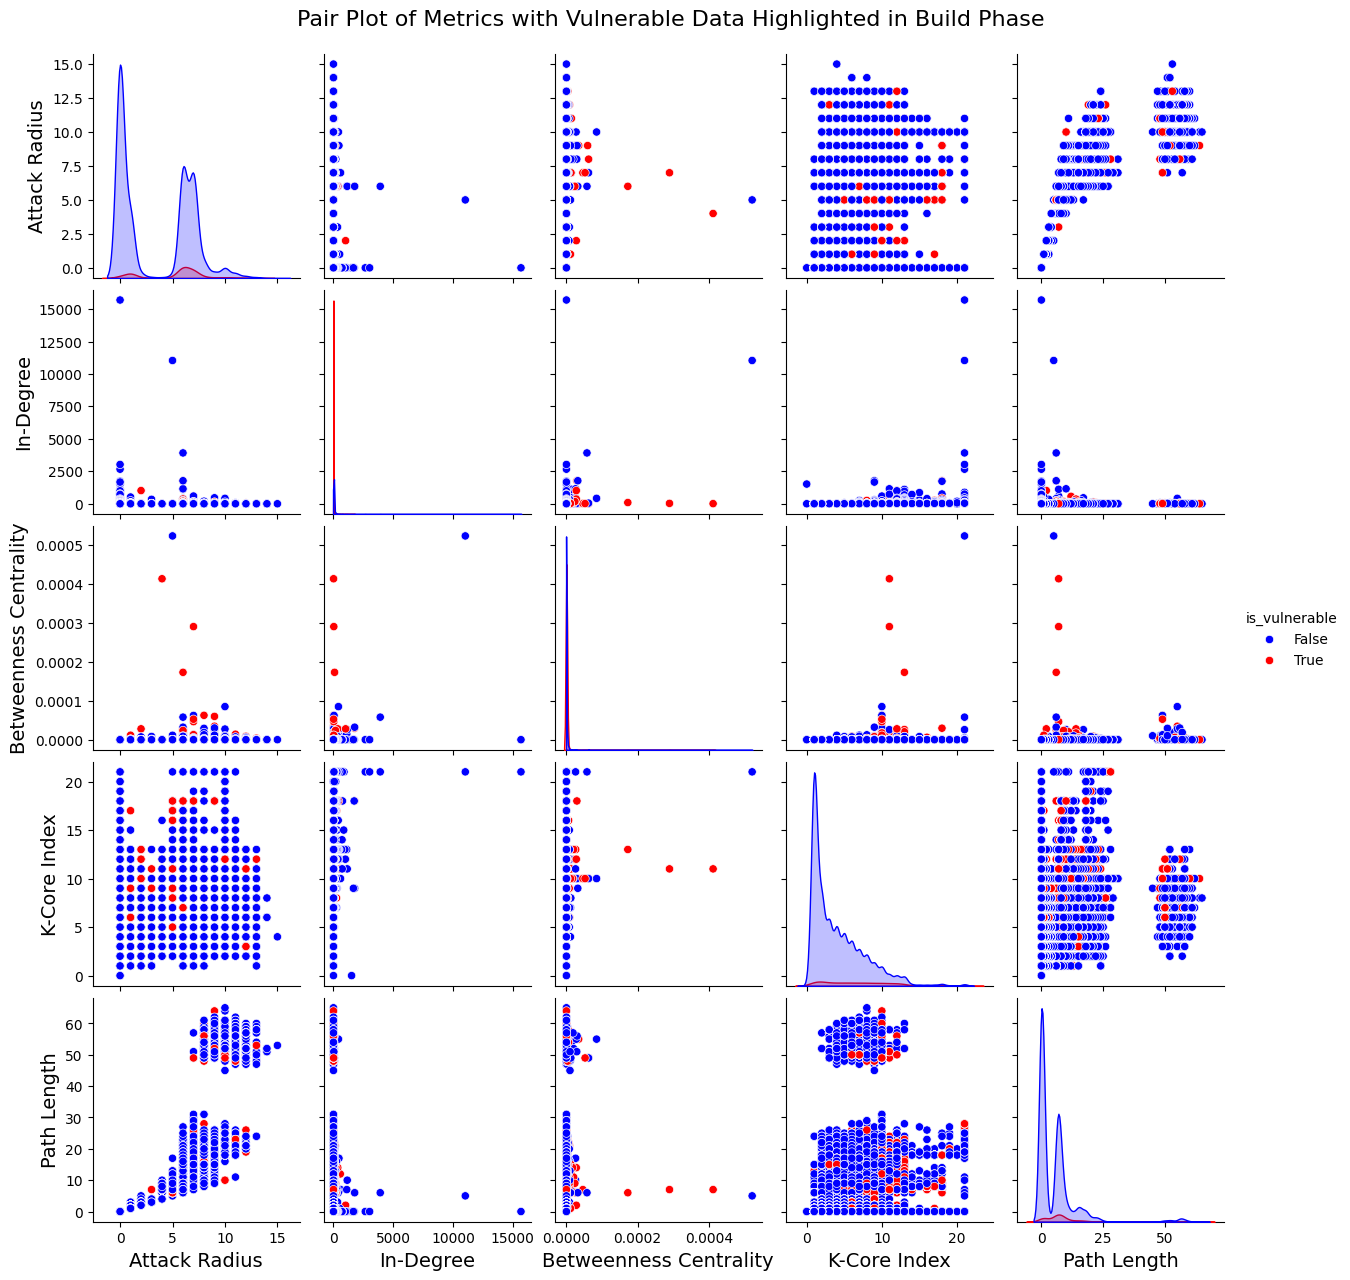

In [ ]:
# Create the pair plot with increased font sizes
pairplot = sns.pairplot(
    combined_df,
    vars=metrics,
    hue='is_vulnerable',
    palette={False: 'blue', True: 'red'},
)

# Increase the font size of the axis labels
for ax in pairplot.axes.flatten():
    ax.set_xlabel(ax.get_xlabel(), fontsize=14)
    ax.set_ylabel(ax.get_ylabel(), fontsize=14)

# Increase the font size of the overall title
plt.suptitle('Pair Plot of Metrics with Vulnerable Data Highlighted in Build Phase', y=1.02, fontsize=16)

# Show the plot
plt.show()

### compare the medians of vulnerables and non-vulnerables. do box plots. correlation b/w pop vs attack.

Comparison of Medians:
                   Metric  Median (Vulnerable)  Median (Non-Vulnerable)
0           Attack Radius                  6.0                      1.0
1               In-Degree                  0.0                      1.0
2  Betweenness Centrality                  0.0                      0.0
3            K-Core Index                  6.0                      3.0
4             Path Length                  7.0                      1.0


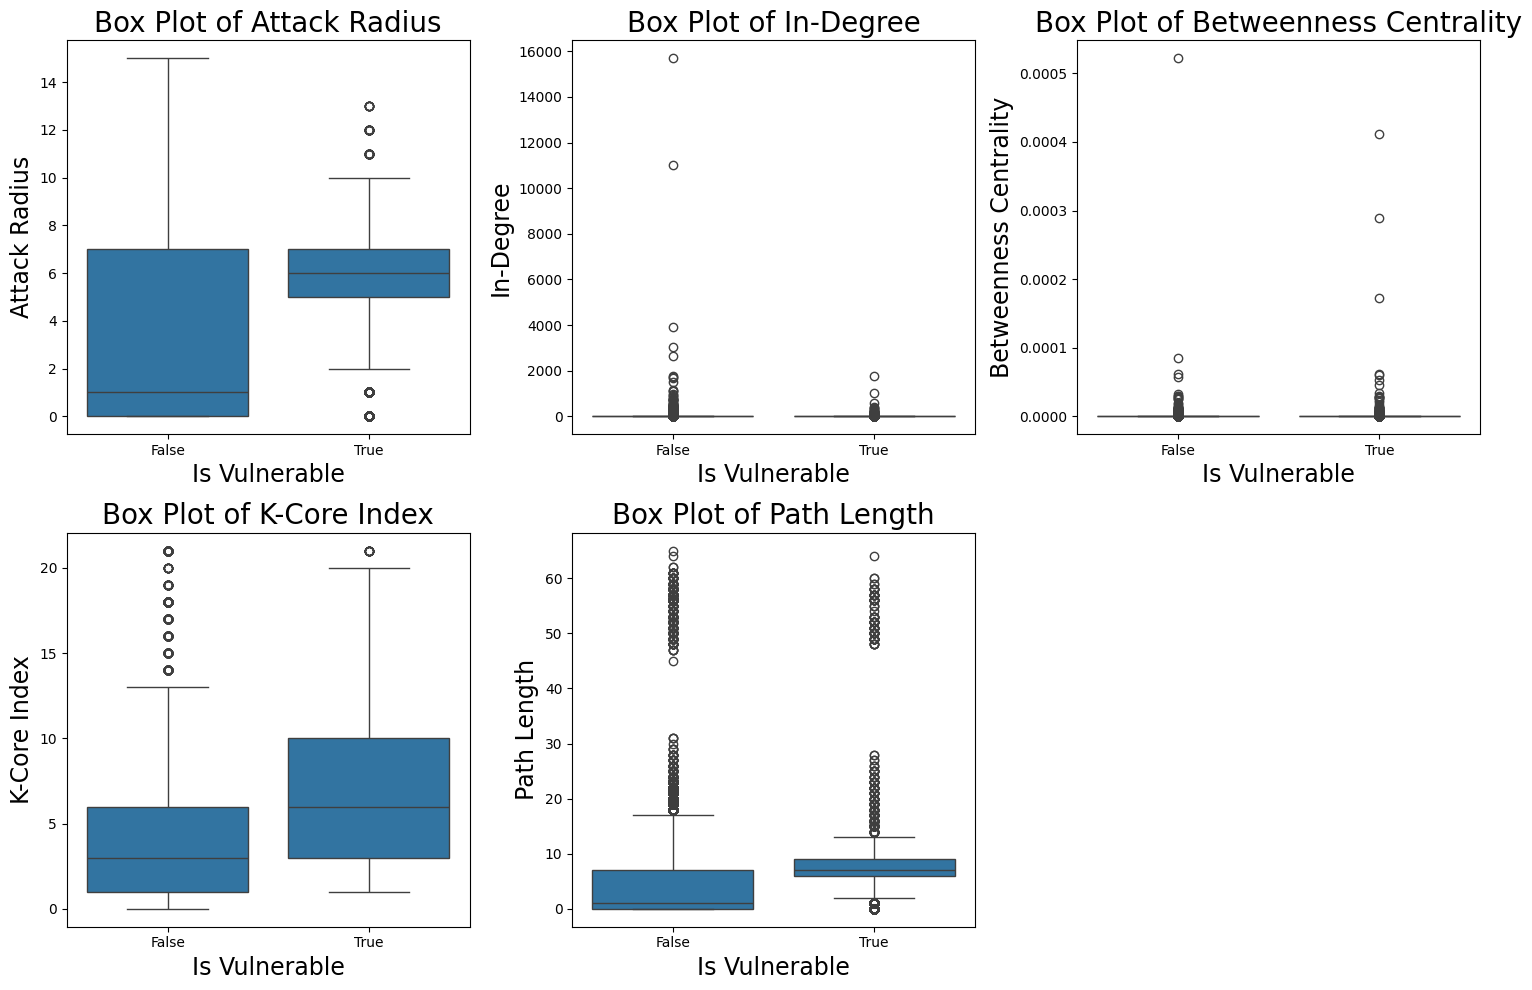

In [ ]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import pearsonr

# Assuming 'combined_df' is your DataFrame containing the risk metrics data

# Calculate and compare the medians for vulnerable and non-vulnerable packages
vulnerable = combined_df[combined_df['is_vulnerable'] == 1]
non_vulnerable = combined_df[combined_df['is_vulnerable'] == 0]
# metrics = ['Attack Radius', 'In-Degree', 'Betweenness Centrality', 'Core Value', 'Longest Path Length']

median_comparison = pd.DataFrame({
    'Metric': metrics,
    'Median (Vulnerable)': [vulnerable[metric].median() for metric in metrics],
    'Median (Non-Vulnerable)': [non_vulnerable[metric].median() for metric in metrics]
})

print("Comparison of Medians:")
print(median_comparison)

# Create box plots for each risk metric
plt.figure(figsize=(15, 10))
for i, metric in enumerate(metrics):
    plt.subplot( 2,3, i+1)
    sns.boxplot(x='is_vulnerable', y=metric, data=combined_df)
    plt.title(f'Box Plot of {metric}',fontsize=20 )
    plt.xlabel('Is Vulnerable', fontsize=17)
    plt.ylabel(metric, fontsize=17)

plt.tight_layout()
plt.show()


In [ ]:
common_pop = pd.merge(vuln_df, pop_df, left_on='Packages', right_on='name', how='inner')
print(common_pop.shape)

(2480, 9)


In [ ]:
common_pop = pd.merge(combined_df, pop_df, left_on='Node', right_on='name', how='inner').fillna(0)
print(common_pop.shape)
print(combined_df.shape)

(34586, 17)
(44286, 9)


In [ ]:
pop_df.head()

,rank,name,inst,vote,old,recent,no-files,maintainer
0,1,adduser,234785,211590,4924,18233,38,Debian Adduser Developers
1,2,libacl1,234785,214251,2906,17588,40,Guillem Jover
2,3,tar,234785,213292,3464,17986,43,Janos Lenart
3,4,passwd,234784,213145,3410,18191,38,Shadow Package Maintainers
4,5,debconf,234782,214125,2631,17996,30,Debconf Developers


In [ ]:
pop_df.describe()

,rank,inst,vote,old,recent,no-files
count,196176.000000,196176.000000,196176.000000,196176.000000,196176.000000,196176.000000
mean,98088.500000,1649.625285,568.080239,500.780151,151.937566,428.827329
std,56631.277542,12764.023097,6830.080624,4805.629262,1452.011026,4926.530059
min,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000
25%,49044.750000,1.000000,0.000000,0.000000,0.000000,0.000000
50%,98088.500000,5.000000,0.000000,1.000000,0.000000,0.000000
75%,147132.250000,42.000000,3.000000,10.000000,1.000000,3.000000
max,196176.000000,234785.000000,216900.000000,190955.000000,51393.000000,233134.000000


#### Proposition: Packages critical to the functionality(used more) are more likely to have high propagation costs, as a compromise in such a package could impact a larger portion of the supply chain.

In [ ]:
import pandas as pd

# Assuming 'pop_df' is your DataFrame

# Define a threshold for 'inst' values
threshold = 230000

# Create a new column to indicate if 'inst' is high or not
common_pop['is_high_inst'] = common_pop['inst'] > threshold

# List of metrics to compare
# metrics = ['Attack Radius', 'Core Value', 'In-Degree', 'Betweenness Centrality']

# Calculate statistics for high inst packages
high_inst_stats = common_pop[common_pop['is_high_inst']][metrics].describe()

# Calculate statistics for non-high inst packages
# non_high_inst_stats = common_pops[~common_pops['is_high_inst']][metrics].describe()

# Print the statistics
print("Statistics for High 'inst' Packages:")
print(high_inst_stats)

Statistics for High 'inst' Packages:
       Attack Radius    In-Degree  Betweenness Centrality  K-Core Index  \
count     107.000000   107.000000            1.070000e+02    107.000000   
mean        1.158879    23.074766            5.193546e-07      4.971963   
std         2.375780   102.162163            2.872349e-06      4.001080   
min         0.000000     0.000000            0.000000e+00      1.000000   
25%         0.000000     1.000000            0.000000e+00      2.000000   
50%         0.000000     3.000000            0.000000e+00      4.000000   
75%         1.000000    11.500000            2.043467e-09      8.000000   
max        12.000000  1016.000000            2.778964e-05     17.000000   

       Path Length  
count   107.000000  
mean      1.345794  
std       3.156613  
min       0.000000  
25%       0.000000  
50%       0.000000  
75%       1.000000  
max      23.000000  


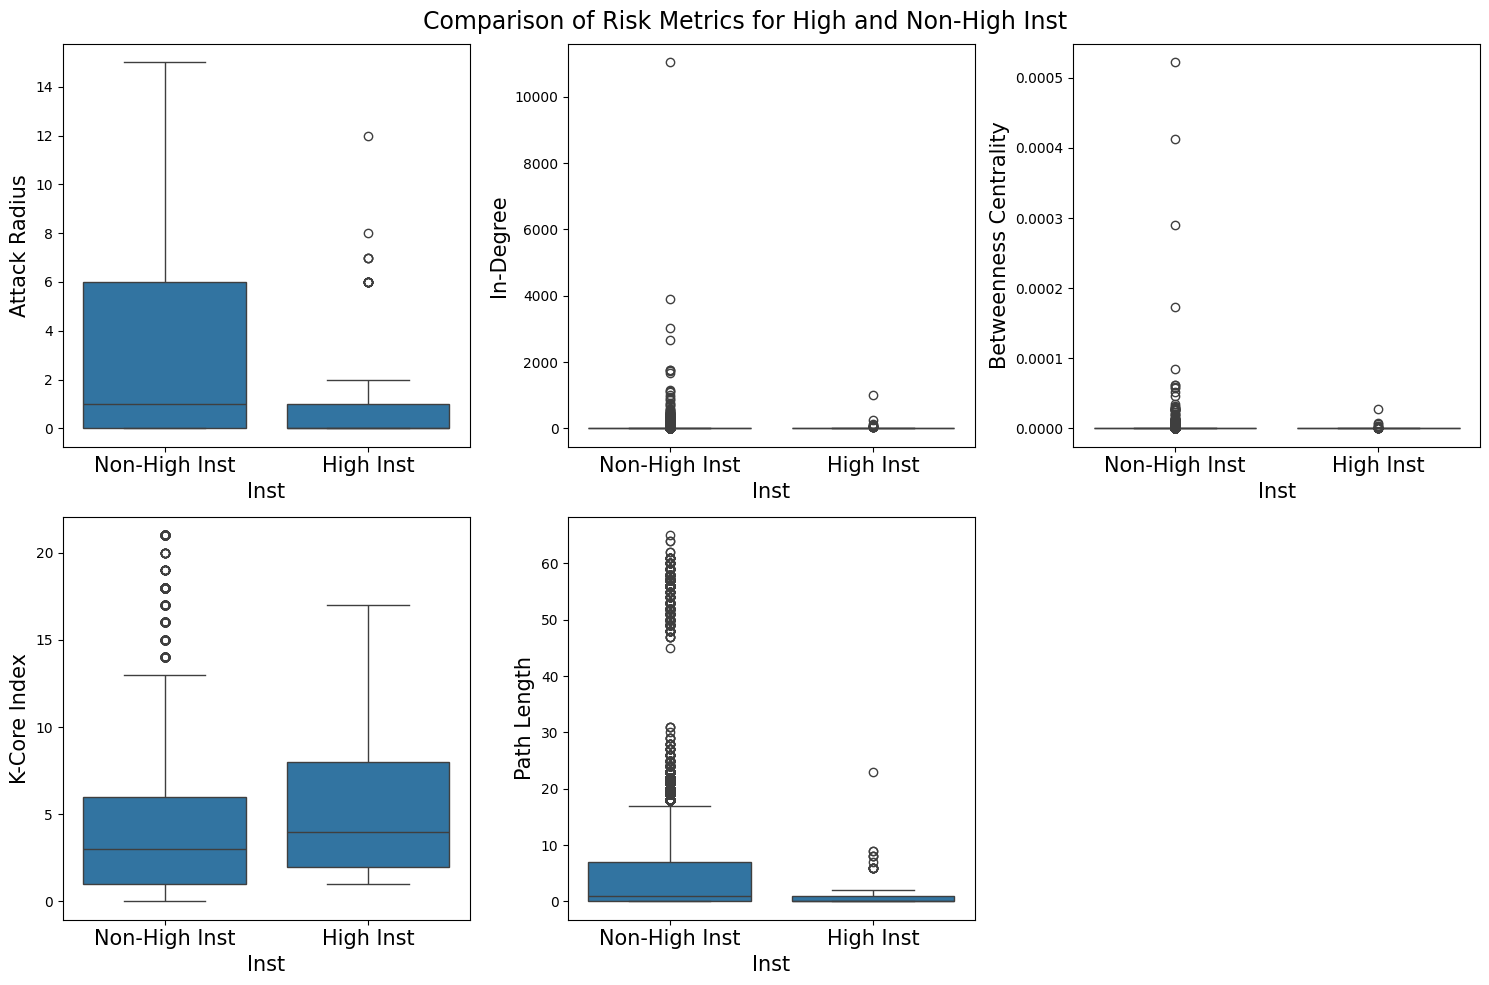

In [ ]:
threshold = 230000

# Create a new column to indicate if 'vote' is high or not
common_pop['is_high_inst'] = common_pop['inst'] > threshold

# Melt the DataFrame for seaborn's boxplot function
melted_df = pd.melt(common_pop, id_vars=['is_high_inst'], value_vars=metrics, var_name='metric', value_name='value')

# Set up the subplots
num_metrics = len(metrics)
fig, axes = plt.subplots(2, 3, figsize=(15, 10))

# Create a box plot for each metric
for i, metric in enumerate(metrics):
    sns.boxplot(x='is_high_inst', y='value', data=melted_df[melted_df['metric'] == metric], ax=axes.flat[i])
    # axes.flat[i].set_title(f'Comparison of {metric}', fontsize=15)
    axes.flat[i].set_xlabel('Inst', fontsize=15)
    axes.flat[i].set_ylabel(metric, fontsize=15)
    axes.flat[i].set_xticklabels(['Non-High Inst', 'High Inst'], fontsize=15)

# Remove the extra box at the end
for j in range(num_metrics, len(axes.flat)):
    fig.delaxes(axes.flat[j])

# Set title for all plots at once
fig.suptitle('Comparison of Risk Metrics for High and Non-High Inst', fontsize=17)

plt.tight_layout()
plt.show()


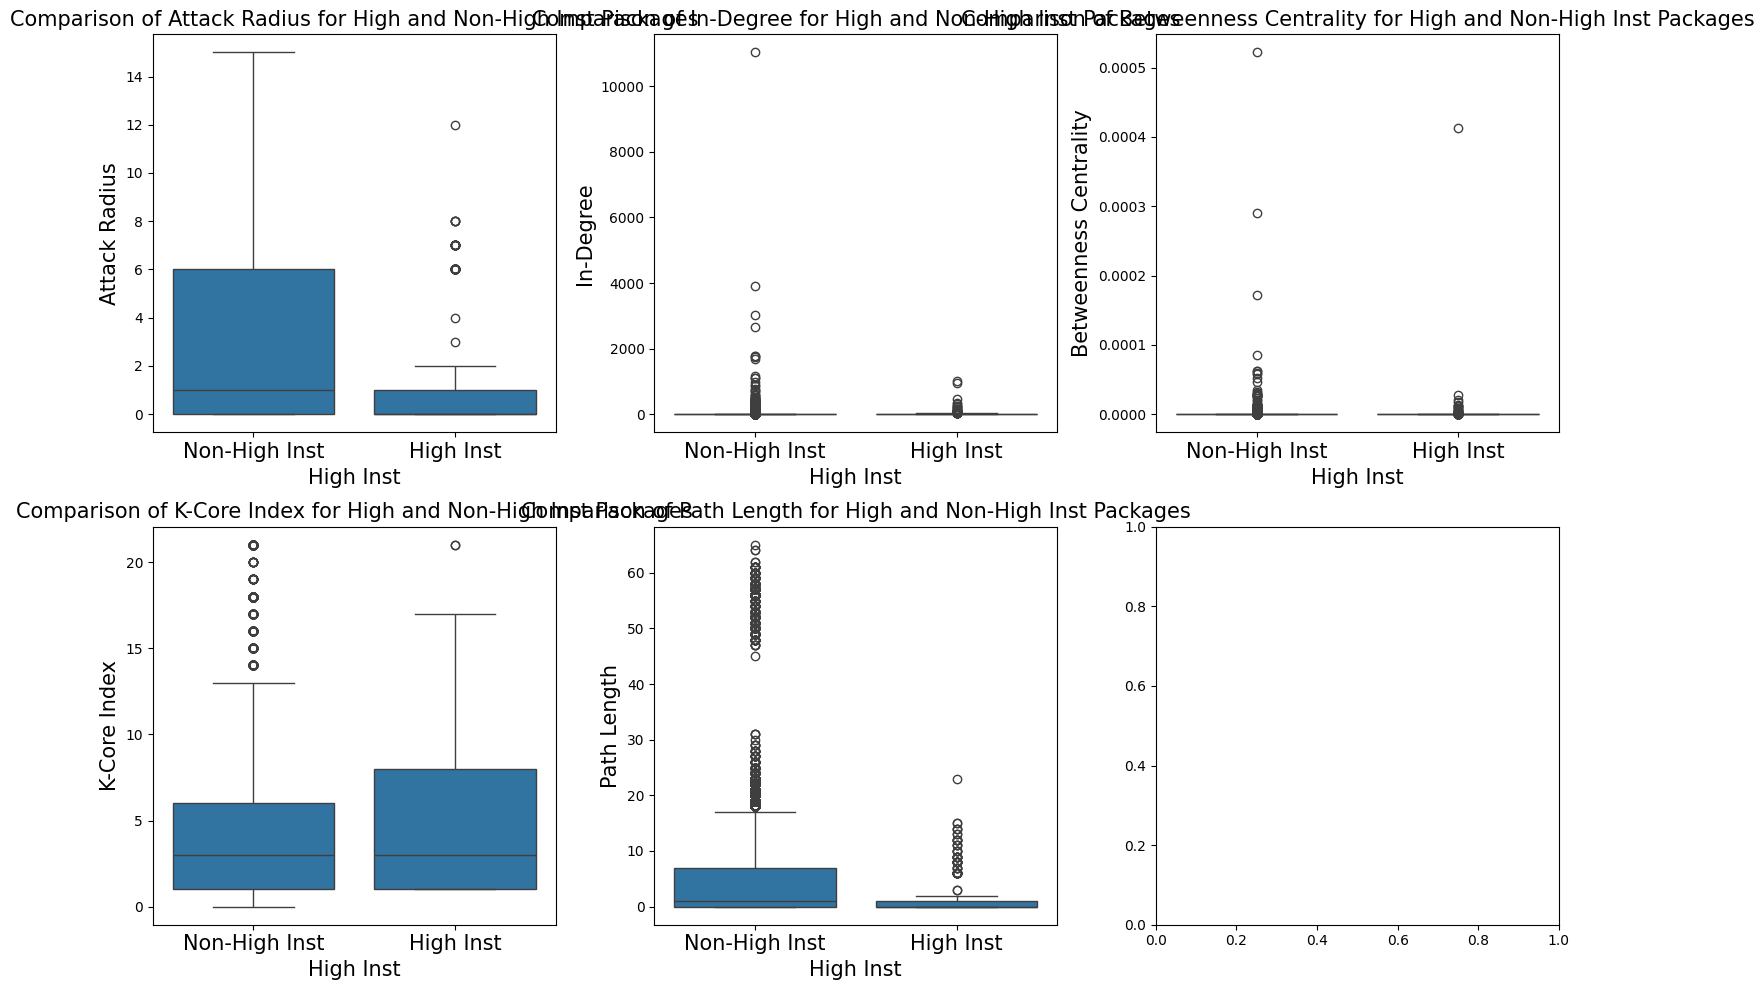

In [ ]:
common_pop_sorted = common_pop.sort_values(by='inst', ascending=False)
top_10_threshold = np.percentile(common_pop['inst'], 99)
# Create a new column to indicate if 'vote' is high or not
common_pop['is_high_inst'] = common_pop['inst'] > top_10_threshold

# Melt the DataFrame for seaborn's boxplot function
melted_df = pd.melt(common_pop, id_vars=['is_high_inst'], value_vars=metrics, var_name='metric', value_name='value')

# Set up the subplots
num_metrics = len(metrics)
fig, axes = plt.subplots(2, 3, figsize=(15, 10))

# Create a box plot for each metric
for i, metric in enumerate(metrics):
    sns.boxplot(x='is_high_inst', y='value', data=melted_df[melted_df['metric'] == metric], ax=axes.flat[i])
    axes.flat[i].set_title(f'Comparison of {metric} for High and Non-High Inst Packages', fontsize=15)
    axes.flat[i].set_xlabel('High Inst', fontsize=15)
    axes.flat[i].set_ylabel(metric, fontsize=15)
    axes.flat[i].set_xticklabels(['Non-High Inst', 'High Inst'], fontsize=15)

plt.tight_layout()
plt.show()

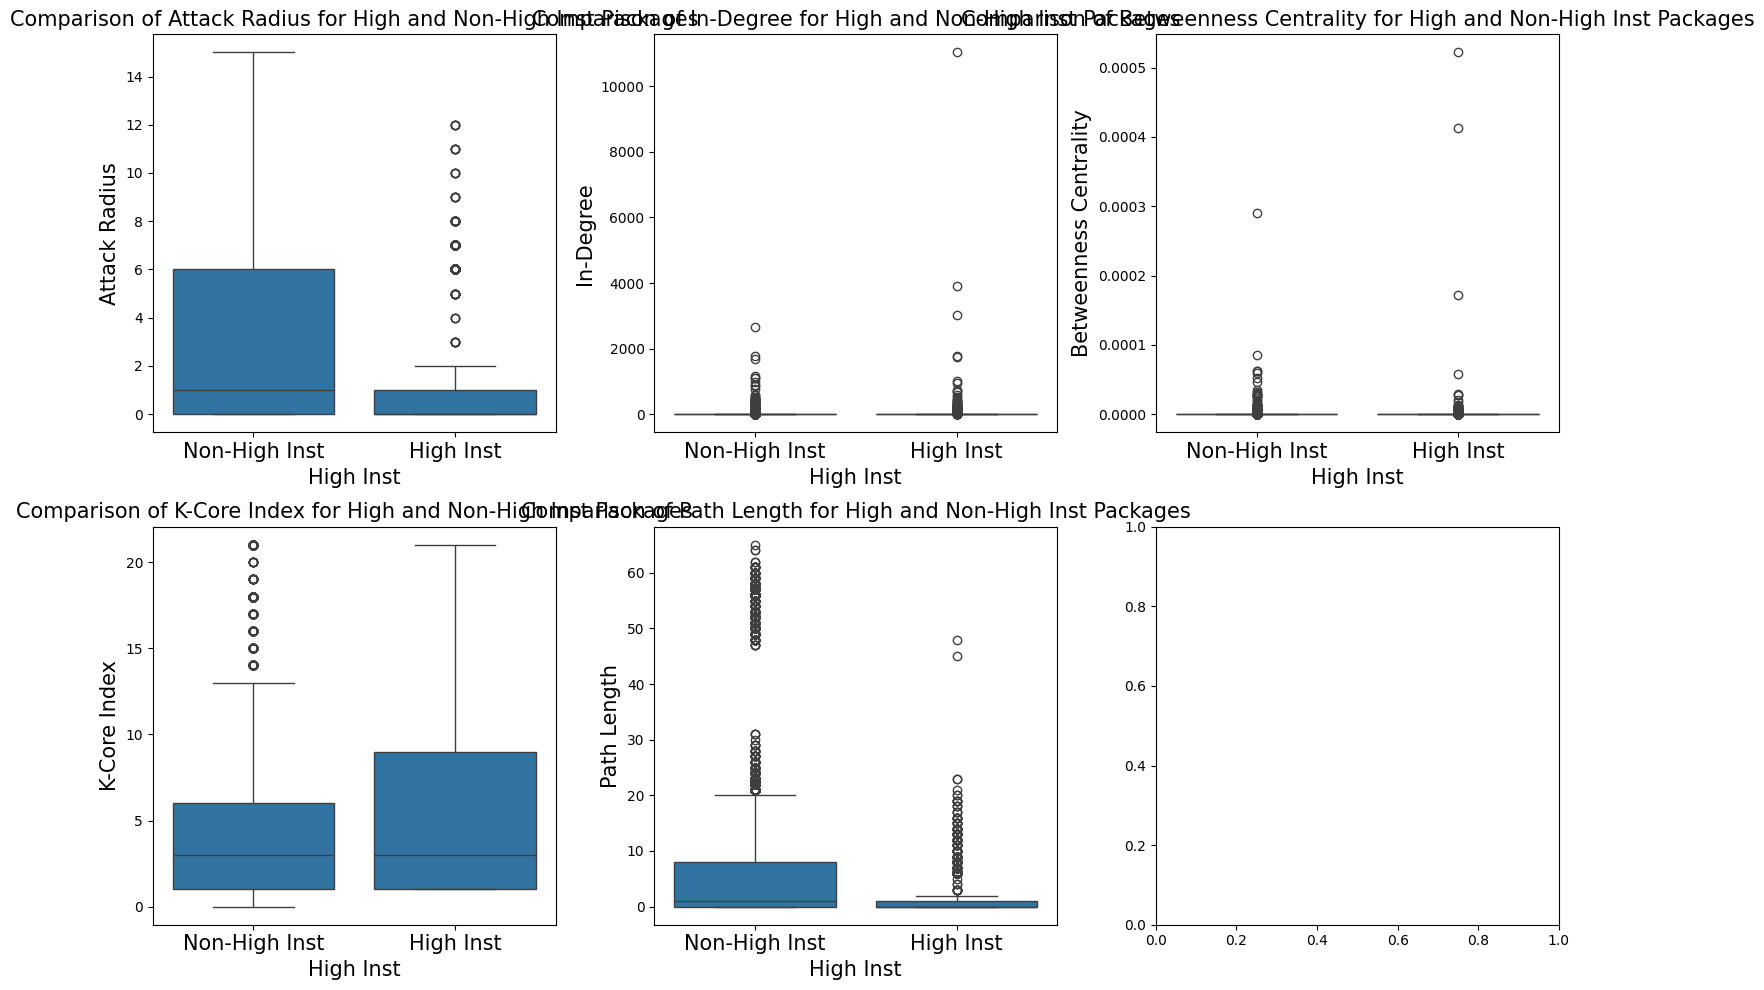

In [ ]:
common_pop_sorted = common_pop.sort_values(by='inst', ascending=False)
top_10_threshold = np.percentile(common_pop['inst'], 95)
# Create a new column to indicate if 'vote' is high or not
common_pop['is_high_inst'] = common_pop['inst'] > top_10_threshold

# Melt the DataFrame for seaborn's boxplot function
melted_df = pd.melt(common_pop, id_vars=['is_high_inst'], value_vars=metrics, var_name='metric', value_name='value')

# Set up the subplots
num_metrics = len(metrics)
fig, axes = plt.subplots(2, 3, figsize=(15, 10))

# Create a box plot for each metric
for i, metric in enumerate(metrics):
    sns.boxplot(x='is_high_inst', y='value', data=melted_df[melted_df['metric'] == metric], ax=axes.flat[i])
    axes.flat[i].set_title(f'Comparison of {metric} for High and Non-High Inst Packages', fontsize=15)
    axes.flat[i].set_xlabel('High Inst', fontsize=15)
    axes.flat[i].set_ylabel(metric, fontsize=15)
    axes.flat[i].set_xticklabels(['Non-High Inst', 'High Inst'], fontsize=15)

plt.tight_layout()
plt.show()

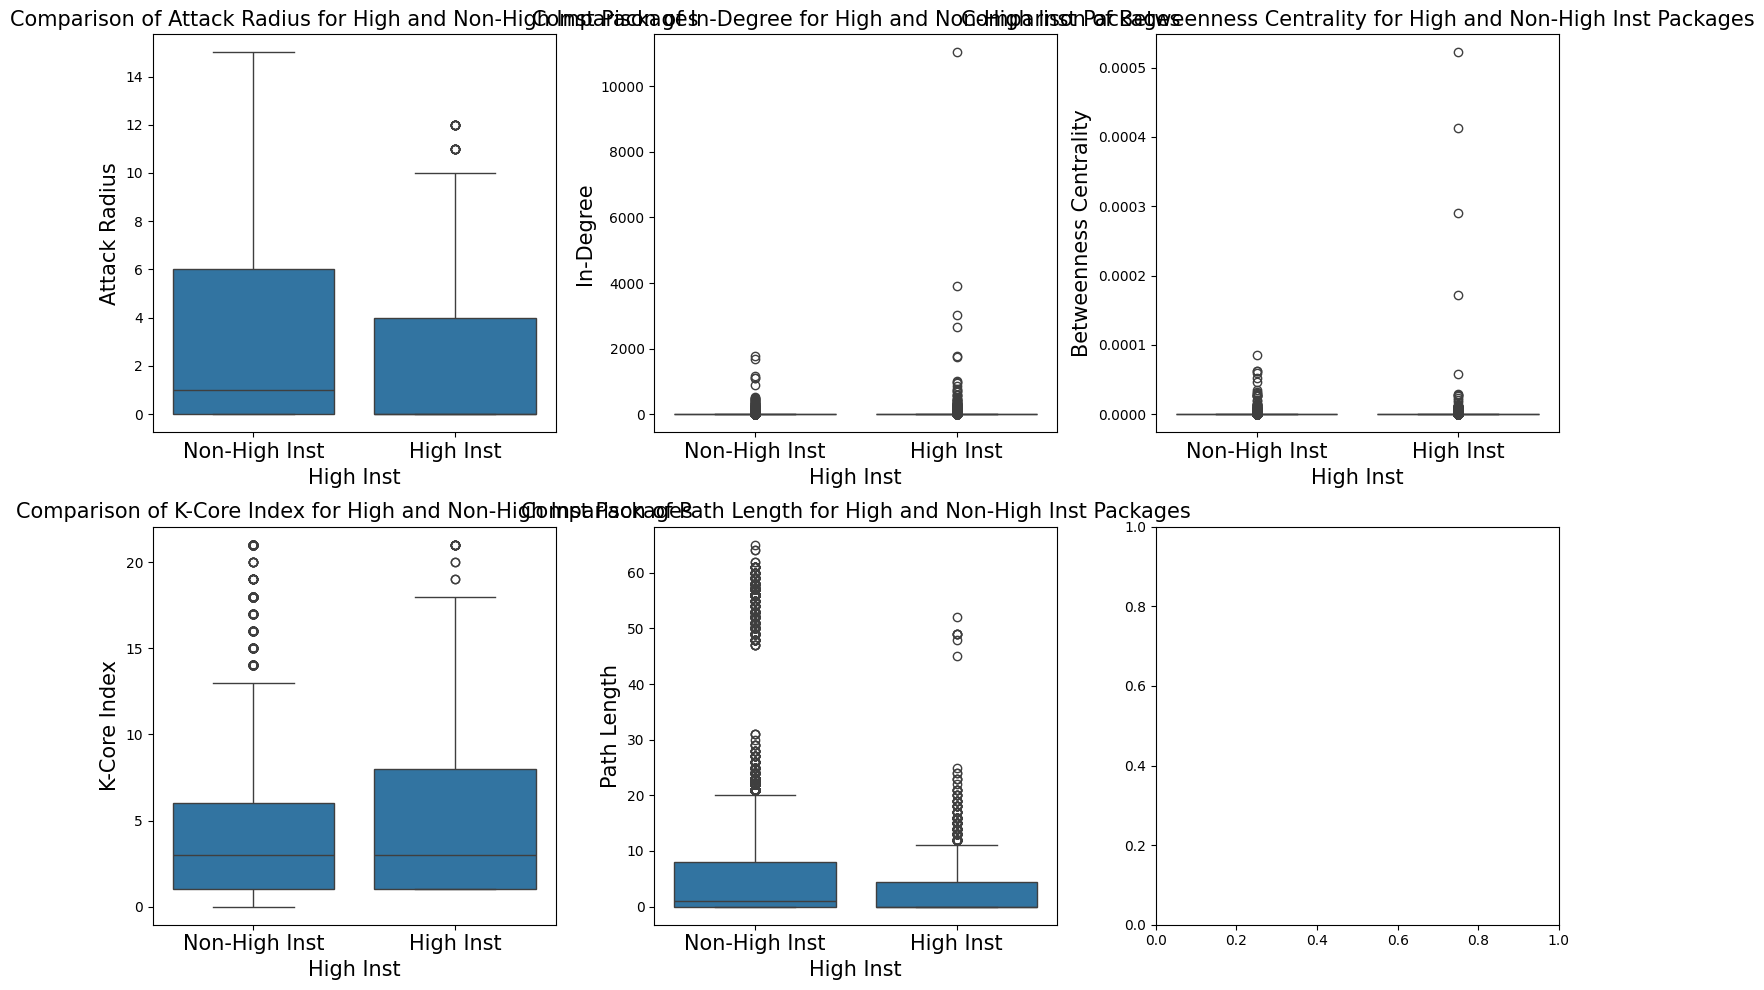

In [ ]:
common_pop_sorted = common_pop.sort_values(by='inst', ascending=False)
top_10_threshold = np.percentile(common_pop['inst'], 90)
# Create a new column to indicate if 'vote' is high or not
common_pop['is_high_inst'] = common_pop['inst'] > top_10_threshold

# Melt the DataFrame for seaborn's boxplot function
melted_df = pd.melt(common_pop, id_vars=['is_high_inst'], value_vars=metrics, var_name='metric', value_name='value')

# Set up the subplots
num_metrics = len(metrics)
fig, axes = plt.subplots(2, 3, figsize=(15, 10))

# Create a box plot for each metric
for i, metric in enumerate(metrics):
    sns.boxplot(x='is_high_inst', y='value', data=melted_df[melted_df['metric'] == metric], ax=axes.flat[i])
    axes.flat[i].set_title(f'Comparison of {metric} for High and Non-High Inst Packages', fontsize=15)
    axes.flat[i].set_xlabel('High Inst', fontsize=15)
    axes.flat[i].set_ylabel(metric, fontsize=15)
    axes.flat[i].set_xticklabels(['Non-High Inst', 'High Inst'], fontsize=15)

plt.tight_layout()
plt.show()

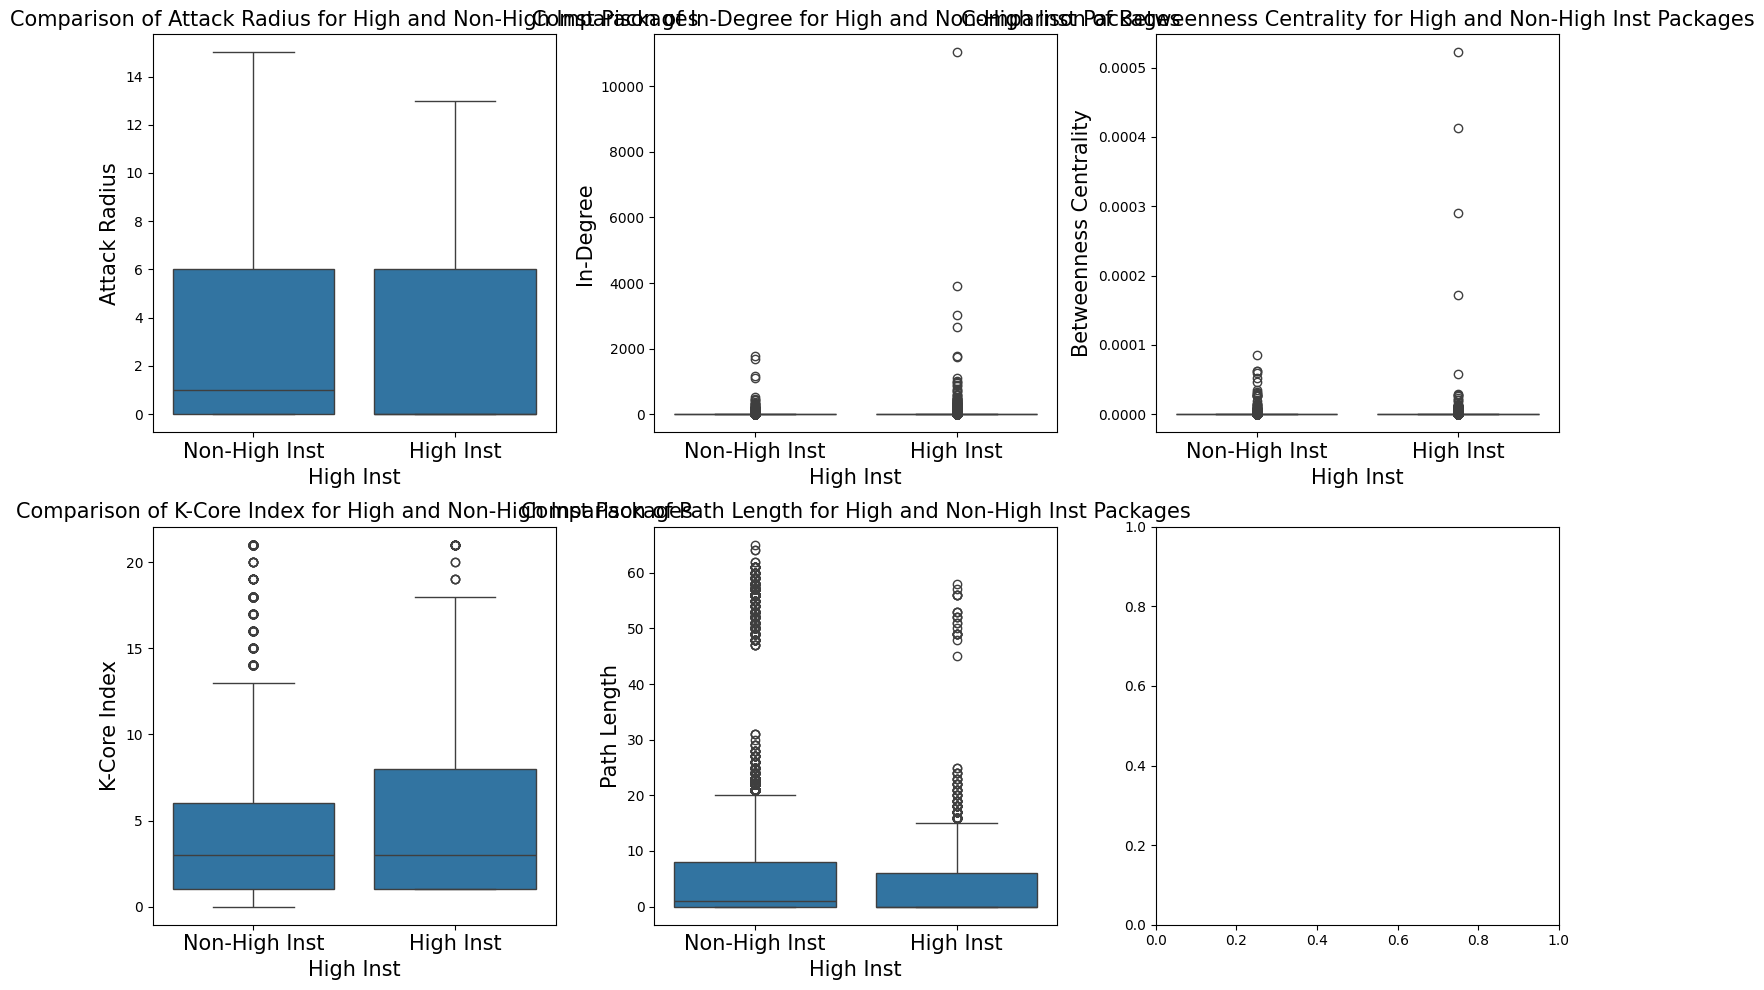

In [ ]:
common_pop_sorted = common_pop.sort_values(by='inst', ascending=False)
top_10_threshold = np.percentile(common_pop['inst'], 85)
# Create a new column to indicate if 'vote' is high or not
common_pop['is_high_inst'] = common_pop['inst'] > top_10_threshold

# Melt the DataFrame for seaborn's boxplot function
melted_df = pd.melt(common_pop, id_vars=['is_high_inst'], value_vars=metrics, var_name='metric', value_name='value')

# Set up the subplots
num_metrics = len(metrics)
fig, axes = plt.subplots(2, 3, figsize=(15, 10))

# Create a box plot for each metric
for i, metric in enumerate(metrics):
    sns.boxplot(x='is_high_inst', y='value', data=melted_df[melted_df['metric'] == metric], ax=axes.flat[i])
    axes.flat[i].set_title(f'Comparison of {metric} for High and Non-High Inst Packages', fontsize=15)
    axes.flat[i].set_xlabel('High Inst', fontsize=15)
    axes.flat[i].set_ylabel(metric, fontsize=15)
    axes.flat[i].set_xticklabels(['Non-High Inst', 'High Inst'], fontsize=15)

plt.tight_layout()
plt.show()

In [ ]:
from scipy.stats import chi2_contingency, pearsonr, spearmanr, wilcoxon

# Perform Wilcoxon signed-rank test between all combinations of metrics
wilcoxon_results = []
# Chi-Square Test between metrics and inst (assuming both are categorical)
chi_square_results = []
for metric in metrics:
    contingency_table = pd.crosstab(common_pop[metric], common_pop['inst'])
    chi2, p, dof, ex = chi2_contingency(contingency_table)
    chi_square_results.append({'Metric': metric, 'Chi2 Statistic': chi2, 'p-value': p})
    stat, p_value = wilcoxon(common_pop[metric], common_pop['inst'])
    wilcoxon_results.append({
        'Metric': metric,
        'Statistic': stat,
        'p-value': p_value,
        'Significant': p_value < 0.05
    })

chi_square_df = pd.DataFrame(chi_square_results)
print("Chi-Square Test Results:")
print(chi_square_df)

wilcoxon_df = pd.DataFrame(wilcoxon_results)
print("\nWilcoxon Signed-Rank Test Results:")
print(wilcoxon_df)

# Correlation analysis between metrics and inst
correlation_results = []
for metric in metrics:
    pearson_corr, pearson_p = pearsonr(common_pop[metric], common_pop['inst'])
    spearman_corr, spearman_p = spearmanr(common_pop[metric], common_pop['inst'])
    correlation_results.append({
        'Metric': metric,
        'Pearson Correlation': pearson_corr,
        'Pearson p-value': pearson_p,
        'Spearman Correlation': spearman_corr,
        'Spearman p-value': spearman_p
    })

correlation_df = pd.DataFrame(correlation_results)
print("\nCorrelation Analysis Results:")
print(correlation_df)

    # if significant:
    #     print("The result is significant (p < 0.05), indicating a difference between the distributions.")
    # else:
    #     print("The result is not significant (p >= 0.05), indicating no difference between the distributions.")


Chi-Square Test Results:
                   Metric  Chi2 Statistic  p-value
0           Attack Radius    7.547394e+04      1.0
1               In-Degree    5.585824e+06      0.0
2  Betweenness Centrality    4.211844e+07      0.0
3            K-Core Index    2.095467e+05      0.0
4             Path Length    1.960666e+05      1.0

Wilcoxon Signed-Rank Test Results:
                   Metric   Statistic  p-value  Significant
0           Attack Radius   8080414.5      0.0         True
1               In-Degree    868659.5      0.0         True
2  Betweenness Centrality         0.0      0.0         True
3            K-Core Index   6437980.5      0.0         True
4             Path Length  20808745.5      0.0         True

Correlation Analysis Results:
                   Metric  Pearson Correlation  Pearson p-value  \
0           Attack Radius            -0.099694     4.172624e-77   
1               In-Degree             0.051797     5.469997e-22   
2  Betweenness Centrality             0.0

## Modeling Risks

In [ ]:
import pandas as pd
import numpy as np
from sklearn import linear_model
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from mlxtend.feature_selection import SequentialFeatureSelector
from imblearn.over_sampling import SMOTE
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
import pandas as pd
import numpy as np
import statsmodels.api as sm

In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score,confusion_matrix, classification_report
from sklearn.feature_selection import SequentialFeatureSelector
import statsmodels.api as sm

# Load your data into combined_df
# Example:
# combined_df = pd.read_csv('your_data.csv')

# Define the feature matrix and target variable
# X = combined_df[['Attack Radius', 'In-Degree', 'Betweenness Centrality', 'Core Value', 'Longest Path Length']]
X = combined_df[['Attack Radius', 'In-Degree','Betweenness Centrality', 'K-Core Index', 'Path Length']]
y = combined_df['is_vulnerable']

# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

# Perform stepwise feature selection
sfs = SequentialFeatureSelector(LogisticRegression(max_iter=1000),
                                n_features_to_select='auto',
                                direction='forward',
                                scoring='accuracy',
                                cv=5)
sfs.fit(X_train, y_train)

# Get the selected features
selected_features = sfs.get_support(indices=True)
X_train_selected = X_train.iloc[:, selected_features]
X_test_selected = X_test.iloc[:, selected_features]

# Fit a logistic regression model using the selected features
logreg = LogisticRegression(max_iter=1000)
logreg.fit(X_train_selected, y_train)

# Make predictions using the test set
y_pred = logreg.predict(X_test_selected)

# Evaluate the model performance
accuracy = accuracy_score(y_test, y_pred)
print(f'Accuracy: {accuracy}')
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))
print("Classification Report:\n", classification_report(y_test, y_pred))

Accuracy: 0.938732500376336
Confusion Matrix:
 [[12472     0]
 [  814     0]]
Classification Report:
               precision    recall  f1-score   support

       False       0.94      1.00      0.97     12472
        True       0.00      0.00      0.00       814

    accuracy                           0.94     13286
   macro avg       0.47      0.50      0.48     13286
weighted avg       0.88      0.94      0.91     13286



In [ ]:
from imblearn.over_sampling import SMOTE
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
import pandas as pd

# Assuming 'data' is your DataFrame containing the risk metrics data

# Split the data into independent variables (X) and dependent variable (y)
X = combined_df[['Attack Radius', 'In-Degree', 'Betweenness Centrality','K-Core Index', 'Path Length']]
y = combined_df['is_vulnerable']

# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.4, random_state=42)

# Apply SMOTE to the training data
smote = SMOTE(random_state=42)
X_train_smote, y_train_smote = smote.fit_resample(X_train, y_train)

# Logistic Regression Model
logistic_model = LogisticRegression(max_iter=1000,class_weight='balanced')
logistic_model.fit(X_train_smote, y_train_smote)
y_pred_logistic = logistic_model.predict(X_test)

# Decision Tree Model
decision_tree_model = DecisionTreeClassifier(class_weight='balanced')
decision_tree_model.fit(X_train_smote, y_train_smote)
y_pred_dt = decision_tree_model.predict(X_test)

# Evaluate the models
print("Logistic Regression Model:")
print("Accuracy:", accuracy_score(y_test, y_pred_logistic))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred_logistic))
print("Classification Report:\n", classification_report(y_test, y_pred_logistic))

Logistic Regression Model:
Accuracy: 0.6126446514253457
Confusion Matrix:
 [[10147  6492]
 [  370   706]]
Classification Report:
               precision    recall  f1-score   support

       False       0.96      0.61      0.75     16639
        True       0.10      0.66      0.17      1076

    accuracy                           0.61     17715
   macro avg       0.53      0.63      0.46     17715
weighted avg       0.91      0.61      0.71     17715



In [ ]:
print("\nDecision Tree Model:")
print("Accuracy:", accuracy_score(y_test, y_pred_dt))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred_dt))
print("Classification Report:\n", classification_report(y_test, y_pred_dt))


Decision Tree Model:
Accuracy: 0.7259384702229749
Confusion Matrix:
 [[12345  4294]
 [  561   515]]
Classification Report:
               precision    recall  f1-score   support

       False       0.96      0.74      0.84     16639
        True       0.11      0.48      0.18      1076

    accuracy                           0.73     17715
   macro avg       0.53      0.61      0.51     17715
weighted avg       0.90      0.73      0.80     17715



In [ ]:
from imblearn.over_sampling import BorderlineSMOTE
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
from sklearn.model_selection import train_test_split

# Apply Borderline-SMOTE to the training data
smote = BorderlineSMOTE(random_state=42)
X_train_smote, y_train_smote = smote.fit_resample(X_train, y_train)

# Random Forest Model
rf_model = RandomForestClassifier(random_state=42)
rf_model.fit(X_train_smote, y_train_smote)
y_pred_rf = rf_model.predict(X_test)

# Evaluate the model
print("Random Forest Model:")
print("Accuracy:", accuracy_score(y_test, y_pred_rf))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred_rf))
print("Classification Report:\n", classification_report(y_test, y_pred_rf))



Random Forest Model:
Accuracy: 0.8296359017781542
Confusion Matrix:
 [[14343  2296]
 [  722   354]]
Classification Report:
               precision    recall  f1-score   support

       False       0.95      0.86      0.90     16639
        True       0.13      0.33      0.19      1076

    accuracy                           0.83     17715
   macro avg       0.54      0.60      0.55     17715
weighted avg       0.90      0.83      0.86     17715



In [ ]:
from sklearn.model_selection import cross_val_score, cross_val_predict, StratifiedKFold
from sklearn.ensemble import RandomForestClassifier
from imblearn.over_sampling import BorderlineSMOTE
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, make_scorer
import pandas as pd

# Assuming 'X_train' and 'y_train' are your training features and target variable

# Apply Borderline-SMOTE to the data
smote = BorderlineSMOTE(random_state=42)
X_resampled, y_resampled = smote.fit_resample(X_train, y_train)

# Combine the resampled features and target variable into a single DataFrame
resampled_df = pd.DataFrame(X_resampled, columns=X_train.columns)
resampled_df['Target'] = y_resampled

# Create a Random Forest Classifier
rf_classifier = RandomForestClassifier(random_state=42)

# Create a stratified k-fold cross-validator
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Convert the accuracy_score metric to a scorer
accuracy_scorer = make_scorer(accuracy_score)

# Perform cross-validation
# cv_results = cross_val_score(rf_classifier, X_resampled, y_resampled, cv=cv, scoring=accuracy_scorer)
# print("Cross-validation scores:", cv_results)

# Perform cross-validated predictions
y_pred = cross_val_predict(rf_classifier, X_resampled, y_resampled, cv=cv)

# Evaluate the predictions
print("Random Forest Classifier on resampled data")
print("Accuracy:", accuracy_score(y_resampled, y_pred))
print("Confusion Matrix:\n", confusion_matrix(y_resampled, y_pred))
print("Classification Report:\n", classification_report(y_resampled, y_pred))

# Fit the classifier to the entire resampled dataset
rf_classifier.fit(X_resampled, y_resampled)

Random Forest Classifier on resampled data
Accuracy: 0.8970629538980058
Confusion Matrix:
 [[21462  3461]
 [ 1670 23253]]
Classification Report:
               precision    recall  f1-score   support

       False       0.93      0.86      0.89     24923
        True       0.87      0.93      0.90     24923

    accuracy                           0.90     49846
   macro avg       0.90      0.90      0.90     49846
weighted avg       0.90      0.90      0.90     49846



RandomForestClassifier(random_state=42)

In [ ]:
# # Identify misclassified samples
misclassified_indices = [index for index, (actual, predicted) in enumerate(zip(y_resampled, y_pred)) if actual != predicted]
misclassified_samples = resampled_df.iloc[misclassified_indices]

# Filter misclassified samples where actual label is True (1)
misclassified_true_samples = misclassified_samples[misclassified_samples['Target'] == 1]
unique_misclassified_true_samples = misclassified_true_samples.drop_duplicates()

print("Misclassified samples where actual label is True:")
print(unique_misclassified_true_samples)
misclassified_samples.to_csv('misclassified_samples_source.csv', index=False)
unique_misclassified_true_samples.to_csv('misclassified_vulnerable_samples_source.csv', index=False)
# # print("Actual labels of misclassified samples where actual label is True:")
# # print(misclassified_true_samples['Target'])
# # print("Predicted labels of misclassified samples where actual label is True:")
# # print(pd.Series(y_pred).iloc[misclassified_indices][misclassified_true_samples.index].values)

Misclassified samples where actual label is True:
       Attack Radius  In-Degree  Betweenness Centrality  K-Core Index  \
3                  1          3            4.318261e-10      3.000000   
55                10          0            0.000000e+00      5.000000   
92                 7          0            0.000000e+00      4.000000   
156                7          0            0.000000e+00      4.000000   
343                0          2            0.000000e+00      2.000000   
...              ...        ...                     ...           ...   
49440              1          1            4.064134e-08      2.000000   
49542              1          1            4.253625e-10      2.000000   
49695              0        192            0.000000e+00     13.903385   
49793             10          0            2.013939e-08      9.000000   
49819              1          1            2.137027e-10      2.000000   

       Path Length  Target  
3              1.0    True  
55            2

In [ ]:
# Identify correctly classified samples
correctly_classified_indices = [index for index, (actual, predicted) in enumerate(zip(y_resampled, y_pred)) if actual == predicted]
correctly_classified_samples = resampled_df.iloc[correctly_classified_indices]

# Filter correctly classified samples where actual label is True (1)
correctly_classified_true_samples = correctly_classified_samples[correctly_classified_samples['Target'] == 1]

# Get unique correctly classified samples
unique_correctly_classified_true_samples = correctly_classified_true_samples.drop_duplicates()
unique_misclassified_true_samples.to_csv('vulnerable_samples.csv', index=False)

print("Unique correctly classified samples where actual label is True:")
print(unique_correctly_classified_true_samples)

Unique correctly classified samples where actual label is True:
        Attack Radius  In-Degree  K-Core Index  Path Length  Target
80                 12          1           382          873    True
206                11          0           331          875    True
330                11          1           344          872    True
504                11          1           548          878    True
858                11          2           414          873    True
...               ...        ...           ...          ...     ...
412787             11        349           462          873    True
412797             11        175           392          874    True
412837             11        915           513          876    True
412869             11      20005           576          870    True
412879             11        474           497          859    True

[16720 rows x 5 columns]


In [ ]:
shape_of_vulnerable_samples = combined_df[combined_df['is_vulnerable'] == 1].shape
print("Shape of combined_df where is_vulnerable is equal to 1:", shape_of_vulnerable_samples)

Shape of combined_df where is_vulnerable is equal to 1: (3471, 7)


In [ ]:
from sklearn.model_selection import cross_val_score
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, KFold
from imblearn.over_sampling import BorderlineSMOTE, ADASYN
from sklearn.metrics import make_scorer, accuracy_score
from sklearn.model_selection import cross_val_predict

# Assuming 'X' and 'y' are your features and target variable

# Apply Borderline-SMOTE or ADASYN to the data
smote = BorderlineSMOTE(random_state=42)
# smote = ADASYN(random_state=42)
X_resampled, y_resampled = smote.fit_resample(X_train, y_train)

# Create a Random Forest Classifier
rf_classifier = RandomForestClassifier(random_state=42)

# Create a stratified k-fold cross-validator
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# # Perform cross-validation
cv_results = cross_val_score(rf_classifier, X_resampled, y_resampled, cv=cv, scoring=make_scorer(accuracy_score))
print(cv_results)
# Perform cross-validated predictions
y_pred = cross_val_predict(rf_classifier, X_resampled, y_resampled, cv=cv)

# Evaluate the predictions
print("Random Forest Classifier on training data")
print("Accuracy:", accuracy_score(y_resampled, y_pred))
print("Confusion Matrix:\n", confusion_matrix(y_resampled, y_pred))
print("Classification Report:\n", classification_report(y_resampled, y_pred))

# Fit the classifier to the data
rf_classifier.fit(X_resampled, y_resampled)

feature_importance = rf_classifier.feature_importances_
# Assuming 'X' is your feature DataFrame
feature_importance_df = pd.DataFrame({'Feature': X_resampled.columns, 'Importance': feature_importance})
print(feature_importance_df)


[0.97616856 0.97587764 0.97689485 0.97750033 0.97676165]
Random Forest Classifier on training data
Accuracy: 0.9766406068356196
Confusion Matrix:
 [[197897   8551]
 [  1094 205354]]
Classification Report:
               precision    recall  f1-score   support

       False       0.99      0.96      0.98    206448
        True       0.96      0.99      0.98    206448

    accuracy                           0.98    412896
   macro avg       0.98      0.98      0.98    412896
weighted avg       0.98      0.98      0.98    412896

         Feature  Importance
0  Attack Radius    0.475501
1      In-Degree    0.020983
2   K-Core Index    0.215087
3    Path Length    0.288429


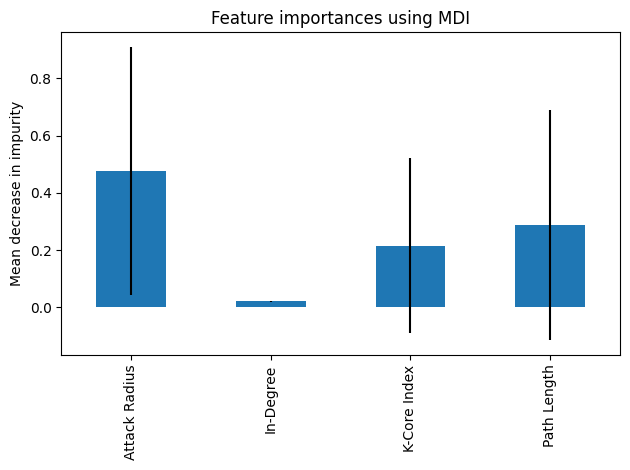

In [ ]:
forest_importances = pd.Series(feature_importance, index=X_resampled.columns)
std = np.std([tree.feature_importances_ for tree in rf_classifier.estimators_], axis=0)
fig, ax = plt.subplots()
forest_importances.plot.bar(yerr=std, ax=ax)
ax.set_title("Feature importances using MDI")
ax.set_ylabel("Mean decrease in impurity")
fig.tight_layout()

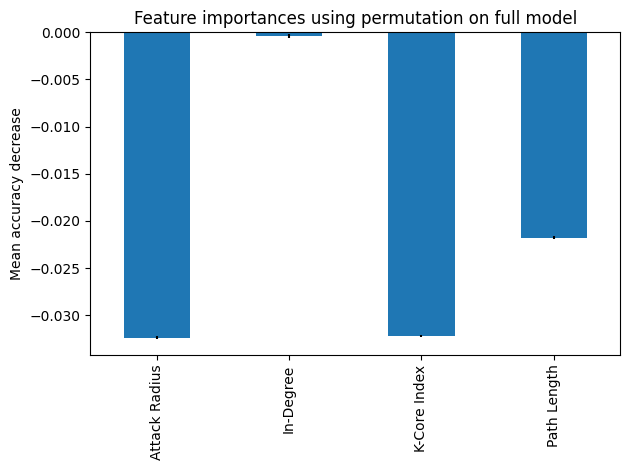

In [ ]:
from sklearn.inspection import permutation_importance

result = permutation_importance(
    rf_classifier, X_test, y_test, n_repeats=10, random_state=42, n_jobs=2
)
forest_importances = pd.Series(result.importances_mean, index=X_resampled.columns)
fig, ax = plt.subplots()
forest_importances.plot.bar(yerr=result.importances_std, ax=ax)
ax.set_title("Feature importances using permutation on full model")
ax.set_ylabel("Mean accuracy decrease")
fig.tight_layout()
plt.show()

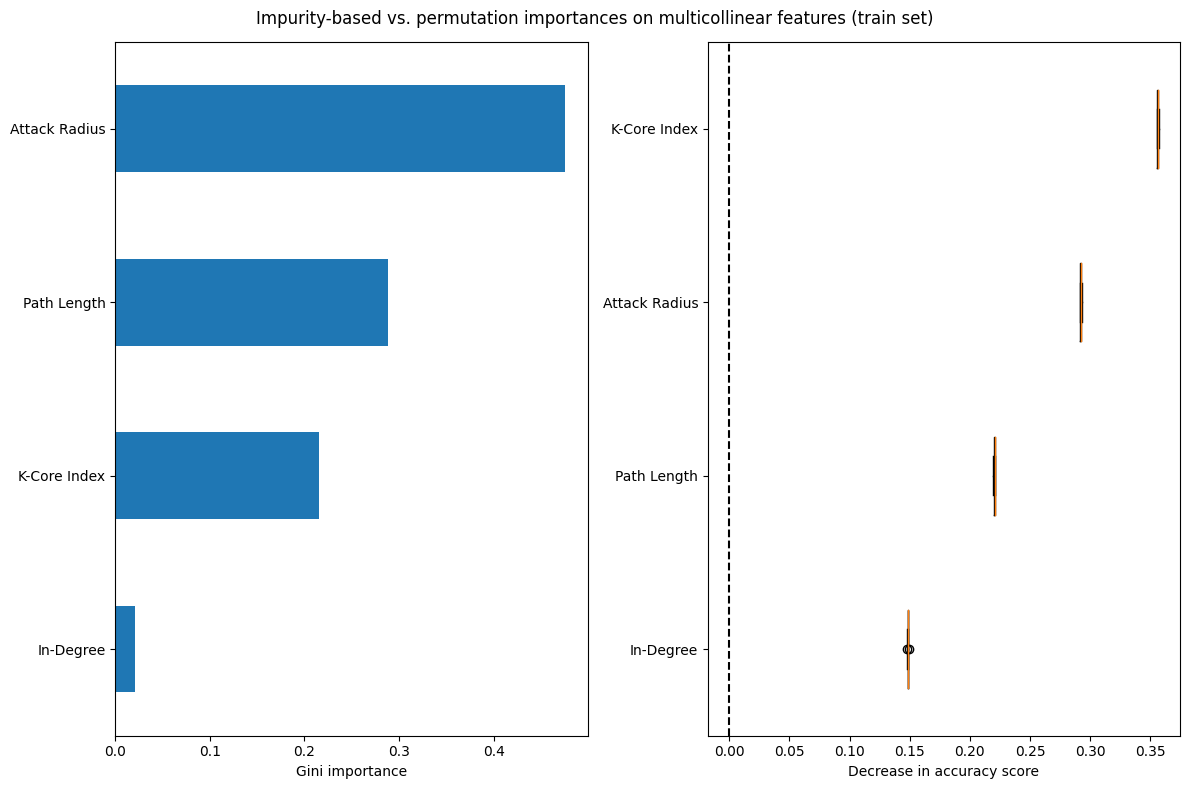

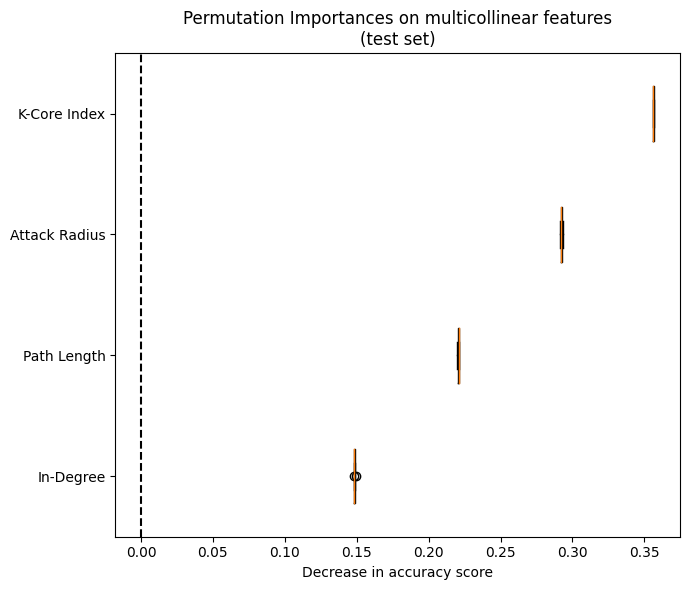

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.inspection import permutation_importance


def plot_permutation_importance(clf, X, y, ax):
    result = permutation_importance(clf, X, y, n_repeats=10, random_state=42, n_jobs=2)
    perm_sorted_idx = result.importances_mean.argsort()

    ax.boxplot(
        result.importances[perm_sorted_idx].T,
        vert=False,
        labels=X.columns[perm_sorted_idx],
    )
    ax.axvline(x=0, color="k", linestyle="--")
    return ax

mdi_importances = pd.Series(rf_classifier.feature_importances_, index=X_resampled.columns)
tree_importance_sorted_idx = np.argsort(rf_classifier.feature_importances_)
tree_indices = np.arange(0, len(rf_classifier.feature_importances_)) + 0.5

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 8))
mdi_importances.sort_values().plot.barh(ax=ax1)
ax1.set_xlabel("Gini importance")
plot_permutation_importance(rf_classifier, X_resampled, y_resampled, ax2)
ax2.set_xlabel("Decrease in accuracy score")
fig.suptitle(
    "Impurity-based vs. permutation importances on multicollinear features (train set)"
)
_ = fig.tight_layout()

fig, ax = plt.subplots(figsize=(7, 6))
plot_permutation_importance(rf_classifier, X_resampled, y_resampled, ax)
ax.set_title("Permutation Importances on multicollinear features\n(test set)")
ax.set_xlabel("Decrease in accuracy score")
_ = ax.figure.tight_layout()

#### Handling Multicollinear Features

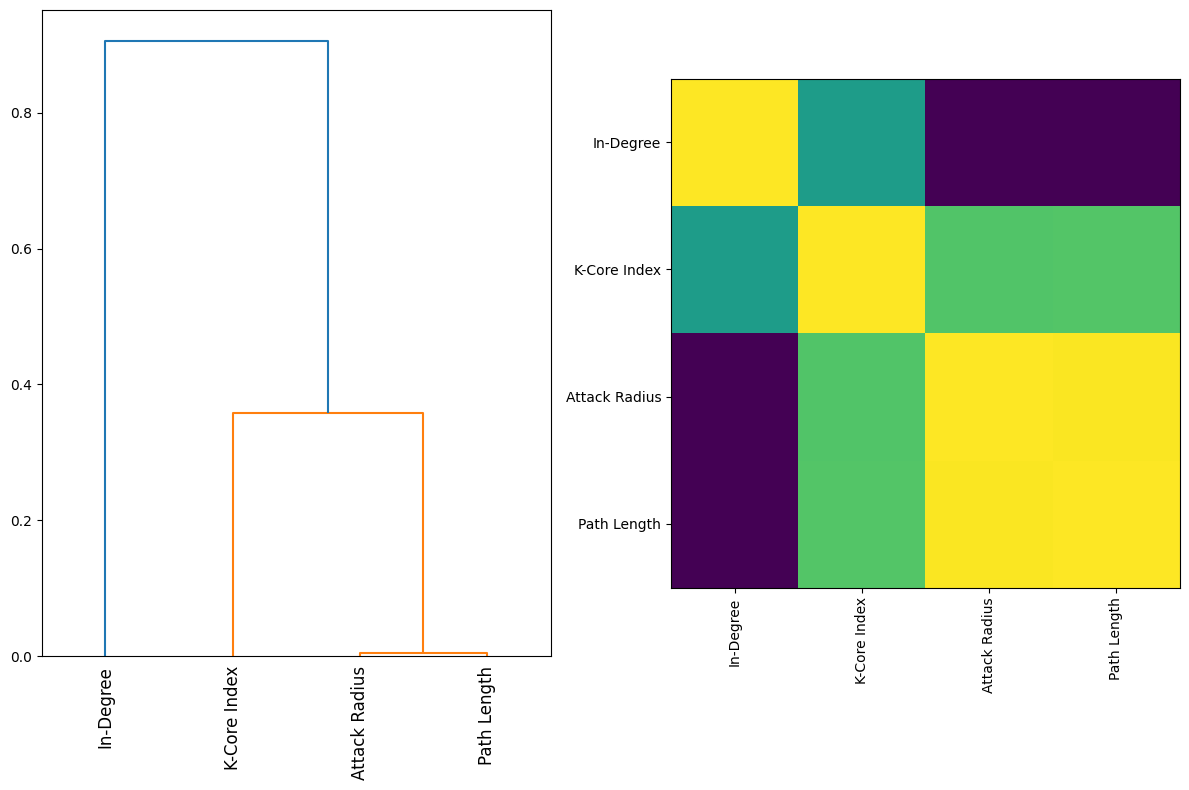

In [ ]:
from scipy.cluster import hierarchy
from scipy.spatial.distance import squareform
from scipy.stats import spearmanr

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 8))
corr = spearmanr(X).correlation

# Ensure the correlation matrix is symmetric
corr = (corr + corr.T) / 2
np.fill_diagonal(corr, 1)

# We convert the correlation matrix to a distance matrix before performing
# hierarchical clustering using Ward's linkage.
distance_matrix = 1 - np.abs(corr)
dist_linkage = hierarchy.ward(squareform(distance_matrix))
dendro = hierarchy.dendrogram(
    dist_linkage, labels=X.columns.to_list(), ax=ax1, leaf_rotation=90
)
dendro_idx = np.arange(0, len(dendro["ivl"]))

ax2.imshow(corr[dendro["leaves"], :][:, dendro["leaves"]])
ax2.set_xticks(dendro_idx)
ax2.set_yticks(dendro_idx)
ax2.set_xticklabels(dendro["ivl"], rotation="vertical")
ax2.set_yticklabels(dendro["ivl"])
_ = fig.tight_layout()

Baseline accuracy on test data with features removed: 0.99


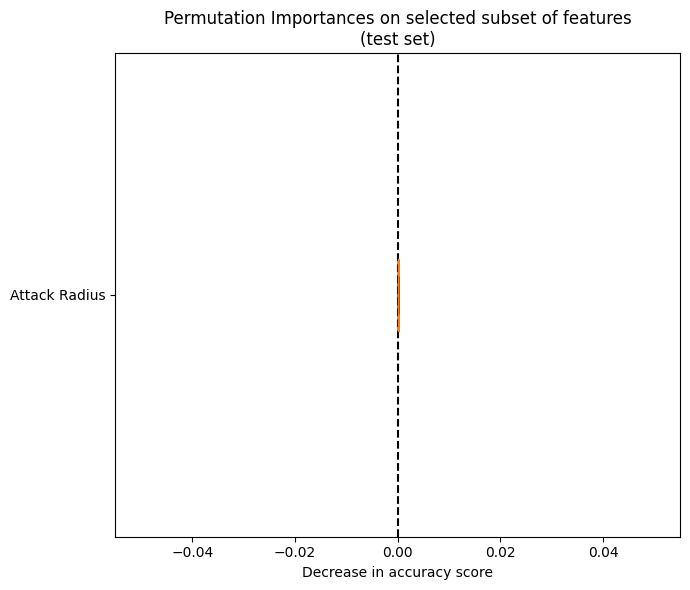

In [ ]:
from collections import defaultdict

cluster_ids = hierarchy.fcluster(dist_linkage, 1, criterion="distance")
cluster_id_to_feature_ids = defaultdict(list)
for idx, cluster_id in enumerate(cluster_ids):
    cluster_id_to_feature_ids[cluster_id].append(idx)
selected_features = [v[0] for v in cluster_id_to_feature_ids.values()]
selected_features_names = X.columns[selected_features]

X_train_sel = X_train[selected_features_names]
X_test_sel = X_test[selected_features_names]

clf_sel = RandomForestClassifier(n_estimators=100, random_state=42)
clf_sel.fit(X_train_sel, y_train)
print(
    "Baseline accuracy on test data with features removed:"
    f" {clf_sel.score(X_test_sel, y_test):.2}"
)

fig, ax = plt.subplots(figsize=(7, 6))
plot_permutation_importance(clf_sel, X_test_sel, y_test, ax)
ax.set_title("Permutation Importances on selected subset of features\n(test set)")
ax.set_xlabel("Decrease in accuracy score")
ax.figure.tight_layout()
plt.show()

In [ ]:
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# Create a Gradient Boosting Classifier
gb_classifier = GradientBoostingClassifier(n_estimators=100, random_state=42)
# Fit the classifier to the data

# Perform cross-validated predictions
y_pred = cross_val_predict(gb_classifier, X_resampled, y_resampled, cv=cv)

# Evaluate the predictions
print("Gradient Boosting Classifier on training data")
print("Accuracy:", accuracy_score(y_resampled, y_pred))
print("Confusion Matrix:\n", confusion_matrix(y_resampled, y_pred))
print("Classification Report:\n", classification_report(y_resampled, y_pred))

gb_classifier.fit(X_resampled, y_resampled)

feature_importance = gb_classifier.feature_importances_
# Assuming 'X' is your feature DataFrame
feature_importance_df = pd.DataFrame({'Feature': X_resampled.columns, 'Importance': feature_importance})
print(feature_importance_df)

Gradient Boosting Classifier on training data
Accuracy: 0.9547900682011935
Confusion Matrix:
 [[188031  18417]
 [   250 206198]]
Classification Report:
               precision    recall  f1-score   support

       False       1.00      0.91      0.95    206448
        True       0.92      1.00      0.96    206448

    accuracy                           0.95    412896
   macro avg       0.96      0.95      0.95    412896
weighted avg       0.96      0.95      0.95    412896

         Feature  Importance
0  Attack Radius    0.960028
1      In-Degree    0.002627
2   K-Core Index    0.025366
3    Path Length    0.011979


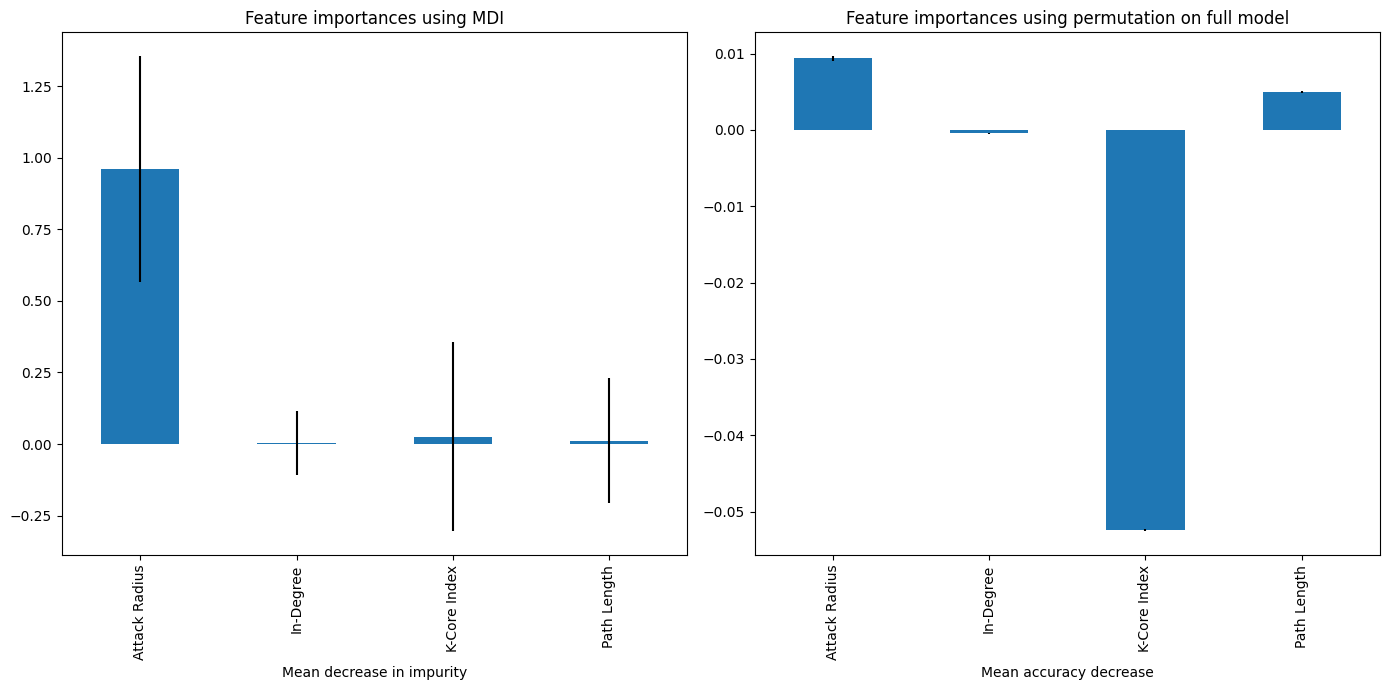

In [ ]:
# Feature importances using MDI
mdi_importances = pd.Series(gb_classifier.feature_importances_, index=X_resampled.columns)
std = np.std([tree[0].feature_importances_ for tree in gb_classifier.estimators_], axis=0)

# Feature importances using permutation importance
perm_importances = permutation_importance(gb_classifier, X_test, y_test, n_repeats=10, random_state=42, n_jobs=2)
perm_importances_mean = pd.Series(perm_importances.importances_mean, index=X_resampled.columns)
perm_importances_std = perm_importances.importances_std

# Plotting MDI vs Permutation Importances
fig, ax = plt.subplots(1, 2, figsize=(14, 7))

# Plot MDI importances
mdi_importances.plot.bar(yerr=std, ax=ax[0])
ax[0].set_title("Feature importances using MDI")
ax[0].set_xlabel("Mean decrease in impurity")

# Plot Permutation importances
perm_importances_mean.plot.bar(yerr=perm_importances_std, ax=ax[1])
ax[1].set_title("Feature importances using permutation on full model")
ax[1].set_xlabel("Mean accuracy decrease")

fig.tight_layout()
plt.show()

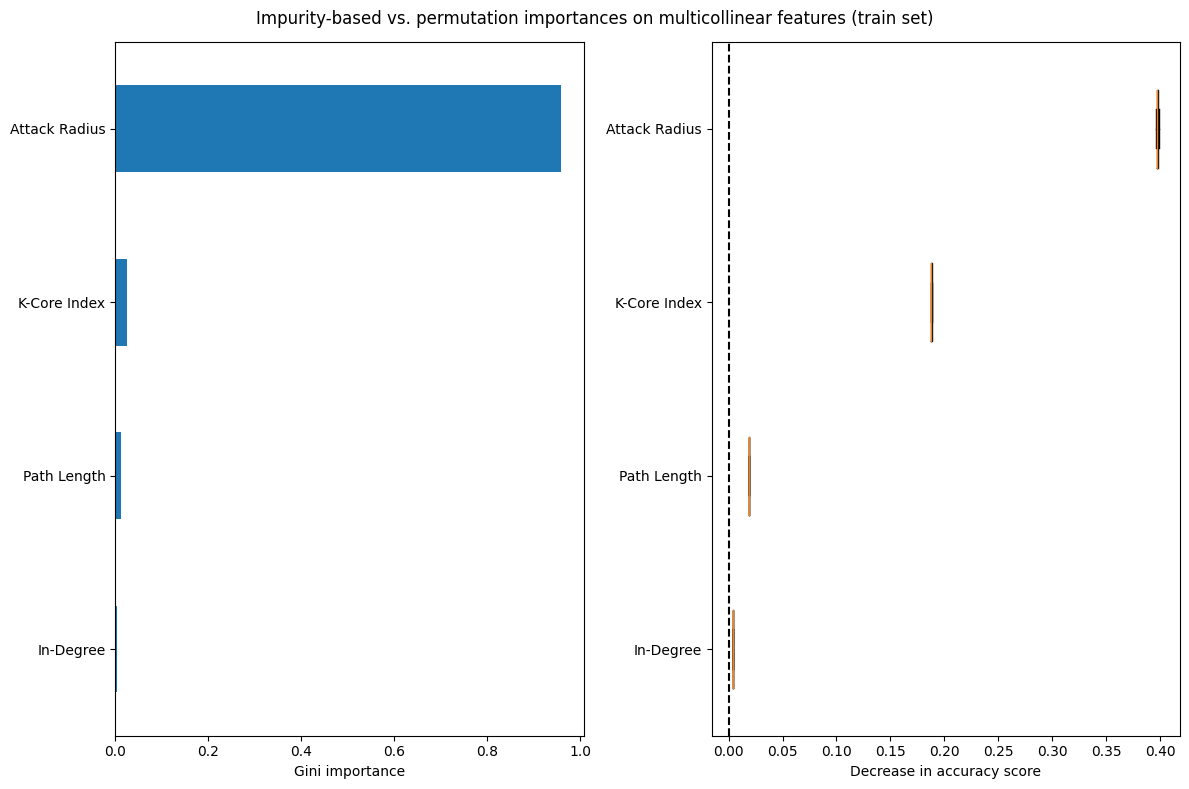

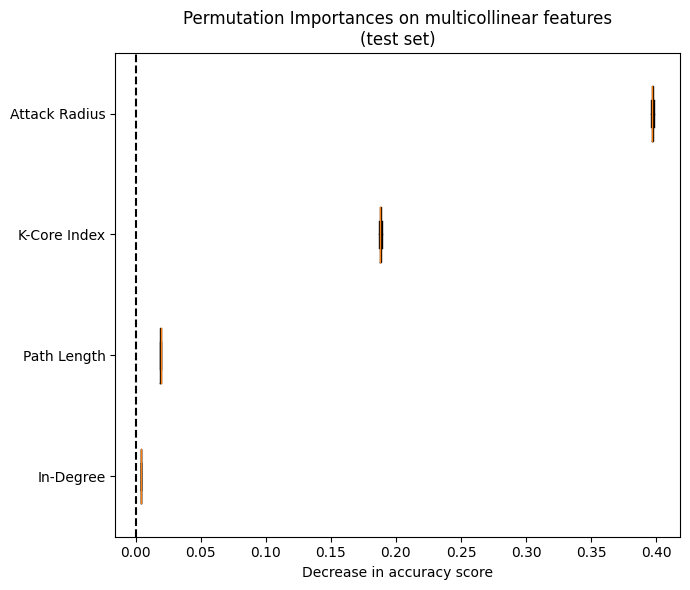

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.inspection import permutation_importance


def plot_permutation_importance(clf, X, y, ax):
    result = permutation_importance(clf, X, y, n_repeats=10, random_state=42, n_jobs=2)
    perm_sorted_idx = result.importances_mean.argsort()

    ax.boxplot(
        result.importances[perm_sorted_idx].T,
        vert=False,
        labels=X.columns[perm_sorted_idx],
    )
    ax.axvline(x=0, color="k", linestyle="--")
    return ax

mdi_importances = pd.Series(gb_classifier.feature_importances_, index=X_resampled.columns)
tree_importance_sorted_idx = np.argsort(gb_classifier.feature_importances_)
tree_indices = np.arange(0, len(gb_classifier.feature_importances_)) + 0.5

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 8))
mdi_importances.sort_values().plot.barh(ax=ax1)
ax1.set_xlabel("Gini importance")
plot_permutation_importance(gb_classifier, X_resampled, y_resampled, ax2)
ax2.set_xlabel("Decrease in accuracy score")
fig.suptitle(
    "Impurity-based vs. permutation importances on multicollinear features (train set)"
)
_ = fig.tight_layout()

fig, ax = plt.subplots(figsize=(7, 6))
plot_permutation_importance(gb_classifier, X_resampled, y_resampled, ax)
ax.set_title("Permutation Importances on multicollinear features\n(test set)")
ax.set_xlabel("Decrease in accuracy score")
_ = ax.figure.tight_layout()

In [ ]:
from xgboost import XGBClassifier

# Set hyperparameters (optional)
params = {
  'max_depth': 6,  # Maximum depth of decision trees
  'n_estimators': 100,  # Number of boosting iterations
  'learning_rate': 0.1,  # Learning rate for each boosting step
  'objective': 'binary:logistic',  # Objective function for classification (logistic regression)
  'random_state': 42  # Set random seed for reproducibility
}

# Create the XGBoost classifier object
xgb_classifier = XGBClassifier(**params)

# Perform cross-validated predictions
y_pred = cross_val_predict(xgb_classifier, X_resampled, y_resampled, cv=cv)

# Evaluate the predictions
print("XGBoost Classifier on training data")
print("Accuracy:", accuracy_score(y_resampled, y_pred))
print("Confusion Matrix:\n", confusion_matrix(y_resampled, y_pred))
print("Classification Report:\n", classification_report(y_resampled, y_pred))

xgb_classifier.fit(X_resampled, y_resampled)

feature_importance = xgb_classifier.feature_importances_
# Assuming 'X' is your feature DataFrame
feature_importance_df = pd.DataFrame({'Feature': X_resampled.columns, 'Importance': feature_importance})
print(feature_importance_df)

XGBoost Classifier on training data
Accuracy: 0.9588637332403317
Confusion Matrix:
 [[189678  16770]
 [   215 206233]]
Classification Report:
               precision    recall  f1-score   support

       False       1.00      0.92      0.96    206448
        True       0.92      1.00      0.96    206448

    accuracy                           0.96    412896
   macro avg       0.96      0.96      0.96    412896
weighted avg       0.96      0.96      0.96    412896

         Feature  Importance
0  Attack Radius    0.979299
1      In-Degree    0.004134
2   K-Core Index    0.008425
3    Path Length    0.008142


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.stats import weightstats
from statsmodels.graphics.tsaplots import plot_acf
from statsmodels.tsa.stattools import adfuller
import statsmodels.api as sm
from scipy.stats import ttest_ind, f_oneway
from statsmodels.formula.api import ols
from scipy.stats import zscore
import warnings
warnings.filterwarnings("ignore")

## RQ1: What are the high-risk (high propagation costs) packages created in the source and build stages when considering OSS supply-chain risk through models of network propagation?


**bold text**## Source Phase Analysis

In [ ]:
df = pd.read_csv('/content/package_data.csv',header=0)
vuln_df = pd.read_csv('/content/past_vulnerable_packages.csv', header=0)

In [ ]:
df.describe()

,CLOC Filecount,CLOC count,SLOC Filecount,SLOC count
count,212172.000000,2.121720e+05,212172.000000,2.121720e+05
mean,381.090700,1.240229e+05,43.879536,8.266820e+03
std,1178.411755,4.007120e+05,216.361843,4.875017e+04
min,0.000000,0.000000e+00,0.000000,0.000000e+00
25%,13.000000,1.835000e+03,0.000000,0.000000e+00
50%,83.000000,1.712800e+04,0.000000,0.000000e+00
75%,362.000000,9.556700e+04,18.000000,1.243000e+03
max,84306.000000,1.536671e+07,23947.000000,5.834642e+06


In [ ]:
print(df.shape)
print(vuln_df.shape)

(212172, 7)
(3539, 1)


In [ ]:
print(df.head())
print(vuln_df.head())

       Repository    Tag  CLOC Filecount  CLOC count  SLOC Filecount  \
0    sendmail-bin  8.8.4             181       59235               0   
1   sendmail-base  8.8.4             181       59235               0   
2   lyskom-server  1.9.0             223       70585               0   
3     sendmail-cf  8.8.4             181       59235               0   
4  libmilter1.0.1  8.8.4             181       59235               0   

   SLOC count File Size  
0           0       41M  
1           0       41M  
2           0       13M  
3           0       41M  
4       35983       41M  
      Packages
0  389-ds-base
1         7zip
2        9base
3         a2ps
4      abcm2ps


### Data Cleaning

In [ ]:
# Initialize combined_df with the index of attack_df and fill with 0s
combined_df = df.copy()

# Merge each dataframe into combined_df
combined_df = combined_df.merge(vuln_df, left_on='Repository', right_on='Packages', how='left').fillna(0)

# Add Vulnerability column based on the condition
combined_df['Vulnerability'] = combined_df['Repository'] == combined_df['Packages']

print(combined_df.shape)
print(combined_df.head())


(212172, 9)
       Repository    Tag  CLOC Filecount  CLOC count  SLOC Filecount  \
0    sendmail-bin  8.8.4             181       59235               0   
1   sendmail-base  8.8.4             181       59235               0   
2   lyskom-server  1.9.0             223       70585               0   
3     sendmail-cf  8.8.4             181       59235               0   
4  libmilter1.0.1  8.8.4             181       59235               0   

   SLOC count File Size       Packages  Vulnerability  
0           0       41M              0          False  
1           0       41M              0          False  
2           0       13M  lyskom-server           True  
3           0       41M              0          False  
4       35983       41M              0          False  


In [ ]:
combined_df.drop(columns=['Packages'], inplace=True)

In [ ]:
# Count of True values in Vulnerability column
true_count = combined_df['Vulnerability'].sum()
print(f"Total True packages: {true_count}")

# Group by Repository and count True values
# Calculate sum of Vulnerability column grouped by Repository
grouped_count = combined_df.groupby('Repository')['Vulnerability'].sum().reset_index()

# Filter to get only rows where True_Count is greater than 0
filtered_count = grouped_count[grouped_count['Vulnerability'] > 0]

# Rename columns for clarity
filtered_count.columns = ['Repository', 'True_Count']

print("Repositories with Vulnerabilities:")
print(len(filtered_count))


Total True packages: 8105
Repositories with Vulnerabilities:
1705


In [ ]:
# Define the function to convert file size strings
def convert_file_size(size_str):
    size_str = size_str.strip().lower()  # Ensure lowercase and remove leading/trailing spaces

    # Handle the case where size_str might contain decimals or non-integer values
    try:
        if '.' in size_str:
            # If it's a decimal number, convert to float and then to integer (or handle as needed)
            return int(float(size_str) * 10000)  # Assuming it's in 'g' format

        if size_str.endswith('k'):
            return int(size_str[:-1])  # Remove 'k' and convert to integer

        elif size_str.endswith('m'):
            return int(size_str[:-1]) * 100  # Remove 'm', multiply by 100, and convert to integer

        elif size_str.endswith('g'):
            return int(size_str[:-1]) * 10000  # Remove 'g', multiply by 10000, and convert to integer

    except ValueError:
        return 0  # Handle cases where conversion fails gracefully

    return 0  # Default case: return 0 if size_str doesn't match any expected format

# Apply the conversion function to the 'File Size' column in combined_df
combined_df['File Size'] = combined_df['File Size'].apply(convert_file_size)

# Print the modified DataFrame to verify changes
print(combined_df.head())


       Repository    Tag  CLOC Filecount  CLOC count  SLOC Filecount  \
0    sendmail-bin  8.8.4             181       59235               0   
1   sendmail-base  8.8.4             181       59235               0   
2   lyskom-server  1.9.0             223       70585               0   
3     sendmail-cf  8.8.4             181       59235               0   
4  libmilter1.0.1  8.8.4             181       59235               0   

   SLOC count  File Size  Vulnerability  
0           0       4100          False  
1           0       4100          False  
2           0       1300           True  
3           0       4100          False  
4       35983       4100          False  


In [ ]:
combined_df.describe()

,CLOC Filecount,CLOC count,SLOC Filecount,SLOC count,File Size
count,212172.000000,2.121720e+05,212172.000000,2.121720e+05,212172.000000
mean,381.090700,1.240229e+05,43.879536,8.266820e+03,3602.588013
std,1178.411755,4.007120e+05,216.361843,4.875017e+04,6821.487722
min,0.000000,0.000000e+00,0.000000,0.000000e+00,0.000000
25%,13.000000,1.835000e+03,0.000000,0.000000e+00,0.000000
50%,83.000000,1.712800e+04,0.000000,0.000000e+00,632.000000
75%,362.000000,9.556700e+04,18.000000,1.243000e+03,3400.000000
max,84306.000000,1.536671e+07,23947.000000,5.834642e+06,120000.000000


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier, GradientBoostingClassifier
from xgboost import XGBClassifier
from sklearn.metrics import roc_curve, auc, accuracy_score, confusion_matrix, classification_report
from sklearn.model_selection import train_test_split, cross_val_predict, StratifiedKFold
from imblearn.over_sampling import SMOTE, BorderlineSMOTE
from imblearn.ensemble import BalancedRandomForestClassifier
from imblearn.under_sampling import RandomUnderSampler
from imblearn.combine import SMOTEENN

X = combined_df[['CLOC Filecount', 'CLOC count','SLOC Filecount', 'SLOC count', 'File Size']]
y = combined_df['Vulnerability']

# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Apply SMOTE to the training data
smote = BorderlineSMOTE(random_state=42)
X_train_smote, y_train_smote = smote.fit_resample(X, y)

# Apply SMOTEENN to the training data (combination of SMOTE and Edited Nearest Neighbors)
smoteenn = SMOTEENN(random_state=42)
X_train_smoteenn, y_train_smoteenn = smoteenn.fit_resample(X, y)



# Define the models
models = {
    'Logistic Regression': LogisticRegression(max_iter=1000, class_weight='balanced'),
    'Decision Tree': DecisionTreeClassifier(class_weight='balanced'),
    'Random Forest': RandomForestClassifier(random_state=42, class_weight='balanced'),
    'Balanced Random Forest': BalancedRandomForestClassifier(n_estimators=150, random_state=2),
    'AdaBoost': AdaBoostClassifier(random_state=42),
    'Gradient Boosting': GradientBoostingClassifier(random_state=42),
    'XGBoost': XGBClassifier(random_state=42)
}

# Combine models with different sampling techniques
model_sampling_combinations = [
    ('Logistic Regression (Borderline)', LogisticRegression(max_iter=1000, class_weight='balanced'), X_train_smote, y_train_smote),
    ('Decision Tree (Borderline)', DecisionTreeClassifier(class_weight='balanced'), X_train_smote, y_train_smote),
    ('Random Forest (Borderline)', RandomForestClassifier(random_state=42, class_weight='balanced'), X_train_smote, y_train_smote),
    ('Balanced Random Forest (Borderline)', BalancedRandomForestClassifier(n_estimators=150, random_state=2), X_train_smote, y_train_smote),
    ('AdaBoost (Borderline)', AdaBoostClassifier(random_state=42), X_train_smote, y_train_smote),
    ('Gradient Boosting (Borderline)', GradientBoostingClassifier(random_state=42), X_train_smote, y_train_smote),
    ('XGBoost (Borderline)', XGBClassifier(random_state=42), X_train_smote, y_train_smote),
    ('Logistic Regression (SMOTEENN)', LogisticRegression(max_iter=1000, class_weight='balanced'), X_train_smoteenn, y_train_smoteenn),
    ('Decision Tree (SMOTEENN)', DecisionTreeClassifier(class_weight='balanced'), X_train_smoteenn, y_train_smoteenn),
    ('Random Forest (SMOTEENN)', RandomForestClassifier(random_state=42, class_weight='balanced'), X_train_smoteenn, y_train_smoteenn),
    ('Balanced Random Forest (SMOTEENN)', BalancedRandomForestClassifier(n_estimators=150, random_state=2), X_train_smoteenn, y_train_smoteenn),
    ('AdaBoost (SMOTEENN)', AdaBoostClassifier(random_state=42), X_train_smoteenn, y_train_smoteenn),
    ('Gradient Boosting (SMOTEENN)', GradientBoostingClassifier(random_state=42), X_train_smoteenn, y_train_smoteenn),
    ('XGBoost (SMOTEENN)', XGBClassifier(random_state=42), X_train_smoteenn, y_train_smoteenn)
]

# Function to plot ROC curves for a set of models
def plot_roc_curves(models, X_test, y_test, title):
    plt.figure(figsize=(12, 8))
    for name, model in models.items():
        y_pred_prob = model.predict_proba(X_test)[:, 1]
        fpr, tpr, _ = roc_curve(y_test, y_pred_prob)
        roc_auc = auc(fpr, tpr)
        plt.plot(fpr, tpr, label=f'{name} (AUC = {roc_auc:.2f})')
    plt.plot([0, 1], [0, 1], 'k--')
    plt.xlim([0.0, 1.0])
    plt.ylim([0.0, 1.05])
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title(title)
    plt.legend(loc='lower right')
    plt.show()


Logistic Regression (Borderline) Model:
Accuracy: 0.4421114645929068
Confusion Matrix:
 [[17545 23276]
 [  398  1216]]
Classification Report:
               precision    recall  f1-score   support

       False       0.98      0.43      0.60     40821
        True       0.05      0.75      0.09      1614

    accuracy                           0.44     42435
   macro avg       0.51      0.59      0.35     42435
weighted avg       0.94      0.44      0.58     42435


Decision Tree (Borderline) Model:
Accuracy: 0.9896547661128785
Confusion Matrix:
 [[40716   105]
 [  334  1280]]
Classification Report:
               precision    recall  f1-score   support

       False       0.99      1.00      0.99     40821
        True       0.92      0.79      0.85      1614

    accuracy                           0.99     42435
   macro avg       0.96      0.90      0.92     42435
weighted avg       0.99      0.99      0.99     42435


Random Forest (Borderline) Model:
Accuracy: 0.9894191115824201


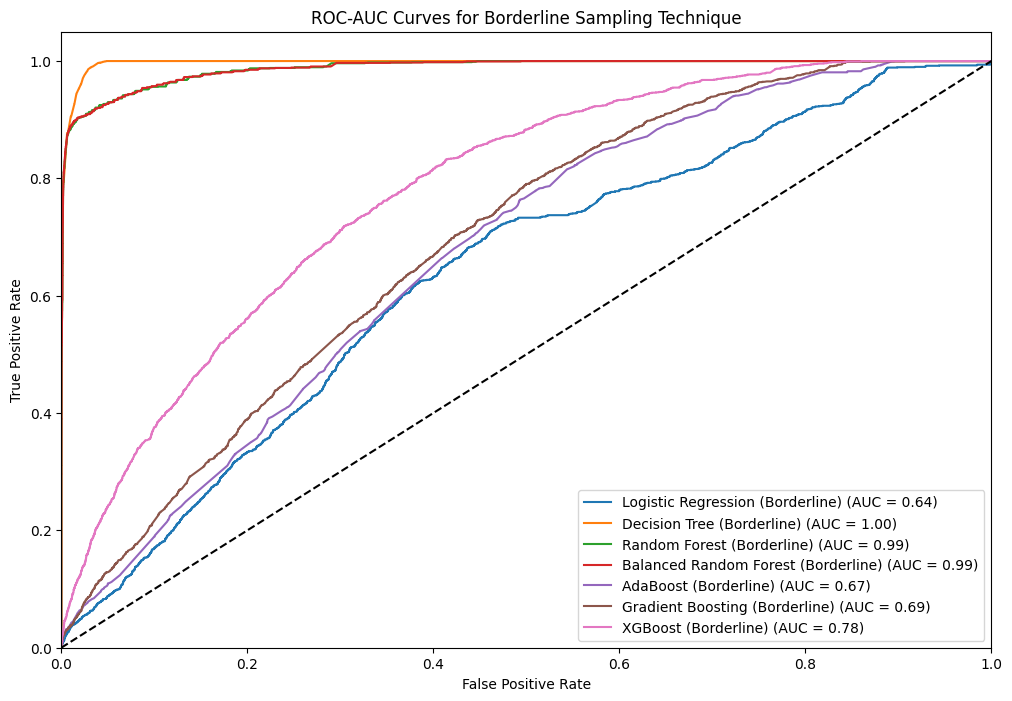


Logistic Regression (SMOTEENN) Model:
Accuracy: 0.4527394839165783
Confusion Matrix:
 [[18028 22793]
 [  430  1184]]
Classification Report:
               precision    recall  f1-score   support

       False       0.98      0.44      0.61     40821
        True       0.05      0.73      0.09      1614

    accuracy                           0.45     42435
   macro avg       0.51      0.59      0.35     42435
weighted avg       0.94      0.45      0.59     42435


Decision Tree (SMOTEENN) Model:
Accuracy: 0.9107104984093319
Confusion Matrix:
 [[37240  3581]
 [  208  1406]]
Classification Report:
               precision    recall  f1-score   support

       False       0.99      0.91      0.95     40821
        True       0.28      0.87      0.43      1614

    accuracy                           0.91     42435
   macro avg       0.64      0.89      0.69     42435
weighted avg       0.97      0.91      0.93     42435


Random Forest (SMOTEENN) Model:
Accuracy: 0.9102863202545068
Confus

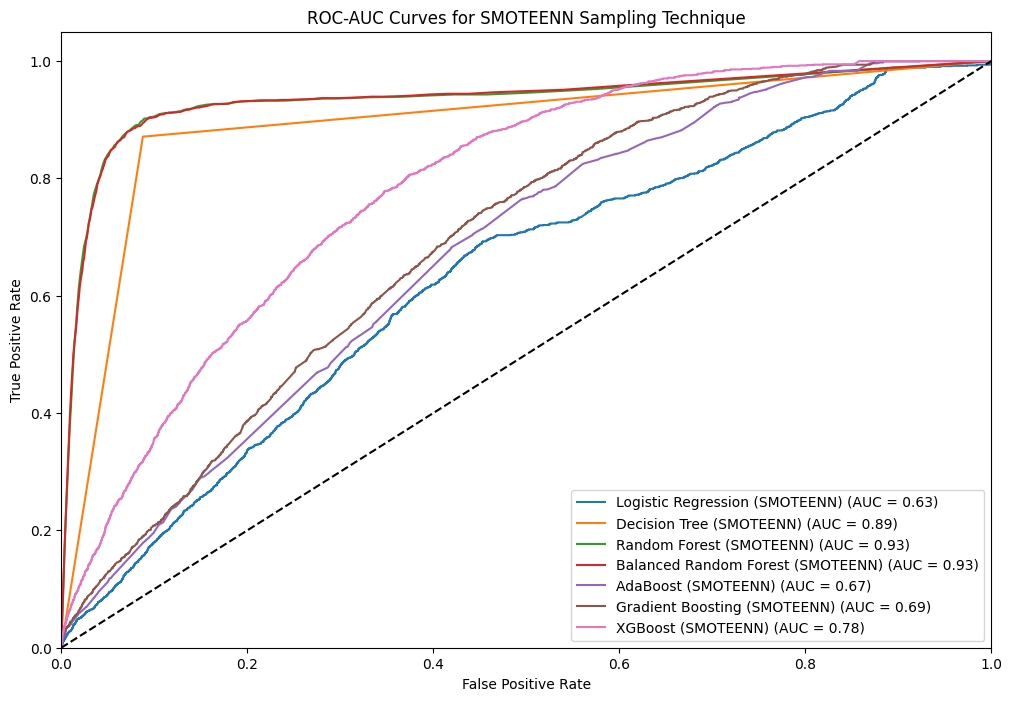

In [ ]:
# Train the models and evaluate them
for sampling_method in ['Borderline', 'SMOTEENN']:
    models_to_plot = {}
    for name, model, X_train_resampled, y_train_resampled in model_sampling_combinations:
        if sampling_method in name:
            model.fit(X_train_resampled, y_train_resampled)
            y_pred = model.predict(X_test)
            print(f"\n{name} Model:")
            print("Accuracy:", accuracy_score(y_test, y_pred))
            print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))
            print("Classification Report:\n", classification_report(y_test, y_pred))
            models_to_plot[name] = model
    plot_roc_curves(models_to_plot, X_test, y_test, f'ROC-AUC Curves for {sampling_method} Sampling Technique')

Logistic Regression (Borderline) Cross-Validated AUC: 0.67, Accuracy: 0.62
Confusion Matrix:
 [[ 91421 112646]
 [ 43618 160449]]
Classification Report:
               precision    recall  f1-score   support

       False       0.68      0.45      0.54    204067
        True       0.59      0.79      0.67    204067

    accuracy                           0.62    408134
   macro avg       0.63      0.62      0.61    408134
weighted avg       0.63      0.62      0.61    408134

Decision Tree (Borderline) Cross-Validated AUC: 0.92, Accuracy: 0.92
Confusion Matrix:
 [[187022  17045]
 [ 14965 189102]]
Classification Report:
               precision    recall  f1-score   support

       False       0.93      0.92      0.92    204067
        True       0.92      0.93      0.92    204067

    accuracy                           0.92    408134
   macro avg       0.92      0.92      0.92    408134
weighted avg       0.92      0.92      0.92    408134

Random Forest (Borderline) Cross-Validated AUC

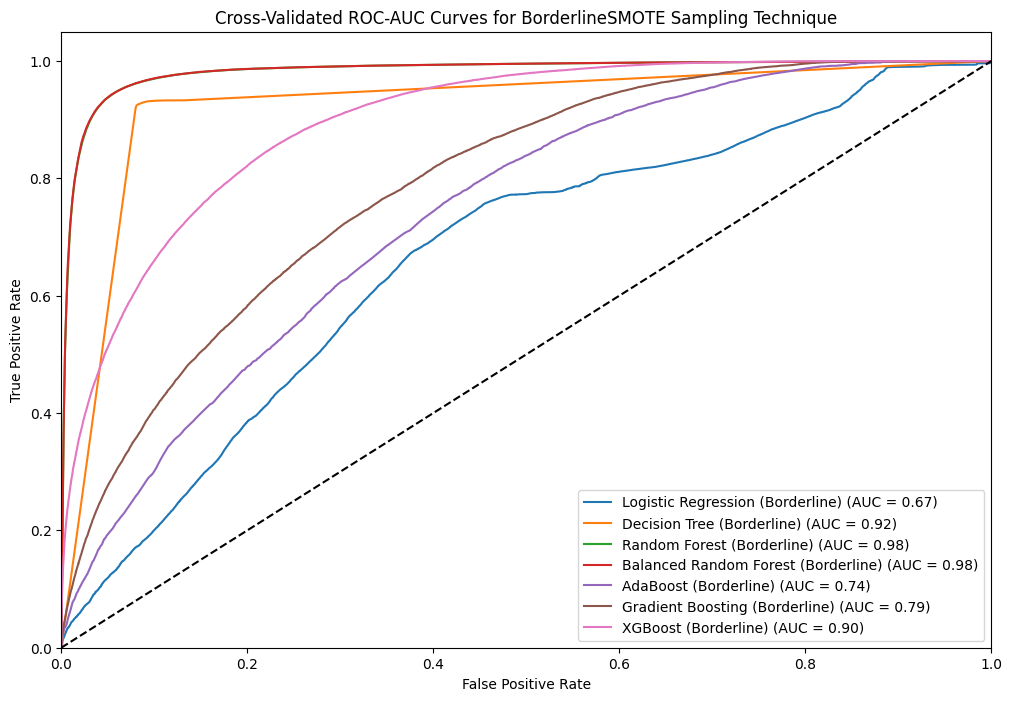

Logistic Regression (SMOTEENN) Cross-Validated AUC: 0.66, Accuracy: 0.62
Confusion Matrix:
 [[ 76883  83399]
 [ 40980 126685]]
Classification Report:
               precision    recall  f1-score   support

       False       0.65      0.48      0.55    160282
        True       0.60      0.76      0.67    167665

    accuracy                           0.62    327947
   macro avg       0.63      0.62      0.61    327947
weighted avg       0.63      0.62      0.61    327947

Decision Tree (SMOTEENN) Cross-Validated AUC: 0.94, Accuracy: 0.94
Confusion Matrix:
 [[149536  10746]
 [  8901 158764]]
Classification Report:
               precision    recall  f1-score   support

       False       0.94      0.93      0.94    160282
        True       0.94      0.95      0.94    167665

    accuracy                           0.94    327947
   macro avg       0.94      0.94      0.94    327947
weighted avg       0.94      0.94      0.94    327947

Random Forest (SMOTEENN) Cross-Validated AUC: 0.99

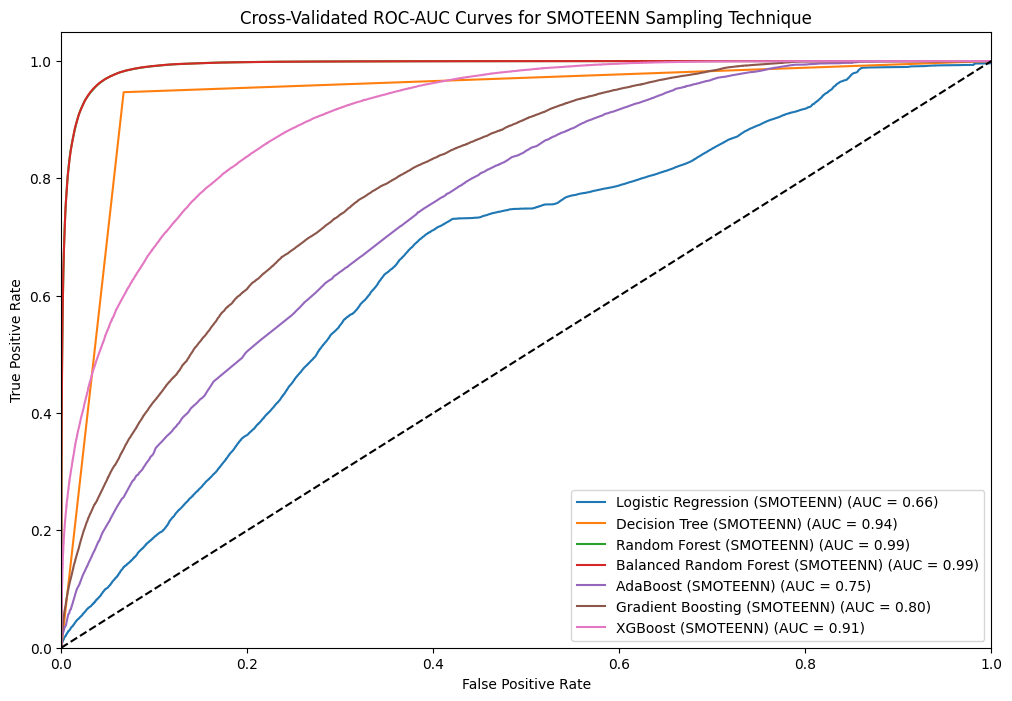

In [ ]:

# Function to plot ROC curves for a set of models
def plot_roc_curves(models, X, y, title):
    plt.figure(figsize=(12, 8))
    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

    for name, model, X_resampled, y_resampled in models:
        y_pred_cv = cross_val_predict(model, X_resampled, y_resampled, cv=cv, method='predict_proba')[:, 1]
        fpr, tpr, _ = roc_curve(y_resampled, y_pred_cv)
        roc_auc = auc(fpr, tpr)
        plt.plot(fpr, tpr, label=f'{name} (AUC = {roc_auc:.2f})')

        accuracy = accuracy_score(y_resampled, (y_pred_cv > 0.5).astype(int))
        conf_matrix = confusion_matrix(y_resampled, (y_pred_cv > 0.5).astype(int))
        class_report = classification_report(y_resampled, (y_pred_cv > 0.5).astype(int))
        print(f'{name} Cross-Validated AUC: {roc_auc:.2f}, Accuracy: {accuracy:.2f}')
        print("Confusion Matrix:\n", conf_matrix)
        print("Classification Report:\n", class_report)

    plt.plot([0, 1], [0, 1], 'k--')
    plt.xlim([0.0, 1.0])
    plt.ylim([0.0, 1.05])
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title(title)
    plt.legend(loc='lower right')
    plt.show()

# Separate model lists for each sampling technique
smote_models = [model for model in model_sampling_combinations if 'Borderline' in model[0]]
smoteenn_models = [model for model in model_sampling_combinations if 'SMOTEENN' in model[0]]

# Plot ROC curves for each sampling technique
plot_roc_curves(smote_models, X_train_resampled, y_train_resampled, 'Cross-Validated ROC-AUC Curves for BorderlineSMOTE Sampling Technique')
plot_roc_curves(smoteenn_models, X_train_resampled, y_train_resampled, 'Cross-Validated ROC-AUC Curves for SMOTEENN Sampling Technique')

# # Evaluate models with cross-validation
# cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
# for name, model, X_train_resampled, y_train_resampled in model_sampling_combinations:
#     y_pred_cv = cross_val_predict(model, X_train_resampled, y_train_resampled, cv=cv, method='predict_proba')[:, 1]
#     fpr, tpr, _ = roc_curve(y_train_resampled, y_pred_cv)
#     roc_auc = auc(fpr, tpr)
#     accuracy = accuracy_score(y_train_resampled, (y_pred_cv > 0.5).astype(int))
#     conf_matrix = confusion_matrix(y_train_resampled, (y_pred_cv > 0.5).astype(int))
#     class_report = classification_report(y_train_resampled, (y_pred_cv > 0.5).astype(int))
#     print(f'{name} Cross-Validated AUC: {roc_auc:.2f}, Accuracy: {accuracy:.2f}')
#     print("Confusion Matrix:\n", conf_matrix)
#     print("Classification Report:\n", class_report)


In [ ]:
import pandas as pd
import numpy as np
from sklearn import linear_model
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from mlxtend.feature_selection import SequentialFeatureSelector
from imblearn.over_sampling import SMOTE
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
import pandas as pd
import numpy as np
import statsmodels.api as sm

In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score,confusion_matrix, classification_report
from sklearn.feature_selection import SequentialFeatureSelector
import statsmodels.api as sm

# Load your data into combined_df
# Example:
# combined_df = pd.read_csv('your_data.csv')

# Define the feature matrix and target variable
# X = combined_df[['Attack Radius', 'In-Degree', 'Betweenness Centrality', 'Core Value', 'Longest Path Length']]
X = combined_df[['CLOC Filecount', 'CLOC count','SLOC Filecount', 'SLOC count', 'File Size']]
y = combined_df['Vulnerability']

# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

# Perform stepwise feature selection
sfs = SequentialFeatureSelector(LogisticRegression(max_iter=1000),
                                n_features_to_select='auto',
                                direction='forward',
                                scoring='accuracy',
                                cv=5)
sfs.fit(X_train, y_train)

# Get the selected features
selected_features = sfs.get_support(indices=True)
X_train_selected = X_train.iloc[:, selected_features]
X_test_selected = X_test.iloc[:, selected_features]

# Fit a logistic regression model using the selected features
logreg = LogisticRegression(max_iter=1000)
logreg.fit(X_train_selected, y_train)

# Make predictions using the test set
y_pred = logreg.predict(X_test_selected)

# Evaluate the model performance
accuracy = accuracy_score(y_test, y_pred)
print(f'Accuracy: {accuracy}')
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))
print("Classification Report:\n", classification_report(y_test, y_pred))

Accuracy: 0.9618865078866335
Confusion Matrix:
 [[61226     0]
 [ 2426     0]]
Classification Report:
               precision    recall  f1-score   support

       False       0.96      1.00      0.98     61226
        True       0.00      0.00      0.00      2426

    accuracy                           0.96     63652
   macro avg       0.48      0.50      0.49     63652
weighted avg       0.93      0.96      0.94     63652



In [ ]:
from imblearn.over_sampling import SMOTE
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
import pandas as pd

# Assuming 'data' is your DataFrame containing the risk metrics data

# Split the data into independent variables (X) and dependent variable (y)
X = combined_df[['CLOC Filecount', 'CLOC count','SLOC Filecount', 'SLOC count', 'File Size']]
y = combined_df['Vulnerability']

# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Apply SMOTE to the training data
smote = SMOTE(random_state=42)
X_train_smote, y_train_smote = smote.fit_resample(X_train, y_train)

# Logistic Regression Model
logistic_model = LogisticRegression(max_iter=1000,class_weight='balanced')
logistic_model.fit(X_train_smote, y_train_smote)
y_pred_logistic = logistic_model.predict(X_test)

# Decision Tree Model
decision_tree_model = DecisionTreeClassifier(class_weight='balanced')
decision_tree_model.fit(X_train_smote, y_train_smote)
y_pred_dt = decision_tree_model.predict(X_test)

# Evaluate the models
print("Logistic Regression Model:")
print("Accuracy:", accuracy_score(y_test, y_pred_logistic))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred_logistic))
print("Classification Report:\n", classification_report(y_test, y_pred_logistic))

Logistic Regression Model:
Accuracy: 0.4656062212796041
Confusion Matrix:
 [[18599 22222]
 [  455  1159]]
Classification Report:
               precision    recall  f1-score   support

       False       0.98      0.46      0.62     40821
        True       0.05      0.72      0.09      1614

    accuracy                           0.47     42435
   macro avg       0.51      0.59      0.36     42435
weighted avg       0.94      0.47      0.60     42435



In [ ]:
print("\nDecision Tree Model:")
print("Accuracy:", accuracy_score(y_test, y_pred_dt))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred_dt))
print("Classification Report:\n", classification_report(y_test, y_pred_dt))


Decision Tree Model:
Accuracy: 0.8711205372923294
Confusion Matrix:
 [[36537  4284]
 [ 1185   429]]
Classification Report:
               precision    recall  f1-score   support

       False       0.97      0.90      0.93     40821
        True       0.09      0.27      0.14      1614

    accuracy                           0.87     42435
   macro avg       0.53      0.58      0.53     42435
weighted avg       0.94      0.87      0.90     42435



In [ ]:
from imblearn.over_sampling import BorderlineSMOTE
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
from sklearn.model_selection import train_test_split

# Apply Borderline-SMOTE to the training data
smote = BorderlineSMOTE(random_state=42)
X_train_smote, y_train_smote = smote.fit_resample(X_train, y_train)

# Random Forest Model
rf_model = RandomForestClassifier(random_state=42)
rf_model.fit(X_train_smote, y_train_smote)
y_pred_rf = rf_model.predict(X_test)

# Evaluate the model
print("Random Forest Model:")
print("Accuracy:", accuracy_score(y_test, y_pred_rf))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred_rf))
print("Classification Report:\n", classification_report(y_test, y_pred_rf))



Random Forest Model:
Accuracy: 0.9123129492164487
Confusion Matrix:
 [[38339  2482]
 [ 1239   375]]
Classification Report:
               precision    recall  f1-score   support

       False       0.97      0.94      0.95     40821
        True       0.13      0.23      0.17      1614

    accuracy                           0.91     42435
   macro avg       0.55      0.59      0.56     42435
weighted avg       0.94      0.91      0.92     42435



In [ ]:
from sklearn.model_selection import cross_val_score, cross_val_predict, StratifiedKFold
from sklearn.ensemble import RandomForestClassifier
from imblearn.over_sampling import BorderlineSMOTE
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, make_scorer
import pandas as pd

# Assuming 'X_train' and 'y_train' are your training features and target variable

# Apply Borderline-SMOTE to the data
smote = BorderlineSMOTE(random_state=42)
X_resampled, y_resampled = smote.fit_resample(X_train, y_train)

# Combine the resampled features and target variable into a single DataFrame
resampled_df = pd.DataFrame(X_resampled, columns=X_train.columns)
resampled_df['Target'] = y_resampled

# Create a Random Forest Classifier
rf_classifier = RandomForestClassifier(random_state=42)

# Create a stratified k-fold cross-validator
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Convert the accuracy_score metric to a scorer
accuracy_scorer = make_scorer(accuracy_score)

# Perform cross-validation
# cv_results = cross_val_score(rf_classifier, X_resampled, y_resampled, cv=cv, scoring=accuracy_scorer)
# print("Cross-validation scores:", cv_results)

# Perform cross-validated predictions
y_pred = cross_val_predict(rf_classifier, X_resampled, y_resampled, cv=cv)

# Evaluate the predictions
print("Random Forest Classifier on resampled data")
print("Accuracy:", accuracy_score(y_resampled, y_pred))
print("Confusion Matrix:\n", confusion_matrix(y_resampled, y_pred))
print("Classification Report:\n", classification_report(y_resampled, y_pred))

# Fit the classifier to the entire resampled dataset
rf_classifier.fit(X_resampled, y_resampled)

Random Forest Classifier on resampled data
Accuracy: 0.9436831530328461
Confusion Matrix:
 [[151968  11278]
 [  7109 156137]]
Classification Report:
               precision    recall  f1-score   support

       False       0.96      0.93      0.94    163246
        True       0.93      0.96      0.94    163246

    accuracy                           0.94    326492
   macro avg       0.94      0.94      0.94    326492
weighted avg       0.94      0.94      0.94    326492



RandomForestClassifier(random_state=42)

In [ ]:
from sklearn.model_selection import cross_val_score
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, KFold
from imblearn.over_sampling import BorderlineSMOTE, ADASYN
from sklearn.metrics import make_scorer, accuracy_score
from sklearn.model_selection import cross_val_predict

# Assuming 'X' and 'y' are your features and target variable

# Apply Borderline-SMOTE or ADASYN to the data
smote = BorderlineSMOTE(random_state=42)
# smote = ADASYN(random_state=42)
X_resampled, y_resampled = smote.fit_resample(X_train, y_train)

# Create a Random Forest Classifier
rf_classifier = RandomForestClassifier(random_state=42)

# Create a stratified k-fold cross-validator
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# # Perform cross-validation
cv_results = cross_val_score(rf_classifier, X_resampled, y_resampled, cv=cv, scoring=make_scorer(accuracy_score))
print(cv_results)
# Perform cross-validated predictions
y_pred = cross_val_predict(rf_classifier, X_resampled, y_resampled, cv=cv)

# Evaluate the predictions
print("Random Forest Classifier on training data")
print("Accuracy:", accuracy_score(y_resampled, y_pred))
print("Confusion Matrix:\n", confusion_matrix(y_resampled, y_pred))
print("Classification Report:\n", classification_report(y_resampled, y_pred))

# Fit the classifier to the data
rf_classifier.fit(X_resampled, y_resampled)

feature_importance = rf_classifier.feature_importances_
# Assuming 'X' is your feature DataFrame
feature_importance_df = pd.DataFrame({'Feature': X_resampled.columns, 'Importance': feature_importance})
print(feature_importance_df)


[0.94560407 0.94254123 0.94330607 0.94309167 0.94387271]
Random Forest Classifier on training data
Accuracy: 0.9436831530328461
Confusion Matrix:
 [[151968  11278]
 [  7109 156137]]
Classification Report:
               precision    recall  f1-score   support

       False       0.96      0.93      0.94    163246
        True       0.93      0.96      0.94    163246

    accuracy                           0.94    326492
   macro avg       0.94      0.94      0.94    326492
weighted avg       0.94      0.94      0.94    326492

          Feature  Importance
0  CLOC Filecount    0.210018
1      CLOC count    0.388167
2  SLOC Filecount    0.083754
3      SLOC count    0.114387
4       File Size    0.203675


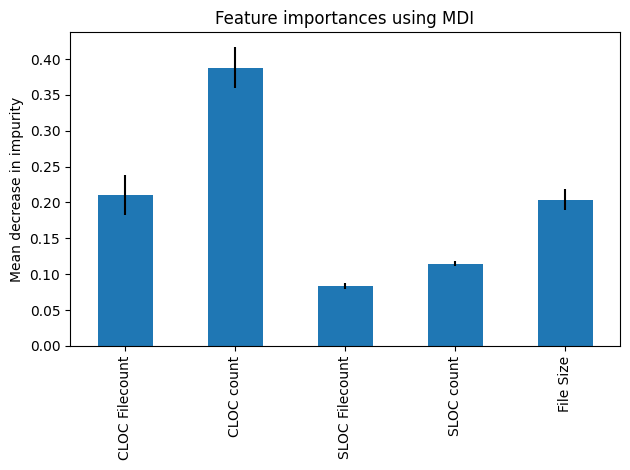

In [ ]:
forest_importances = pd.Series(feature_importance, index=X_resampled.columns)
std = np.std([tree.feature_importances_ for tree in rf_classifier.estimators_], axis=0)
fig, ax = plt.subplots()
forest_importances.plot.bar(yerr=std, ax=ax)
ax.set_title("Feature importances using MDI")
ax.set_ylabel("Mean decrease in impurity")
fig.tight_layout()

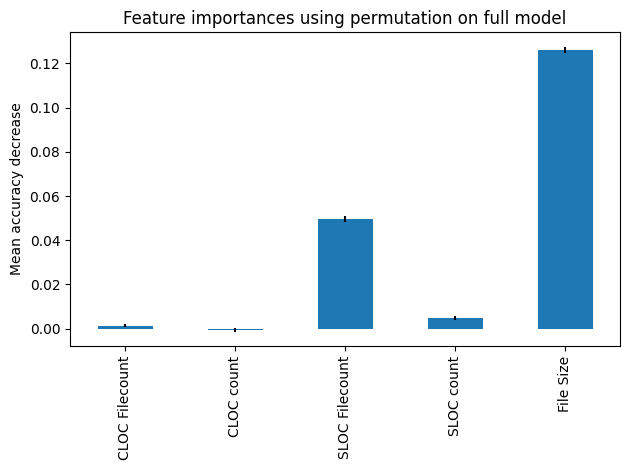

In [ ]:
from sklearn.inspection import permutation_importance

result = permutation_importance(
    rf_classifier, X_test, y_test, n_repeats=10, random_state=42, n_jobs=2
)
forest_importances = pd.Series(result.importances_mean, index=X_resampled.columns)
fig, ax = plt.subplots()
forest_importances.plot.bar(yerr=result.importances_std, ax=ax)
ax.set_title("Feature importances using permutation on full model")
ax.set_ylabel("Mean accuracy decrease")
fig.tight_layout()
plt.show()

In [ ]:
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# Create a Gradient Boosting Classifier
gb_classifier = GradientBoostingClassifier(n_estimators=100, random_state=42)
# Fit the classifier to the data

# Perform cross-validated predictions
y_pred = cross_val_predict(gb_classifier, X_resampled, y_resampled, cv=cv)

# Evaluate the predictions
print("Gradient Boosting Classifier on training data")
print("Accuracy:", accuracy_score(y_resampled, y_pred))
print("Confusion Matrix:\n", confusion_matrix(y_resampled, y_pred))
print("Classification Report:\n", classification_report(y_resampled, y_pred))

gb_classifier.fit(X_resampled, y_resampled)

feature_importance = gb_classifier.feature_importances_
# Assuming 'X' is your feature DataFrame
feature_importance_df = pd.DataFrame({'Feature': X_resampled.columns, 'Importance': feature_importance})
print(feature_importance_df)

Gradient Boosting Classifier on training data
Accuracy: 0.7073741469928819
Confusion Matrix:
 [[ 99522  63724]
 [ 31816 131430]]
Classification Report:
               precision    recall  f1-score   support

       False       0.76      0.61      0.68    163246
        True       0.67      0.81      0.73    163246

    accuracy                           0.71    326492
   macro avg       0.72      0.71      0.70    326492
weighted avg       0.72      0.71      0.70    326492

          Feature  Importance
0  CLOC Filecount    0.108950
1      CLOC count    0.472634
2  SLOC Filecount    0.108495
3      SLOC count    0.035949
4       File Size    0.273971


In [ ]:
from xgboost import XGBClassifier

# Set hyperparameters (optional)
params = {
  'max_depth': 6,  # Maximum depth of decision trees
  'n_estimators': 100,  # Number of boosting iterations
  'learning_rate': 0.1,  # Learning rate for each boosting step
  'objective': 'binary:logistic',  # Objective function for classification (logistic regression)
  'random_state': 42  # Set random seed for reproducibility
}

# Create the XGBoost classifier object
xgb_classifier = XGBClassifier(**params)

# Perform cross-validated predictions
y_pred = cross_val_predict(xgb_classifier, X_resampled, y_resampled, cv=cv)

# Evaluate the predictions
print("XGBoost Classifier on training data")
print("Accuracy:", accuracy_score(y_resampled, y_pred))
print("Confusion Matrix:\n", confusion_matrix(y_resampled, y_pred))
print("Classification Report:\n", classification_report(y_resampled, y_pred))

xgb_classifier.fit(X_resampled, y_resampled)

feature_importance = xgb_classifier.feature_importances_
# Assuming 'X' is your feature DataFrame
feature_importance_df = pd.DataFrame({'Feature': X_resampled.columns, 'Importance': feature_importance})
print(feature_importance_df)

XGBoost Classifier on training data
Accuracy: 0.7646067897528883
Confusion Matrix:
 [[111406  51840]
 [ 25014 138232]]
Classification Report:
               precision    recall  f1-score   support

       False       0.82      0.68      0.74    163246
        True       0.73      0.85      0.78    163246

    accuracy                           0.76    326492
   macro avg       0.77      0.76      0.76    326492
weighted avg       0.77      0.76      0.76    326492

          Feature  Importance
0  CLOC Filecount    0.138172
1      CLOC count    0.338035
2  SLOC Filecount    0.176563
3      SLOC count    0.109135
4       File Size    0.238093


In [ ]:
# Select columns with numerical data
numerical_columns = combined_df.select_dtypes(include=['int', 'float']).columns

# Calculate median for numerical columns
numerical_medians = combined_df[numerical_columns].median()

# Display the median values for numerical columns
print("Median values for numerical columns:")
print(numerical_medians)


Median values for numerical columns:
CLOC Filecount       83.0
CLOC count        17128.0
SLOC Filecount        0.0
SLOC count            0.0
File Size           632.0
dtype: float64
